# Metodologias de ensino no IMPA Tech — análise do questionário

> **O que é usado no artigo:** só a **seção 11** (família de 29 associações; saídas em `tabelas/artigo/`, `figuras/artigo/` e `relatorio_resumo_expandido.md`) e, se o grupo decidir incluí-la, a **seção 12** (análise de conteúdo das sugestões). As seções 01–10 são **exploração interna** (saídas em `*/exploratorio/`) e não alimentam o texto. Ver `README.md`.

Para trocar de modo (`previa` → `final`), altere **apenas** a célula de CONFIG abaixo. Nenhuma outra célula tem n, contagens ou nomes de arquivo fixos.

## 00 · Config

In [1]:
MODO = "final"                      # "previa" | "final"
ARQUIVO = "raw/respostas.csv"   # CSV exportado do UmfrageOnline (sep=';')
INCLUIR_QUASE_COMPLETOS = False      # incluir 'não concluído' com todas as escalas preenchidas?
ALPHA = 0.05
N_MIN_GRUPO = 10                     # abaixo disso: só descritiva, sem teste
N_MIN_CELULA = 5                     # abaixo disso: suprimir contagem em tabelas (privacidade)
ANALISAR_NEURODIVERGENCIA = False    # briefing (15/11/2026): a neurodivergência não é analisada nem cruzada com nenhuma variável
SUPRIMIR_CONTAGEM_TEMAS = True       # seção 12: contagens de 1 a 4 por categoria aparecem como "<5" (decisão do grupo)
N_POPULACAO = 200                    # nº aproximado de alunos (cenários de poder, seção 09)
DELTA_EQUIV = 0.2                    # |efeito| abaixo disso = "sem associação relevante" (seção 05f)
B_BOOT = 5000                        # reamostragens bootstrap (ICs das seções 05a e 05f)


In [2]:
%matplotlib inline
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import utils

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40, "display.width", 200, "display.max_colwidth", 120)
utils.estilo_graficos()
# artigo/ = saídas que alimentam o texto (seções 11 e 12); exploratorio/ = exploração interna (seções 01–10)
for _p in ["figuras/artigo", "figuras/exploratorio", "tabelas/artigo", "tabelas/exploratorio"]:
    os.makedirs(_p, exist_ok=True)
PASTA_IC = "figuras/exploratorio/efeitos_ic_faixa"   # todos os gráficos de efeito + IC95 + faixa ±DELTA_EQUIV
os.makedirs(PASTA_IC, exist_ok=True)

ROTULO = "EXPLORATÓRIO — dados parciais" if MODO == "previa" else "EXPLORATÓRIO"

def mostrar_teste(tabela, titulo, rotulo=ROTULO):
    """Toda tabela de teste sai com o rótulo do modo."""
    display(Markdown(f"**{titulo}** — `{rotulo}`"))
    display(tabela)

print(f"Modo: {MODO}  →  testes não pré-registrados: {ROTULO}")

Modo: final  →  testes não pré-registrados: EXPLORATÓRIO


## 01 · Leitura, anonimização e fluxo da amostra

`utils.carregar` remove IP, Resume-Code, a palavra do sorteio, colunas `Unnamed` e as distratoras (Q4, Q10, Q15, Q19) logo na leitura — essas colunas não existem neste notebook. As colunas são mapeadas pela **posição**, com checagem do cabeçalho.

In [3]:
dados = utils.carregar(ARQUIVO)

proibidas = ["ip", "resume", "sorteio", "unnamed", "q05", "q11", "q16", "q20"]
assert not [c for c in dados.columns if any(p in c.lower() for p in proibidas)]
print(f"{dados.shape[0]} registros, {dados.shape[1]} variáveis após anonimização")
print("\nEstado da participação × consentimento (todos os registros):")
display(pd.crosstab(dados["estado"], dados["q01_consentimento"].fillna("(vazio)"), margins=True))

117 registros, 40 variáveis após anonimização

Estado da participação × consentimento (todos os registros):


q01_consentimento,não,sim,All
estado,,,
participado e completo,1,95,96
"participado, mas ainda não foi concluído",2,19,21
All,3,114,117


In [4]:
df, fluxo = utils.filtrar_amostra(dados, INCLUIR_QUASE_COMPLETOS)
N = len(df)
display(fluxo)
fluxo.to_csv("tabelas/exploratorio/01_fluxo_amostra.csv", index=False)

,Etapa,n
0,Total de registros,117
1,Participação completa,96
2,Completos com consentimento (Q1 = sim),95
3,Amostra final,95


In [5]:
resumo = pd.DataFrame({
    "n válido": df[utils.ESCALAS].notna().sum(), "faltantes": df[utils.ESCALAS].isna().sum(),
    "mín": df[utils.ESCALAS].min(), "máx": df[utils.ESCALAS].max()})
display(resumo)
print(f"Q7 só se aplica a quem fez outra graduação ({df['q08_impacto_grad'].notna().sum()} de {N}); escala 1–5.")
print(f"pergunta de neurodivergência (neurodivergência) respondida por {df['q23_neurodiv'].notna().sum()} de {N} — incluída no meio da coleta.")

,n válido,faltantes,mín,máx
q08_impacto_grad,26,69,1.0,5.0
q12_transicao,95,0,1.0,10.0
q13_expectativa,95,0,1.0,10.0
q14_prereq,95,0,1.0,10.0
q17_aulas,95,0,1.0,10.0
q25_novo,95,0,1.0,10.0
q25_absorveu,95,0,1.0,9.0
q25_monitoria,95,0,1.0,10.0


Q7 só se aplica a quem fez outra graduação (26 de 95); escala 1–5.
pergunta de neurodivergência (neurodivergência) respondida por 54 de 95 — incluída no meio da coleta.


### Interpretação (01)

*Perguntas-guia — a escrever pela aluna:*
- Quantas respostas foram perdidas em cada etapa do fluxo? Alguma perda chama atenção?
- Os incompletos pararam em algum ponto específico do questionário?
- Faz sentido usar `INCLUIR_QUASE_COMPLETOS=True`? Que viés isso poderia introduzir?

## 02 · Perfil da amostra

Contagens entre 1 e `N_MIN_CELULA − 1` aparecem como `<N_MIN_CELULA` (privacidade). Por isso o perfil não tem gráficos.

In [6]:
perfil = {
    "Idade": "q02_idade", "Turma": "q03_turma", "Tempo entre EM e ImpaTech": "q04_ingresso_tempo",
    "Forma de ingresso": "q09_forma_ingresso", "Outra graduação": "q06_outra_grad",
    "Graduação anterior correlata a Exatas": "q07_correlato",
    "Pretende terminar o curso": "q21_terminar", "Trancou/reprovou": "q26_trancou",
}
for titulo, col in perfil.items():
    display(Markdown(f"**{titulo}** (n = {df[col].notna().sum()})"))
    t = utils.frequencias(df[col], N_MIN_CELULA)
    display(t)
    t.to_csv(f"tabelas/exploratorio/02_perfil_{col}.csv")

**Idade** (n = 95)

,n,%
17 - 19 anos,40,42.1
20 - 22 anos,45,47.4
23 - 25 anos,suprimido,—
26+,<5,—


**Turma** (n = 95)

,n,%
Turma 2024,17,17.9
Turma 2025,35,36.8
Turma 2026,43,45.3


**Tempo entre EM e ImpaTech** (n = 95)

,n,%
Imediatamente,63,66.3
Após 1 ano,14,14.7
Após 2 anos,suprimido,—
Após 3 anos,<5,—
Após 4 anos ou mais,9,9.5


... (6 outputs left out)

**Pretende terminar o curso** (n = 95)

,n,%
Não,<5,—
Não tenho certeza,suprimido,—
Sim,81,85.3


**Trancou/reprovou** (n = 95)

,n,%
Não,84,88.4
"Sim, tranquei parcialmente",6,6.3
"Sim, tranquei totalmente",<5,—
"Sim, reprovei por uma matéria e continuo no IMPA Tech",<5,—
"Sim, reprovei por 2 ou mais matérias",<5,—


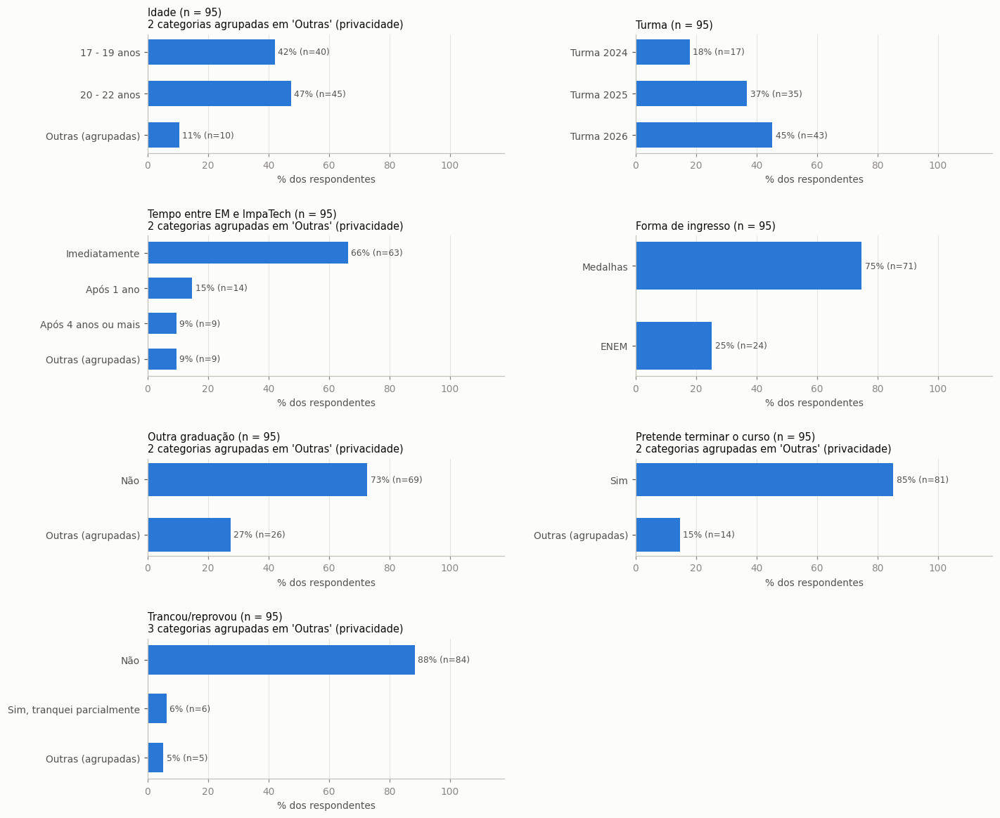

In [7]:
# Gráfico do perfil: categorias com n < N_MIN_CELULA são agrupadas ou omitidas (privacidade)
perfil_graf = {k: v for k, v in perfil.items() if v != "q07_correlato"}
utils.painel_categorias(df, perfil_graf, N_MIN_CELULA, arquivo="figuras/exploratorio/02_perfil.png")
plt.show()

**Escola no Ensino Médio** (pode marcar mais de uma; % sobre N = 95)

,n,%
Escola pública,40,42.1
Escola pública seletiva,46,48.4
Escola privada,13,13.7


Marcaram mais de um tipo de escola: <5


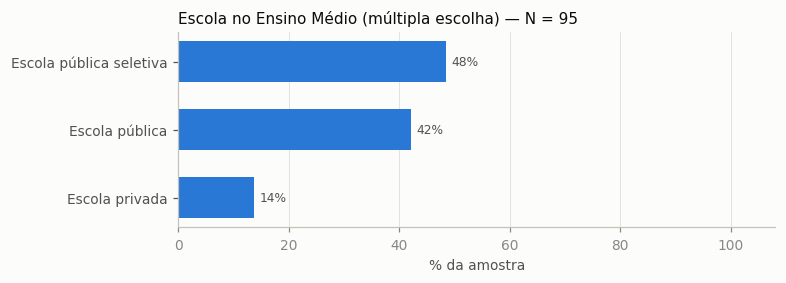

In [8]:
# Q10 — escola no Ensino Médio (múltipla escolha)
esc = df[utils.MULTIPLA["q10"]].sum().rename(index=utils.ROTULOS).to_frame("n")
esc["%"] = (100 * esc["n"] / N).round(1)
display(Markdown(f"**Escola no Ensino Médio** (pode marcar mais de uma; % sobre N = {N})"))
display(utils.suprimir(esc, N_MIN_CELULA))
n_mais = (df[utils.MULTIPLA["q10"]].sum(axis=1) > 1).sum()
print(f"Marcaram mais de um tipo de escola: {n_mais if n_mais == 0 or n_mais >= N_MIN_CELULA else f'<{N_MIN_CELULA}'}")
utils.grafico_barras(esc.loc[esc["n"] >= N_MIN_CELULA, "%"], arquivo="figuras/exploratorio/02_escola.png",
                     titulo=f"Escola no Ensino Médio (múltipla escolha) — N = {N}")
plt.show()

### Interpretação (02)

*Perguntas-guia — a escrever pela aluna:*
- A amostra representa bem as três turmas e as duas formas de ingresso?
- Algum grupo é pequeno demais para ser comparado (ver `N_MIN_GRUPO`)?
- O perfil da amostra é parecido com o perfil conhecido dos alunos do IMPA Tech?

## 03 · Escalas (Likert 0/1–10)

Escalas tratadas como **ordinais**: mediana e IQR são as medidas principais; média e DP vêm como apoio. Atenção ao sentido: em Q11 e Q13, valores altos = **mais dificuldade**.

In [9]:
desc = utils.descrever_likert(df, utils.ESCALAS)
display(desc)
desc.to_csv("tabelas/exploratorio/03_descritivas_escalas.csv")

,n,mediana,Q1,Q3,IQR,média,DP
variável,,,,,,,
Q7 Impacto da graduação anterior (1–5),26,4.0,2.25,4.75,2.5,3.46,1.36
Q11 Dificuldade da transição EM→superior,95,8.0,6.00,9.00,3.0,7.17,2.65
Q12 Expectativa com a Matemática correspondida,95,8.0,6.00,8.50,2.5,7.16,2.10
Q13 Dificuldade com pré-requisitos,95,7.0,3.00,8.00,5.0,5.56,2.95
Q16 Aprendizado atribuído às aulas,95,5.0,3.00,7.00,4.0,4.97,2.29
Q24 Conteúdo novo visto,95,9.0,7.00,10.00,3.0,7.94,2.25
Q24 Quanto sente que absorveu,95,6.0,5.00,7.00,2.0,5.82,1.88
Q24 Quanto as monitorias ajudam,95,4.0,2.00,6.00,4.0,4.25,2.51


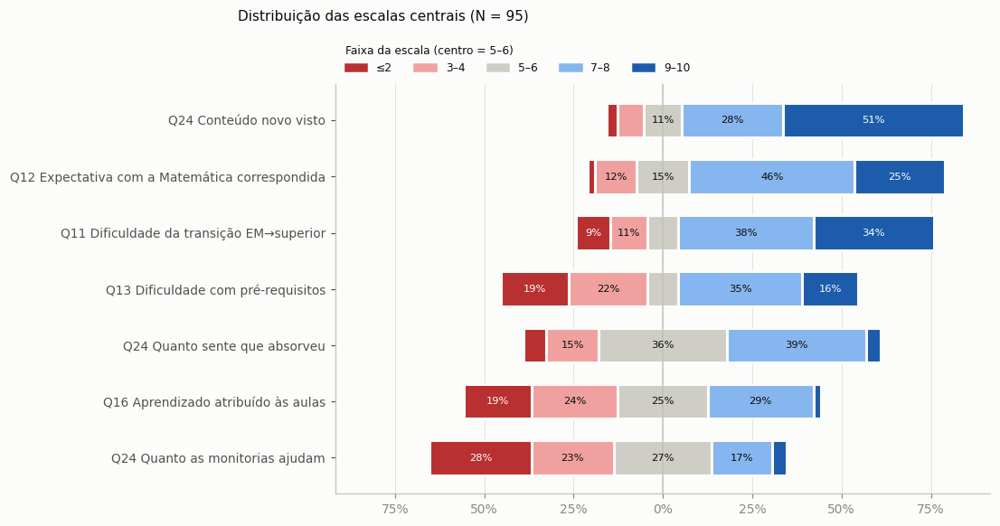

In [10]:
fig = utils.grafico_likert(df, utils.ESCALAS_CENTRAIS, arquivo="figuras/exploratorio/03_likert_divergente.png",
                          titulo=f"Distribuição das escalas centrais (N = {N})")
plt.show()

**Q14 Nº de matérias em que precisou de apoio** (n = 95)

,n,%
Não,37,38.9
1,14,14.7
2,21,22.1
3,10,10.5
4+,13,13.7


**Q17 Uso de IA pelo ritmo do curso** (n = 95)

,n,%
Não,<5,—
"Sim, usei algumas vezes",suprimido,—
"Sim, sempre uso",59,62.1


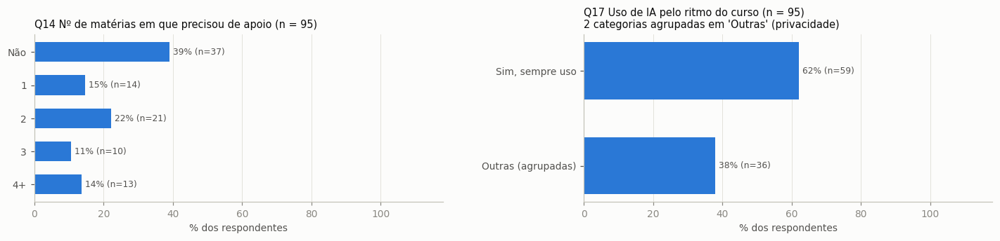

In [11]:
for col in ["q15_apoio", "q18_ia"]:
    display(Markdown(f"**{utils.ROTULOS[col]}** (n = {df[col].notna().sum()})"))
    display(utils.frequencias(df[col], N_MIN_CELULA))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
utils.grafico_categorias(df["q15_apoio"], N_MIN_CELULA, utils.ROTULOS["q15_apoio"], ax=axes[0])
utils.grafico_categorias(df["q18_ia"], N_MIN_CELULA, utils.ROTULOS["q18_ia"], ax=axes[1])
fig.tight_layout(w_pad=4); fig.savefig("figuras/exploratorio/03_apoio_ia.png"); plt.show()

### Interpretação (03)

*Perguntas-guia — a escrever pela aluna:*
- Quais escalas têm mediana mais alta e mais baixa? O que isso diz sobre a experiência dos alunos?
- Há escalas com dispersão grande (IQR alto), sugerindo experiências muito diferentes entre alunos?
- Como "conteúdo novo visto" se relaciona, descritivamente, com "quanto sente que absorveu"?
- O que a distribuição de uso de IA (Q17) sugere sobre o ritmo do curso?

## 04 · Múltipla escolha — desafios (Q18) e métodos de estudo (Q23)

Vazio = não marcou (0). % calculado sobre a amostra final.

**Principais desafios na vida acadêmica (Q18)**

,n,%
Gerenciar tempo,81,85.3
Organização de estudos,61,64.2
Tarefas de casa,30,31.6


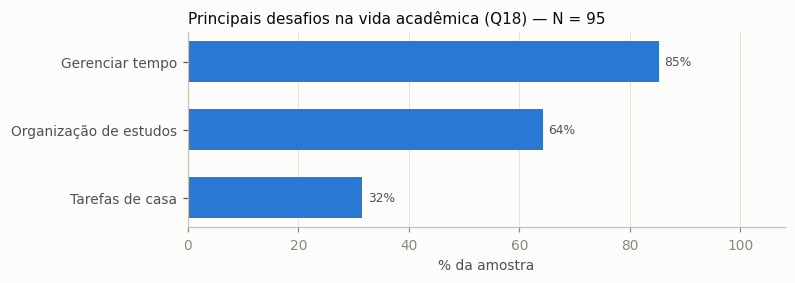

Nº de opções marcadas por pessoa: mediana 2, mín 0, máx 3; marcaram nenhuma: 6


**Métodos de estudo mais usados (Q23)**

,n,%
"Prática, exercícios e listas",84,88.4
"Leitura, anotação, resumos",74,77.9
Perguntar a uma IA,68,71.6
Cronograma/plano de estudos,23,24.2
Videoaulas,18,18.9
Grupos de estudos,17,17.9
Método Pomodoro,8,8.4


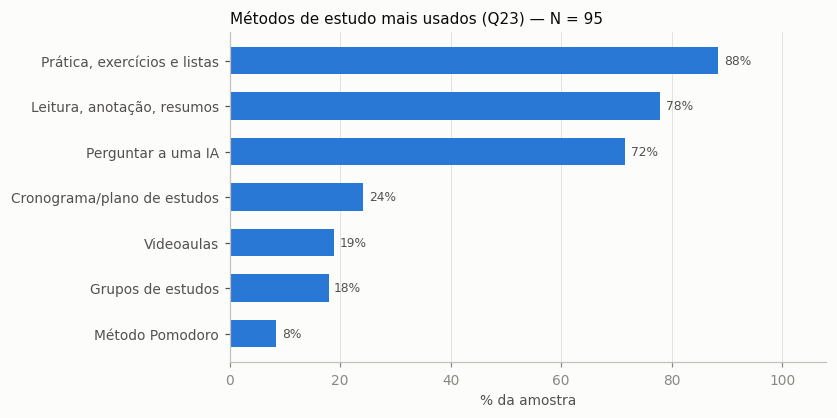

Nº de opções marcadas por pessoa: mediana 3, mín 0, máx 6; marcaram nenhuma: <5
Responderam 'Outro' em Q18: 9; em Q23: <5 (ver seção 07)


In [12]:
for q, titulo, arq in [("q19", "Principais desafios na vida acadêmica (Q18)", "04_desafios_q18.png"),
                       ("q24", "Métodos de estudo mais usados (Q23)", "04_metodos_q23.png")]:
    contagem = df[utils.MULTIPLA[q]].sum()
    prop = 100 * df[utils.MULTIPLA[q]].mean()
    pequenas = (contagem > 0) & (contagem < N_MIN_CELULA)
    tab = pd.DataFrame({"n": contagem, "%": prop.round(1)}).sort_values("n", ascending=False).astype(object)
    tab.loc[pequenas, ["n", "%"]] = [f"<{N_MIN_CELULA}", "—"]   # múltipla escolha: sem total fixo, basta a primária
    display(Markdown(f"**{titulo}**")); display(tab.rename(index=utils.ROTULOS))
    nota = f" · {pequenas.sum()} opção(ões) com n < {N_MIN_CELULA} omitida(s)" if pequenas.any() else ""
    utils.grafico_barras(prop[~pequenas], arquivo=f"figuras/exploratorio/{arq}", titulo=f"{titulo} — N = {N}{nota}")
    plt.show()
    qtd = df[utils.MULTIPLA[q]].sum(axis=1)
    print(f"Nº de opções marcadas por pessoa: mediana {qtd.median():.0f}, "
          f"mín {qtd.min()}, máx {qtd.max()}; marcaram nenhuma: {(lambda k: k if k == 0 or k >= N_MIN_CELULA else f'<{N_MIN_CELULA}')((qtd == 0).sum())}")
_sup = lambda k: k if k == 0 or k >= N_MIN_CELULA else f"<{N_MIN_CELULA}"
print(f"Responderam 'Outro' em Q18: {_sup(df['q19_outro_txt'].notna().sum())}; "
      f"em Q23: {_sup(df['q24_outro_txt'].notna().sum())} (ver seção 07)")

### Interpretação (04)

*Perguntas-guia — a escrever pela aluna:*
- Qual desafio é mais citado? Isso é coerente com as sugestões abertas (seção 07)?
- Quais métodos de estudo predominam? "Perguntar a uma IA" aparece com que peso em relação aos demais?
- Há métodos quase ausentes? Por que poderiam ser pouco usados nesse contexto?

## 05 · Comparações entre grupos

**Regras:** 2 grupos → Mann-Whitney U + r (|Z|/√N); 3+ grupos → Kruskal-Wallis + ε² e, se significativo, Dunn. Cada agrupamento é uma família de 7 testes (as escalas centrais) com correção de **Holm**; p bruto e ajustado lado a lado. Grupos com n < `N_MIN_GRUPO` não são testados.

### 05a · Hipóteses

As hipóteses de `HIPOTESES` estão em `docs/hipoteses.md`. O estudo é **exploratório**: elas são testadas **com todas as respostas juntas**, sem separar as que chegaram antes e depois da prévia. Como foram formuladas olhando a prévia, os resultados descrevem esta amostra e ficam como hipóteses para estudos futuros; não confirmam nada. Nada desta seção entra no artigo.

**Como cada hipótese é testada**
- **Direção:** `"+"` / `"-"` são testes unilaterais na direção prevista; `"0"` é um teste de equivalência (o efeito está dentro de ±`DELTA_EQUIV`, por TOST bootstrap); `"±"` é bilateral.
- **Teste e efeito:** grupo (linha do mapa 05d) × escala usa Mann-Whitney, com efeito r_rb (> 0: o grupo da linha tem valores maiores). Escala × escala ou turma × escala usa Spearman ρ.
- **Correção de Holm:** é aplicada dentro de cada família:
  - **principal:** o que a prévia já indicava (Holm ou indício);
  - **secundária:** o que ficou inconclusivo;
  - **ausência:** as hipóteses de "sem relação".
- **Grupos pequenos:** grupos com n < `N_MIN_GRUPO` não são testados.

A hipótese 28 do `docs/hipoteses.md` (aulas favorecem leitura mais que grupos de estudo) compara dois efeitos que dependem das mesmas pessoas. Ela não vira um teste único aqui: os dois efeitos aparecem nas hipóteses 30/34 e no mapa.


In [13]:
# Agrupamentos derivados (definidos pelas categorias, não por contagens)
def binario(col, cond, sim, nao):
    """Rótulo `sim` onde cond, `nao` onde não; faltante continua faltante."""
    return pd.Series(np.where(cond, sim, nao), index=df.index).where(df[col].notna())

df["g_ingresso"] = df["q09_forma_ingresso"]
df["g_turma"] = df["q03_turma"].cat.remove_unused_categories()
df["g_idade"] = binario("q02_idade", df["q02_idade"] == "17 - 19 anos", "17–19 anos", "20+ anos")
df["g_tempo"] = binario("q04_ingresso_tempo", df["q04_ingresso_tempo"] == "Imediatamente", "Imediatamente", "Após ≥ 1 ano")
df["g_outra_grad"] = binario("q06_outra_grad", df["q06_outra_grad"].str.startswith("Sim"), "Iniciou outra graduação", "Não iniciou")
df["g_escola"] = binario("q10_privada", df["q10_privada"] == 1, "Alguma escola privada", "Só escola pública")
df["g_ia"] = binario("q18_ia", df["q18_ia"] == "Sim, sempre uso", "Sempre usa IA", "Às vezes / não usa")
df["g_apoio"] = binario("q15_apoio", df["q15_apoio"] != "Não", "Precisou de apoio", "Não precisou de apoio")
df["g_terminar"] = binario("q21_terminar", df["q21_terminar"] == "Sim", "Pretende terminar", "Não / não tem certeza")
df["g_trancou"] = binario("q26_trancou", df["q26_trancou"] != "Não", "Trancou/reprovou", "Não trancou/reprovou")
AGRUPAMENTOS = {
    "Forma de ingresso": "g_ingresso", "Turma": "g_turma", "Idade": "g_idade",
    "Tempo entre EM e ImpaTech": "g_tempo", "Outra graduação": "g_outra_grad",
    "Escola no EM": "g_escola", "Uso de IA (Q17)": "g_ia",
    "Pretende terminar (Q20)": "g_terminar", "Trancou/reprovou (Q25)": "g_trancou",
}
tam = pd.DataFrame([{"agrupamento": nome, "grupo": k, "n": int(v)}
                    for nome, g in AGRUPAMENTOS.items() for k, v in df[g].value_counts().items()])
tam["testável"] = np.where(tam.groupby("agrupamento")["n"].transform("min") >= N_MIN_GRUPO, "sim", "não (n < N_MIN_GRUPO)")
display(utils.suprimir(tam.set_index(["agrupamento", "grupo"]), N_MIN_CELULA, ["n"]))

# Linhas do mapa 05d: usadas também pelas hipóteses (05a)
df["q15_apoio_ord"] = utils.codificar_ordinal(df["q15_apoio"])
df["q18_ia_ord"] = utils.codificar_ordinal(df["q18_ia"])
DESFECHOS_MAPA = utils.ESCALAS_CENTRAIS + ["q15_apoio_ord", "q18_ia_ord"]

# Cada linha: ("binario", coluna, valor que conta como 1) ou ("ordinal", coluna).
# O rótulo diz qual grupo é o "positivo": r_rb > 0 => esse grupo tem valores maiores.
LINHAS_MAPA = {
    "Ingresso: ENEM (vs Medalhas)":          ("binario", "g_ingresso", "ENEM"),
    "Iniciou outra graduação (completa ou não)": ("binario", "g_outra_grad", "Iniciou outra graduação"),
    "Estudou em escola privada":             ("binario", "g_escola", "Alguma escola privada"),
    "Entrou ≥ 1 ano após o EM":              ("binario", "g_tempo", "Após ≥ 1 ano"),
    "Idade 20+ (vs 17–19)":                  ("binario", "g_idade", "20+ anos"),
    "Turma (2024 → 2026)":                   ("ordinal", "g_turma"),
    "Sempre usa IA":                         ("binario", "g_ia", "Sempre usa IA"),
    "Precisou de apoio":                     ("binario", "g_apoio", "Precisou de apoio"),
    "Não/incerto sobre terminar":            ("binario", "g_terminar", "Não / não tem certeza"),
    "Trancou/reprovou":                      ("binario", "g_trancou", "Trancou/reprovou"),
}
for col in utils.MULTIPLA["q19"] + utils.MULTIPLA["q24"]:
    pref = "Desafio" if col.startswith("q19") else "Método"
    LINHAS_MAPA[f"{pref}: {utils.ROTULOS[col]}"] = ("binario", col, 1)

# Pares redundantes (mesma pergunta dos dois lados) não são calculados.
EXCLUIR_MAPA = {("Sempre usa IA", "q18_ia_ord"), ("Precisou de apoio", "q15_apoio_ord")}

n testável
agrupamento               grupo                               
Forma de ingresso         Medalhas                 71      sim
                          ENEM                     24      sim
Turma                     Turma 2026               43      sim
                          Turma 2025               35      sim
                          Turma 2024               17      sim
Idade                     20+ anos                 55      sim
                          17–19 anos               40      sim
Tempo entre EM e ImpaTech Imediatamente            63      sim
                          Após ≥ 1 ano             32      sim
Outra graduação           Não iniciou              69      sim
                          Iniciou outra graduação  26      sim
Escola no EM              Só escola pública        82      sim
                          Alguma escola privada    13      sim
Uso de IA (Q17)           Sempre usa IA            59      sim
                          Às vezes / não usa       36      sim
Pretende terminar (Q20)   Pretende terminar        81      sim
                          Não / não tem certeza    14      sim
Trancou/reprovou (Q25)    Não trancou/reprovou     84      sim
                          Trancou/reprovou         11      sim

In [14]:
# Hipóteses (docs/hipoteses.md). x = linha do mapa 05d ou coluna; y = escala; sinal = direção prevista.
P, S, A = "principal", "secundária", "ausência"
HIPOTESES = [
    # A. Pré-requisitos, transição e apoio
    {"id": "H01", "x": "q14_prereq", "y": "q15_apoio_ord", "sinal": "+", "familia": P, "texto": "Mais dificuldade com pré-requisitos → apoio em mais matérias"},
    {"id": "H02", "x": "q12_transicao", "y": "q15_apoio_ord", "sinal": "+", "familia": P, "texto": "Transição mais difícil → apoio em mais matérias"},
    {"id": "H03", "x": "q14_prereq", "y": "q25_novo", "sinal": "+", "familia": P, "texto": "Mais dificuldade com pré-requisitos → mais conteúdo novo"},
    {"id": "H04", "x": "Precisou de apoio", "y": "q25_novo", "sinal": "+", "familia": P, "texto": "Precisou de apoio → mais conteúdo novo"},
    {"id": "H05", "x": "Precisou de apoio", "y": "q17_aulas", "sinal": "+", "familia": P, "texto": "Precisou de apoio → atribui mais aprendizado às aulas"},
    {"id": "H06", "x": "Precisou de apoio", "y": "q25_monitoria", "sinal": "+", "familia": P, "texto": "Precisou de apoio → monitorias ajudam mais"},
    {"id": "H07", "x": "Desafio: Tarefas de casa", "y": "q15_apoio_ord", "sinal": "+", "familia": P, "texto": "Desafio tarefas de casa → apoio em mais matérias"},
    {"id": "H08", "x": "Desafio: Tarefas de casa", "y": "q13_expectativa", "sinal": "-", "familia": P, "texto": "Desafio tarefas de casa → expectativa menos correspondida"},
    {"id": "H09", "x": "Desafio: Tarefas de casa", "y": "q14_prereq", "sinal": "+", "familia": S, "texto": "Desafio tarefas de casa → mais dificuldade com pré-requisitos"},
    {"id": "H10", "x": "Desafio: Gerenciar tempo", "y": "q14_prereq", "sinal": "+", "familia": S, "texto": "Desafio gerenciar tempo → mais dificuldade com pré-requisitos"},
    {"id": "H11", "x": "Desafio: Gerenciar tempo", "y": "q15_apoio_ord", "sinal": "+", "familia": S, "texto": "Desafio gerenciar tempo → apoio em mais matérias"},
    # B. Uso de IA
    {"id": "H12", "x": "Sempre usa IA", "y": "q15_apoio_ord", "sinal": "+", "familia": P, "texto": "Sempre usa IA → apoio em mais matérias"},
    {"id": "H13", "x": "Sempre usa IA", "y": "q14_prereq", "sinal": "+", "familia": P, "texto": "Sempre usa IA → mais dificuldade com pré-requisitos"},
    {"id": "H14", "x": "Sempre usa IA", "y": "q12_transicao", "sinal": "+", "familia": P, "texto": "Sempre usa IA → transição mais difícil"},
    {"id": "H15", "x": "Sempre usa IA", "y": "q25_novo", "sinal": "+", "familia": P, "texto": "Sempre usa IA → mais conteúdo novo"},
    {"id": "H16", "x": "Desafio: Organização de estudos", "y": "q18_ia_ord", "sinal": "+", "familia": P, "texto": "Desafio organização → usa mais IA"},
    {"id": "H17", "x": "Sempre usa IA", "y": "q25_absorveu", "sinal": "-", "familia": P, "texto": "Sempre usa IA → sente que absorveu menos"},
    {"id": "H18", "x": "Desafio: Gerenciar tempo", "y": "q18_ia_ord", "sinal": "+", "familia": S, "texto": "Desafio gerenciar tempo → usa mais IA"},
    {"id": "H19", "x": "Método: Leitura, anotação, resumos", "y": "q18_ia_ord", "sinal": "+", "familia": S, "texto": "Método leitura/resumos → usa mais IA"},
    {"id": "H20", "x": "Método: Perguntar a uma IA", "y": "q15_apoio_ord", "sinal": "+", "familia": S, "texto": "Método perguntar à IA → apoio em mais matérias"},
    {"id": "H21", "x": "Desafio: Tarefas de casa", "y": "q18_ia_ord", "sinal": "+", "familia": S, "texto": "Desafio tarefas de casa → usa mais IA"},
    {"id": "H22", "x": "Sempre usa IA", "y": "q17_aulas", "sinal": "0", "familia": A, "texto": "Sempre usar IA não se relaciona com o aprendizado atribuído às aulas"},
    {"id": "H23", "x": "Turma (2024 → 2026)", "y": "q18_ia_ord", "sinal": "0", "familia": A, "texto": "A turma não se relaciona com o uso de IA"},
    {"id": "H24", "x": "Método: Perguntar a uma IA", "y": "q18_ia_ord", "sinal": "+", "familia": P, "texto": "Método perguntar à IA → usa IA com mais frequência"},
    # C. Métodos de estudo
    {"id": "H25", "x": "Método: Grupos de estudos", "y": "q14_prereq", "sinal": "+", "familia": P, "texto": "Grupos de estudo → mais dificuldade com pré-requisitos"},
    {"id": "H26", "x": "Método: Grupos de estudos", "y": "q12_transicao", "sinal": "+", "familia": P, "texto": "Grupos de estudo → transição mais difícil"},
    {"id": "H27", "x": "Método: Grupos de estudos", "y": "q25_monitoria", "sinal": "+", "familia": P, "texto": "Grupos de estudo → monitorias ajudam mais"},
    {"id": "H29", "x": "Método: Grupos de estudos", "y": "q25_absorveu", "sinal": "+", "familia": S, "texto": "Grupos de estudo → sente que absorve mais"},
    {"id": "H30", "x": "Método: Leitura, anotação, resumos", "y": "q13_expectativa", "sinal": "-", "familia": P, "texto": "Método leitura/resumos → expectativa menos correspondida"},
    {"id": "H31", "x": "Método: Cronograma/plano de estudos", "y": "q14_prereq", "sinal": "+", "familia": P, "texto": "Cronograma → mais dificuldade com pré-requisitos"},
    {"id": "H32", "x": "Método: Cronograma/plano de estudos", "y": "q15_apoio_ord", "sinal": "+", "familia": S, "texto": "Cronograma → apoio em mais matérias"},
    {"id": "H33", "x": "Método: Prática, exercícios e listas", "y": "q15_apoio_ord", "sinal": "+", "familia": S, "texto": "Prática/exercícios → apoio em mais matérias"},
    {"id": "H34", "x": "Desafio: Gerenciar tempo", "y": "q17_aulas", "sinal": "+", "familia": P, "texto": "Desafio gerenciar tempo → atribui mais aprendizado às aulas"},
    # D. Dificuldade de organizar os estudos
    {"id": "H35", "x": "Desafio: Organização de estudos", "y": "q13_expectativa", "sinal": "+", "familia": P, "texto": "Desafio organização → expectativa mais correspondida"},
    {"id": "H36", "x": "Desafio: Organização de estudos", "y": "q15_apoio_ord", "sinal": "+", "familia": P, "texto": "Desafio organização → apoio em mais matérias"},
    {"id": "H37", "x": "Desafio: Organização de estudos", "y": "q25_absorveu", "sinal": "-", "familia": P, "texto": "Desafio organização → sente que absorveu menos"},
    {"id": "H38", "x": "Desafio: Organização de estudos", "y": "q14_prereq", "sinal": "+", "familia": S, "texto": "Desafio organização → mais dificuldade com pré-requisitos"},
    {"id": "H39", "x": "Desafio: Organização de estudos", "y": "q12_transicao", "sinal": "+", "familia": S, "texto": "Desafio organização → transição mais difícil"},
    # E. Trajetória antes do IMPA Tech
    {"id": "H40", "x": "Ingresso: ENEM (vs Medalhas)", "y": "q14_prereq", "sinal": "+", "familia": S, "texto": "ENEM → mais dificuldade com pré-requisitos"},
    {"id": "H41", "x": "Ingresso: ENEM (vs Medalhas)", "y": "q25_novo", "sinal": "+", "familia": S, "texto": "ENEM → mais conteúdo novo"},
    {"id": "H42", "x": "Ingresso: ENEM (vs Medalhas)", "y": "q12_transicao", "sinal": "+", "familia": S, "texto": "ENEM → transição mais difícil"},
    {"id": "H43", "x": "Entrou ≥ 1 ano após o EM", "y": "q12_transicao", "sinal": "-", "familia": P, "texto": "Entrou ≥ 1 ano após o EM → transição menos difícil"},
    {"id": "H44", "x": "Entrou ≥ 1 ano após o EM", "y": "q17_aulas", "sinal": "-", "familia": P, "texto": "Entrou ≥ 1 ano após o EM → atribui menos aprendizado às aulas"},
    {"id": "H45", "x": "Entrou ≥ 1 ano após o EM", "y": "q25_monitoria", "sinal": "-", "familia": P, "texto": "Entrou ≥ 1 ano após o EM → monitorias ajudam menos"},
    {"id": "H46", "x": "Iniciou outra graduação (completa ou não)", "y": "q12_transicao", "sinal": "-", "familia": S, "texto": "Outra graduação → transição menos difícil"},
    {"id": "H47a", "x": "Iniciou outra graduação (completa ou não)", "y": "q25_novo", "sinal": "-", "familia": S, "texto": "Outra graduação → menos conteúdo novo"},
    {"id": "H47b", "x": "Iniciou outra graduação (completa ou não)", "y": "q14_prereq", "sinal": "-", "familia": S, "texto": "Outra graduação → menos dificuldade com pré-requisitos"},
    {"id": "H48", "x": "Iniciou outra graduação (completa ou não)", "y": "q25_monitoria", "sinal": "-", "familia": S, "texto": "Outra graduação → monitorias ajudam menos"},
    {"id": "H49", "x": "Iniciou outra graduação (completa ou não)", "y": "q15_apoio_ord", "sinal": "0", "familia": A, "texto": "Outra graduação não se relaciona com o nº de matérias com apoio"},
    {"id": "H50", "x": "Estudou em escola privada", "y": "q14_prereq", "sinal": "0", "familia": A, "texto": "Escola privada não se relaciona com a dificuldade com pré-requisitos"},
    {"id": "H51", "x": "Turma (2024 → 2026)", "y": "q15_apoio_ord", "sinal": "0", "familia": A, "texto": "A turma não se relaciona com o nº de matérias com apoio"},
    {"id": "H52", "x": "Turma (2024 → 2026)", "y": "q25_monitoria", "sinal": "0", "familia": A, "texto": "A turma não se relaciona com o quanto as monitorias ajudam"},
]
_inval = [h["id"] for h in HIPOTESES if h["x"] not in LINHAS_MAPA and h["x"] not in df.columns or h["y"] not in df.columns]
assert not _inval, f"Hipóteses com variável inexistente: {_inval}"
print(f"{len(HIPOTESES)} hipóteses: " + ", ".join(f"{f} = {sum(h['familia'] == f for h in HIPOTESES)}" for f in (P, S, A)))

52 hipóteses: principal = 27, secundária = 19, ausência = 6


**Hipóteses H01–H52 — todas as respostas (N = 95); Holm dentro de cada família** — `EXPLORATÓRIO`

,família,hipótese,sinal,medida,n_grupo,n_resto,efeito,ic95_inf,ic95_sup,p,p_holm,resultado,teste
id,,,,,,,,,,,,,
H01,principal,Mais dificuldade com pré-requisitos → apoio em mais matérias,+,ρ,95,NaN,0.607844,0.449582,0.738065,0.0,0.0,sobrevive a Holm,Spearman unilateral
H02,principal,Transição mais difícil → apoio em mais matérias,+,ρ,95,NaN,0.432518,0.23791,0.608727,0.000006,0.000156,sobrevive a Holm,Spearman unilateral
H03,principal,Mais dificuldade com pré-requisitos → mais conteúdo novo,+,ρ,95,NaN,0.374106,0.183919,0.554257,0.000094,0.002256,sobrevive a Holm,Spearman unilateral
H04,principal,Precisou de apoio → mais conteúdo novo,+,r_rb,58,37.0,0.287046,0.061964,0.500466,0.007967,0.10357,não sobrevive a Holm,Mann-Whitney U unilateral
H05,principal,Precisou de apoio → atribui mais aprendizado às aulas,+,r_rb,58,37.0,0.26561,0.027947,0.500466,0.014214,0.116535,não sobrevive a Holm,Mann-Whitney U unilateral
H06,principal,Precisou de apoio → monitorias ajudam mais,+,r_rb,58,37.0,0.354613,0.126281,0.564783,0.001672,0.031763,sobrevive a Holm,Mann-Whitney U unilateral
H07,principal,Desafio tarefas de casa → apoio em mais matérias,+,r_rb,30,65.0,0.310256,0.073846,0.52359,0.005928,0.094856,não sobrevive a Holm,Mann-Whitney U unilateral
H08,principal,Desafio tarefas de casa → expectativa menos correspondida,-,r_rb,30,65.0,-0.261538,-0.501538,-0.012821,0.019223,0.13456,não sobrevive a Holm,Mann-Whitney U unilateral
H09,secundária,Desafio tarefas de casa → mais dificuldade com pré-requisitos,+,r_rb,30,65.0,0.220513,-0.028205,0.446154,0.041571,0.623571,não sobrevive a Holm,Mann-Whitney U unilateral


resultado,não sobrevive a Holm,não sobrevive a Holm (IC sai de ±Δ),sobrevive a Holm
família,,,
ausência,0,6,0
principal,18,0,9
secundária,19,0,0


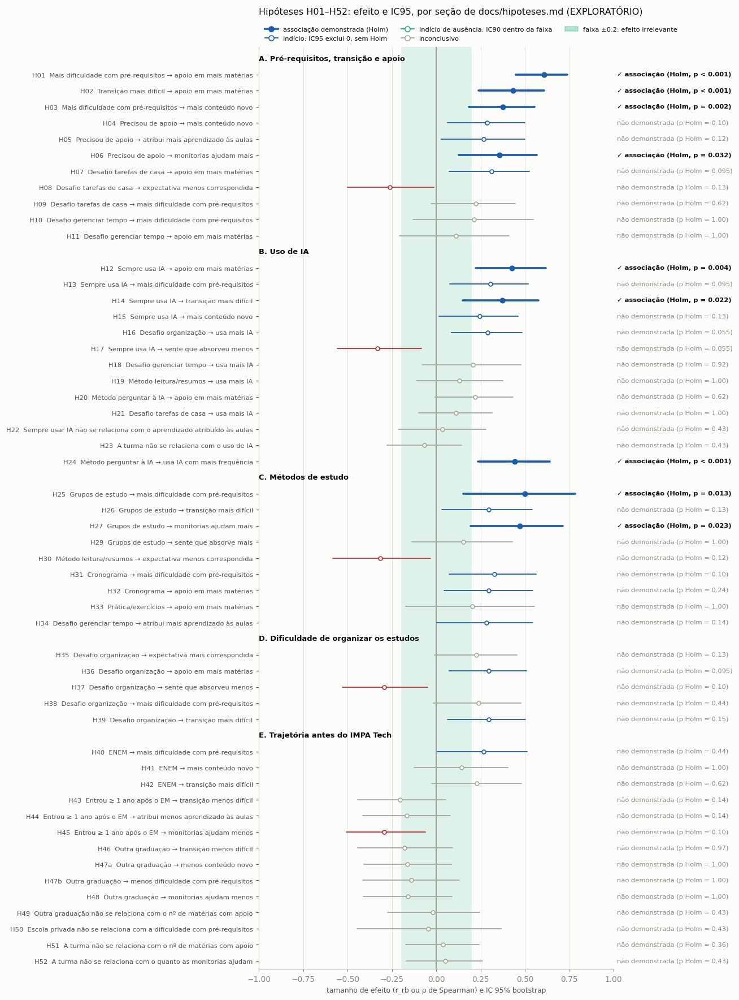

In [15]:
COLS_HIP = ["família", "hipótese", "sinal", "medida", "n_grupo", "n_resto", "efeito", "ic95_inf", "ic95_sup",
            "p", "p_holm", "resultado", "teste"]

def resultado(t):
    """Texto do resultado, na direção prevista (o p já é unilateral/equivalência). Exploratório: não se fala em "confirmada"."""
    sim, nao = "sobrevive a Holm", "não sobrevive a Holm"
    def f(r):
        if pd.isna(r.p):
            return "não testado"
        if r.p_holm < ALPHA:
            return sim
        if r.sinal == "0":
            return f"{nao} (IC sai de ±Δ)" if (r.ic95_inf <= -DELTA_EQUIV or r.ic95_sup >= DELTA_EQUIV) else nao
        contra = (r.sinal == "+" and r.ic95_sup < 0) or (r.sinal == "-" and r.ic95_inf > 0)
        return "direção contrária" if contra else nao
    return t.assign(resultado=[f(r) for r in t.itertuples()])

# Todas as respostas juntas (estudo exploratório)
tab_hip = resultado(utils.testar_hipoteses(df, HIPOTESES, LINHAS_MAPA, N_MIN_GRUPO, DELTA_EQUIV, B=B_BOOT))

def exibir_hip(t, titulo, rotulo):
    t = utils.suprimir(t[COLS_HIP].copy(), N_MIN_CELULA, ["n_grupo", "n_resto"])
    mostrar_teste(t.round(3), titulo, rotulo)
    display(t.groupby(["família", "resultado"]).size().unstack(fill_value=0))

exibir_hip(tab_hip, f"Hipóteses H01–H52 — todas as respostas (N = {N}); Holm dentro de cada família", ROTULO)

# Grupos = seções de docs/hipoteses.md (A: 1–11, B: 12–24, C: 25–34, D: 35–39, E: 40–52)
SECOES_HIP = {"A": range(1, 12), "B": range(12, 25), "C": range(25, 35), "D": range(35, 40), "E": range(40, 53)}
GRUPO_HIP = {h["id"]: utils.GRUPOS_TEMA[next(k for k, r in SECOES_HIP.items() if int(h["id"][1:3]) in r)]
             for h in HIPOTESES}
utils.grafico_ic(utils.ic_hipoteses({"": tab_hip}, GRUPO_HIP, ALPHA), DELTA_EQUIV, list(utils.GRUPOS_TEMA.values()),
                 ordenar=False, arquivo=f"{PASTA_IC}/01_hipoteses_H01-H52.png",
                 titulo=f"Hipóteses H01–H52: efeito e IC95, por seção de docs/hipoteses.md ({ROTULO})")
plt.show()
utils.suprimir(tab_hip[COLS_HIP].copy(), N_MIN_CELULA, ["n_grupo", "n_resto"]).round(4).to_csv("tabelas/exploratorio/05a_hipoteses.csv")

### 05b · Comparações exploratórias (escalas centrais × agrupamentos)

**Forma de ingresso — família de 7 testes, Holm** — `EXPLORATÓRIO`

,Medalhas: n,Medalhas: Md [IQR],ENEM: n,ENEM: Md [IQR],teste,estat,p,p_holm,sig,efeito,medida
desfecho,,,,,,,,,,,
Q11 Dificuldade da transição EM→superior,71,8.0 [6.0–9.0],24,8.0 [7.8–10.0],Mann-Whitney U,656.5,0.0897,0.5383,,0.175,r
Q12 Expectativa com a Matemática correspondida,71,8.0 [6.0–8.5],24,7.5 [6.0–8.2],Mann-Whitney U,884.5,0.7807,1.0,,0.029,r
Q13 Dificuldade com pré-requisitos,71,5.0 [3.0–8.0],24,7.0 [5.0–9.0],Mann-Whitney U,626.0,0.0513,0.3594,,0.2,r
Q16 Aprendizado atribuído às aulas,71,5.0 [4.0–7.0],24,5.0 [3.0–7.0],Mann-Whitney U,910.0,0.6192,1.0,,0.051,r
Q24 Conteúdo novo visto,71,8.0 [7.0–10.0],24,9.0 [7.0–10.0],Mann-Whitney U,730.5,0.2871,1.0,,0.11,r
Q24 Quanto sente que absorveu,71,6.0 [5.0–7.0],24,6.0 [5.0–7.0],Mann-Whitney U,879.0,0.8176,1.0,,0.024,r
Q24 Quanto as monitorias ajudam,71,4.0 [2.0–6.0],24,4.0 [1.8–6.0],Mann-Whitney U,857.0,0.9689,1.0,,0.004,r


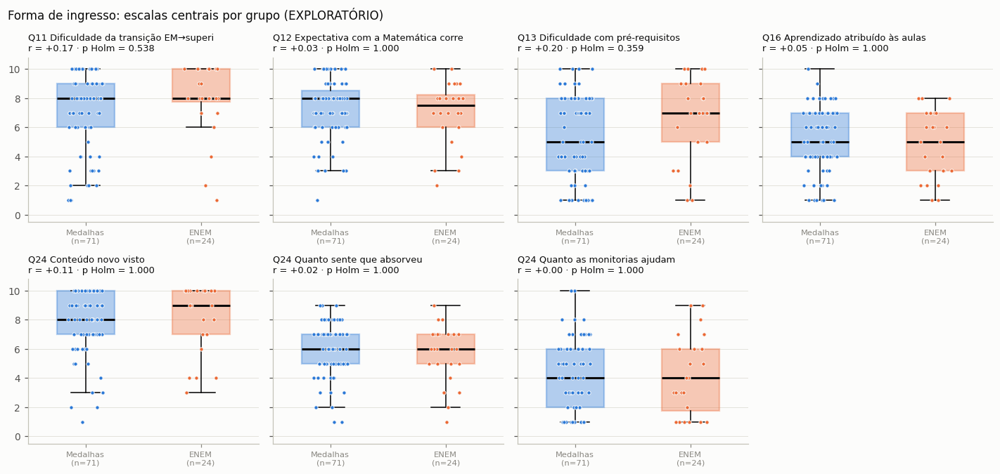

**Turma — família de 7 testes, Holm** — `EXPLORATÓRIO`

,Turma 2024: n,Turma 2024: Md [IQR],Turma 2025: n,Turma 2025: Md [IQR],Turma 2026: n,Turma 2026: Md [IQR],teste,estat,p,p_holm,sig,efeito,medida
desfecho,,,,,,,,,,,,,
Q11 Dificuldade da transição EM→superior,17,7.0 [2.0–8.0],35,8.0 [6.5–9.0],43,8.0 [7.0–9.5],Kruskal-Wallis,5.07,0.0793,0.5057,,0.054,ε²
Q12 Expectativa com a Matemática correspondida,17,8.0 [8.0–9.0],35,7.0 [6.5–8.0],43,8.0 [6.0–9.0],Kruskal-Wallis,4.11,0.1283,0.6413,,0.044,ε²
Q13 Dificuldade com pré-requisitos,17,3.0 [2.0–6.0],35,7.0 [3.0–8.0],43,7.0 [4.0–8.0],Kruskal-Wallis,5.26,0.0722,0.5057,,0.056,ε²
Q16 Aprendizado atribuído às aulas,17,6.0 [2.0–7.0],35,6.0 [4.0–7.0],43,4.0 [3.0–6.0],Kruskal-Wallis,1.81,0.4044,1.0,,0.019,ε²
Q24 Conteúdo novo visto,17,8.0 [7.0–9.0],35,9.0 [7.5–10.0],43,8.0 [6.5–10.0],Kruskal-Wallis,1.96,0.3756,1.0,,0.021,ε²
Q24 Quanto sente que absorveu,17,7.0 [5.0–7.0],35,6.0 [5.0–7.0],43,6.0 [5.0–7.5],Kruskal-Wallis,1.05,0.5903,1.0,,0.011,ε²
Q24 Quanto as monitorias ajudam,17,2.0 [1.0–5.0],35,5.0 [3.0–6.0],43,4.0 [2.0–6.0],Kruskal-Wallis,3.56,0.1688,0.6753,,0.038,ε²


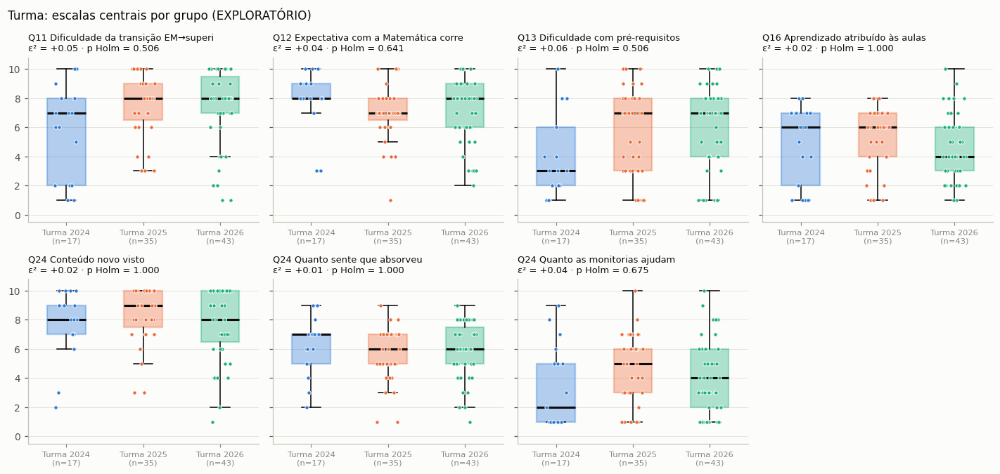

**Idade — família de 7 testes, Holm** — `EXPLORATÓRIO`

,20+ anos: n,20+ anos: Md [IQR],17–19 anos: n,17–19 anos: Md [IQR],teste,estat,p,p_holm,sig,efeito,medida
desfecho,,,,,,,,,,,
Q11 Dificuldade da transição EM→superior,55,8.0 [5.5–9.0],40,8.0 [6.8–9.0],Mann-Whitney U,1006.0,0.4739,1.0,,0.074,r
Q12 Expectativa com a Matemática correspondida,55,7.0 [6.0–8.0],40,8.0 [7.0–9.0],Mann-Whitney U,853.0,0.0591,0.4135,,0.194,r
Q13 Dificuldade com pré-requisitos,55,6.0 [2.5–8.0],40,7.0 [4.0–8.0],Mann-Whitney U,986.0,0.388,1.0,,0.089,r
Q16 Aprendizado atribuído às aulas,55,5.0 [3.5–7.0],40,5.0 [3.0–7.0],Mann-Whitney U,1077.5,0.8671,1.0,,0.018,r
Q24 Conteúdo novo visto,55,8.0 [7.0–10.0],40,9.0 [7.0–10.0],Mann-Whitney U,995.0,0.4185,1.0,,0.083,r
Q24 Quanto sente que absorveu,55,6.0 [5.0–7.0],40,6.0 [5.0–7.0],Mann-Whitney U,1078.0,0.8692,1.0,,0.017,r
Q24 Quanto as monitorias ajudam,55,4.0 [1.0–6.0],40,5.0 [2.8–6.2],Mann-Whitney U,896.0,0.1207,0.724,,0.16,r


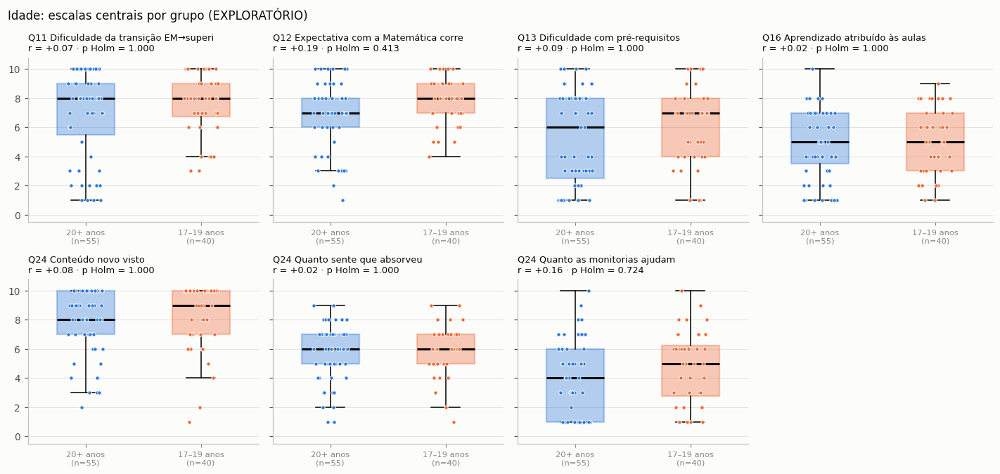

**Tempo entre EM e ImpaTech — família de 7 testes, Holm** — `EXPLORATÓRIO`

,Após ≥ 1 ano: n,Após ≥ 1 ano: Md [IQR],Imediatamente: n,Imediatamente: Md [IQR],teste,estat,p,p_holm,sig,efeito,medida
desfecho,,,,,,,,,,,
Q11 Dificuldade da transição EM→superior,32,8.0 [3.0–8.0],63,8.0 [7.0–9.0],Mann-Whitney U,802.0,0.1002,0.6009,,0.169,r
Q12 Expectativa com a Matemática correspondida,32,7.0 [5.8–8.0],63,8.0 [6.5–9.0],Mann-Whitney U,843.5,0.1895,0.9103,,0.135,r
Q13 Dificuldade com pré-requisitos,32,4.0 [2.8–8.0],63,7.0 [3.5–8.0],Mann-Whitney U,862.5,0.2493,0.9103,,0.119,r
Q16 Aprendizado atribuído às aulas,32,4.0 [2.8–7.0],63,6.0 [4.0–7.0],Mann-Whitney U,840.5,0.1845,0.9103,,0.137,r
Q24 Conteúdo novo visto,32,8.0 [7.0–9.2],63,9.0 [7.0–10.0],Mann-Whitney U,842.5,0.1821,0.9103,,0.137,r
Q24 Quanto sente que absorveu,32,5.5 [4.8–8.0],63,6.0 [5.0–7.0],Mann-Whitney U,982.0,0.8383,0.9103,,0.021,r
Q24 Quanto as monitorias ajudam,32,3.0 [1.0–5.0],63,5.0 [2.5–6.5],Mann-Whitney U,713.0,0.019,0.1328,,0.241,r


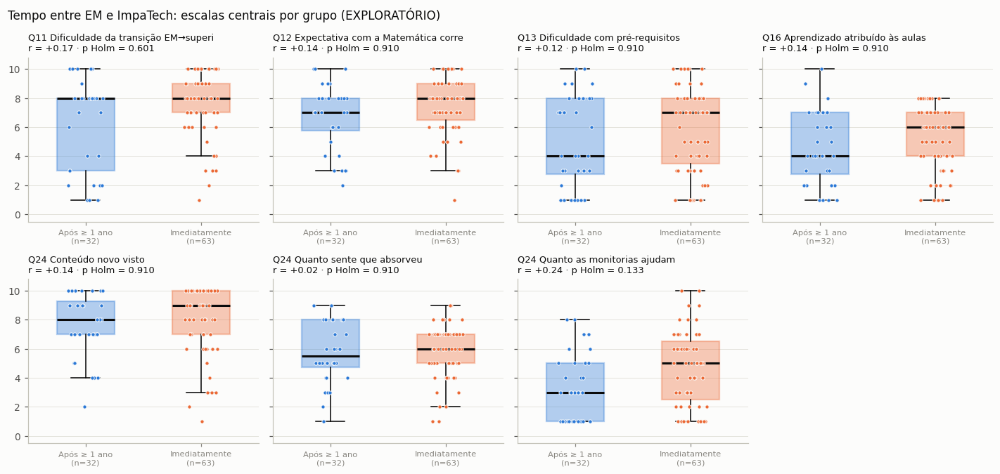

**Outra graduação — família de 7 testes, Holm** — `EXPLORATÓRIO`

,Iniciou outra graduação: n,Iniciou outra graduação: Md [IQR],Não iniciou: n,Não iniciou: Md [IQR],teste,estat,p,p_holm,sig,efeito,medida
desfecho,,,,,,,,,,,
Q11 Dificuldade da transição EM→superior,26,8.0 [3.2–8.0],69,8.0 [6.0–9.0],Mann-Whitney U,737.0,0.1761,1.0,,0.139,r
Q12 Expectativa com a Matemática correspondida,26,7.0 [6.0–8.0],69,8.0 [6.0–9.0],Mann-Whitney U,799.5,0.4108,1.0,,0.085,r
Q13 Dificuldade com pré-requisitos,26,4.0 [2.2–8.0],69,7.0 [3.0–8.0],Mann-Whitney U,769.5,0.2848,1.0,,0.11,r
Q16 Aprendizado atribuído às aulas,26,5.0 [3.2–7.0],69,5.0 [3.0–7.0],Mann-Whitney U,897.5,1.0,1.0,,0.0,r
Q24 Conteúdo novo visto,26,7.5 [7.0–9.8],69,9.0 [7.0–10.0],Mann-Whitney U,750.0,0.2091,1.0,,0.129,r
Q24 Quanto sente que absorveu,26,6.0 [5.0–7.0],69,6.0 [5.0–7.0],Mann-Whitney U,860.0,0.7569,1.0,,0.032,r
Q24 Quanto as monitorias ajudam,26,3.0 [1.0–5.0],69,5.0 [2.0–6.0],Mann-Whitney U,752.5,0.2239,1.0,,0.125,r


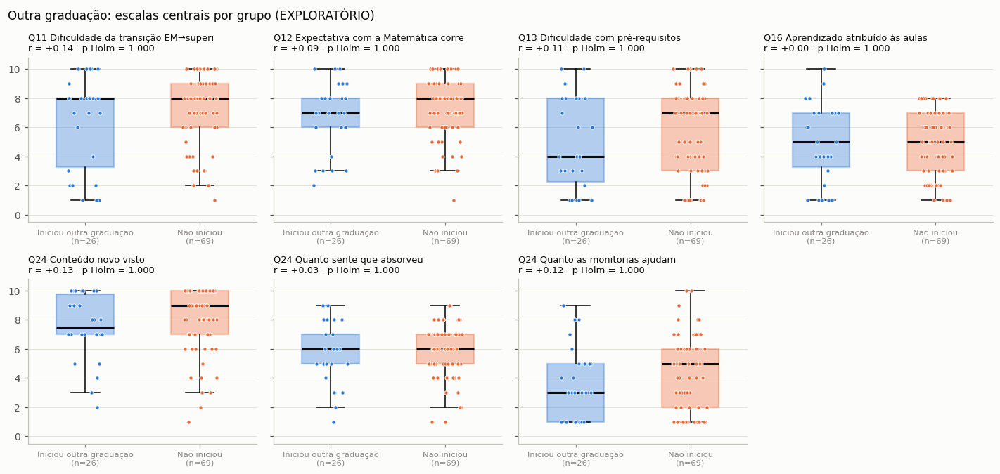

**Escola no EM — família de 7 testes, Holm** — `EXPLORATÓRIO`

,Só escola pública: n,Só escola pública: Md [IQR],Alguma escola privada: n,Alguma escola privada: Md [IQR],teste,estat,p,p_holm,sig,efeito,medida
desfecho,,,,,,,,,,,
Q11 Dificuldade da transição EM→superior,82,8.0 [7.0–9.0],13,6.0 [3.0–9.0],Mann-Whitney U,650.0,0.1999,1.0,,0.132,r
Q12 Expectativa com a Matemática correspondida,82,8.0 [6.0–8.8],13,7.0 [4.0–8.0],Mann-Whitney U,592.0,0.5199,1.0,,0.067,r
Q13 Dificuldade com pré-requisitos,82,7.0 [3.0–8.0],13,4.0 [2.0–9.0],Mann-Whitney U,557.0,0.7974,1.0,,0.027,r
Q16 Aprendizado atribuído às aulas,82,5.0 [3.2–7.0],13,5.0 [3.0–7.0],Mann-Whitney U,543.0,0.9173,1.0,,0.011,r
Q24 Conteúdo novo visto,82,9.0 [7.0–10.0],13,7.0 [6.0–10.0],Mann-Whitney U,616.5,0.3559,1.0,,0.095,r
Q24 Quanto sente que absorveu,82,6.0 [5.0–7.0],13,6.0 [5.0–7.0],Mann-Whitney U,565.0,0.7289,1.0,,0.036,r
Q24 Quanto as monitorias ajudam,82,4.0 [2.0–6.0],13,5.0 [1.0–6.0],Mann-Whitney U,518.5,0.8781,1.0,,0.016,r


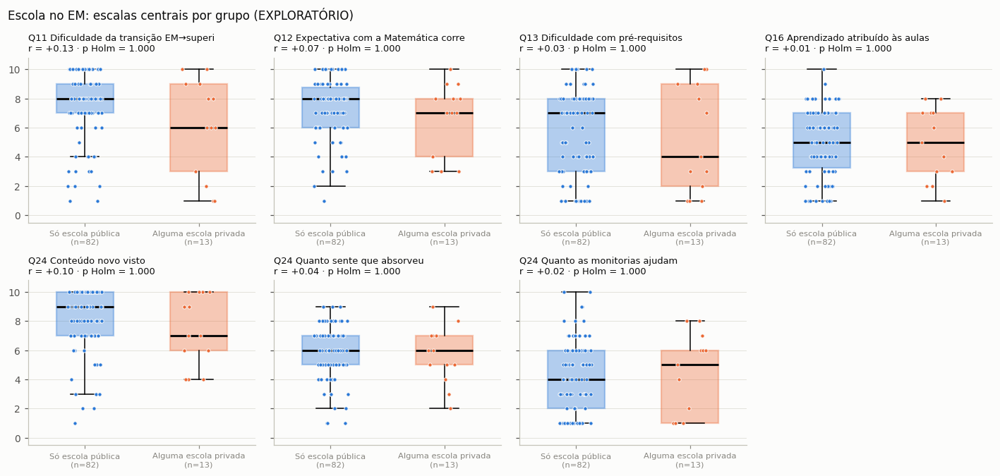

**Uso de IA (Q17) — família de 7 testes, Holm** — `EXPLORATÓRIO`

,Sempre usa IA: n,Sempre usa IA: Md [IQR],Às vezes / não usa: n,Às vezes / não usa: Md [IQR],teste,estat,p,p_holm,sig,efeito,medida
desfecho,,,,,,,,,,,
Q11 Dificuldade da transição EM→superior,59,8.0 [7.0–10.0],36,7.0 [5.5–8.0],Mann-Whitney U,1457.5,0.0021,0.0145,*,0.316,r
Q12 Expectativa com a Matemática correspondida,59,7.0 [6.0–8.0],36,8.0 [6.0–9.0],Mann-Whitney U,968.0,0.4662,1.0,,0.075,r
Q13 Dificuldade com pré-requisitos,59,7.0 [3.0–8.0],36,4.0 [1.0–7.2],Mann-Whitney U,1384.5,0.0127,0.0635,,0.256,r
Q16 Aprendizado atribuído às aulas,59,5.0 [3.0–7.0],36,5.0 [2.8–7.0],Mann-Whitney U,1099.5,0.7745,1.0,,0.03,r
Q24 Conteúdo novo visto,59,9.0 [7.0–10.0],36,8.0 [6.0–9.2],Mann-Whitney U,1321.5,0.0413,0.1651,,0.21,r
Q24 Quanto sente que absorveu,59,6.0 [5.0–7.0],36,7.0 [5.0–8.0],Mann-Whitney U,710.0,0.0061,0.0368,*,0.282,r
Q24 Quanto as monitorias ajudam,59,5.0 [2.5–6.0],36,4.0 [1.0–6.0],Mann-Whitney U,1098.0,0.7829,1.0,,0.029,r


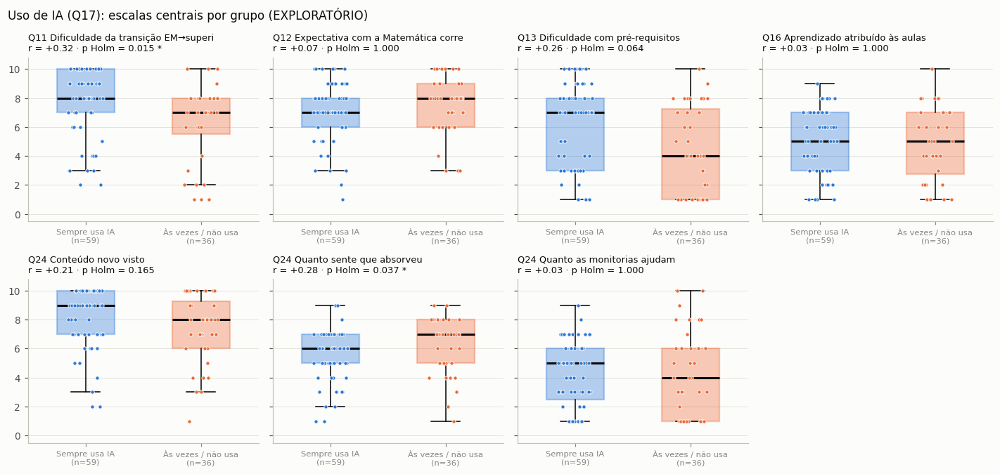

**Pretende terminar (Q20) — família de 7 testes, Holm** — `EXPLORATÓRIO`

,Pretende terminar: n,Pretende terminar: Md [IQR],Não / não tem certeza: n,Não / não tem certeza: Md [IQR],teste,estat,p,p_holm,sig,efeito,medida
desfecho,,,,,,,,,,,
Q11 Dificuldade da transição EM→superior,81,8.0 [6.0–9.0],14,8.0 [6.2–8.8],Mann-Whitney U,574.5,0.9405,1.0,,0.008,r
Q12 Expectativa com a Matemática correspondida,81,8.0 [7.0–9.0],14,6.5 [3.2–7.8],Mann-Whitney U,772.0,0.0292,0.2042,,0.224,r
Q13 Dificuldade com pré-requisitos,81,5.0 [3.0–8.0],14,7.5 [5.5–8.0],Mann-Whitney U,409.0,0.0952,0.4762,,0.172,r
Q16 Aprendizado atribuído às aulas,81,5.0 [3.0–7.0],14,5.5 [4.2–6.0],Mann-Whitney U,538.5,0.7667,1.0,,0.031,r
Q24 Conteúdo novo visto,81,8.0 [7.0–10.0],14,9.0 [6.0–10.0],Mann-Whitney U,583.5,0.863,1.0,,0.018,r
Q24 Quanto sente que absorveu,81,6.0 [5.0–7.0],14,5.0 [4.0–6.8],Mann-Whitney U,736.5,0.0714,0.4282,,0.186,r
Q24 Quanto as monitorias ajudam,81,4.0 [2.0–6.0],14,5.0 [2.2–6.8],Mann-Whitney U,517.5,0.6027,1.0,,0.054,r


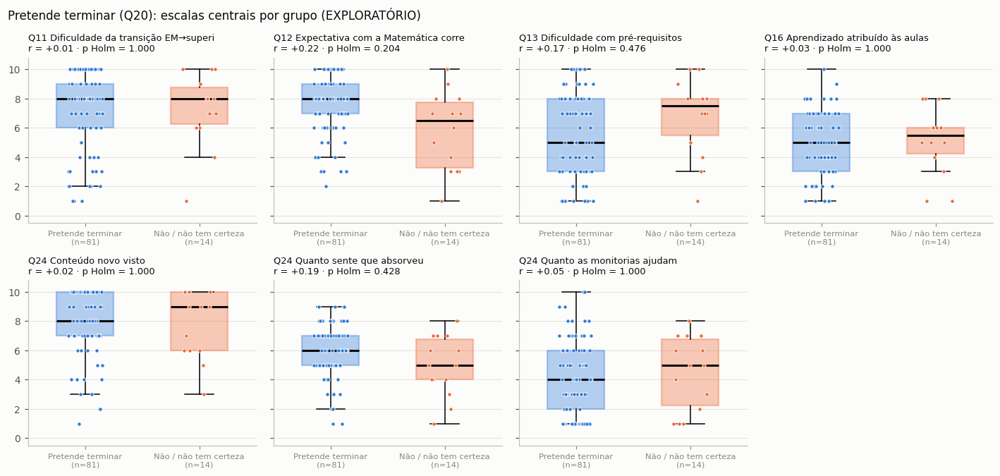

**Trancou/reprovou (Q25) — família de 7 testes, Holm** — `EXPLORATÓRIO`

,Não trancou/reprovou: n,Não trancou/reprovou: Md [IQR],Trancou/reprovou: n,Trancou/reprovou: Md [IQR],teste,estat,p,p_holm,sig,efeito,medida
desfecho,,,,,,,,,,,
Q11 Dificuldade da transição EM→superior,84,8.0 [6.0–9.0],11,8.0 [7.0–10.0],Mann-Whitney U,387.5,0.3819,1.0,,0.09,r
Q12 Expectativa com a Matemática correspondida,84,8.0 [7.0–9.0],11,6.0 [3.5–7.0],Mann-Whitney U,655.0,0.0229,0.1605,,0.234,r
Q13 Dificuldade com pré-requisitos,84,7.0 [3.0–8.0],11,5.0 [2.5–7.5],Mann-Whitney U,511.0,0.5693,1.0,,0.059,r
Q16 Aprendizado atribuído às aulas,84,5.5 [3.8–7.0],11,4.0 [2.5–5.5],Mann-Whitney U,569.0,0.2113,1.0,,0.129,r
Q24 Conteúdo novo visto,84,8.5 [7.0–10.0],11,9.0 [5.5–9.5],Mann-Whitney U,508.0,0.5868,1.0,,0.056,r
Q24 Quanto sente que absorveu,84,6.0 [5.0–7.0],11,5.0 [3.0–6.0],Mann-Whitney U,645.0,0.031,0.186,,0.222,r
Q24 Quanto as monitorias ajudam,84,4.0 [2.0–6.0],11,3.0 [1.0–5.5],Mann-Whitney U,507.0,0.6005,1.0,,0.054,r


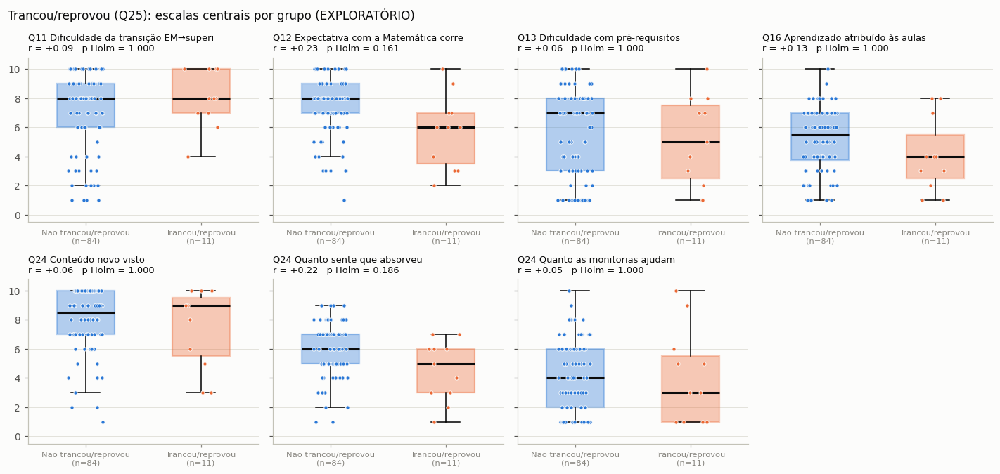

In [16]:
resultados_comp, dunn_todos = {}, {}
for nome, g in AGRUPAMENTOS.items():
    t, dunn = utils.comparar_grupos(df, g, utils.ESCALAS_CENTRAIS, N_MIN_GRUPO, ALPHA)
    resultados_comp[nome] = t
    t = utils.suprimir(t, N_MIN_CELULA, [c for c in t.columns if c.endswith(": n")])
    mostrar_teste(t, f"{nome} — família de {len(utils.ESCALAS_CENTRAIS)} testes, Holm")
    if t["teste"].str.startswith("não testado").all():
        print(f"  → Nota: algum grupo de '{nome}' tem n < N_MIN_GRUPO = {N_MIN_GRUPO}; só descritiva.")
    if df[g].value_counts().min() >= N_MIN_CELULA:
        utils.grafico_grupos(df, g, utils.ESCALAS_CENTRAIS, tabela=resultados_comp[nome],
                             arquivo=f"figuras/exploratorio/05_grupos_{g}.png",
                             titulo=f"{nome}: escalas centrais por grupo ({ROTULO})")
        plt.show()
    else:
        print(f"  → Gráfico omitido: algum grupo tem n < N_MIN_CELULA = {N_MIN_CELULA} (privacidade).")
    for desf, m in dunn.items():
        dunn_todos[(nome, desf)] = m
        display(Markdown(f"Post-hoc de Dunn (p ajustado por Holm) — *{desf}*")); display(m)
    t.to_csv(f"tabelas/exploratorio/05b_comparacao_{g}.csv")

### 05c · Associações entre variáveis categóricas

Qui-quadrado; com frequência esperada < 5: Fisher exato (2×2) ou qui-quadrado por Monte Carlo (tabelas maiores). Holm sobre a família de pares. As tabelas cruzadas mostram contagens suprimidas abaixo de `N_MIN_CELULA`.

**Associações categóricas — família de 8 testes, Holm** — `EXPLORATÓRIO`

,dimensão,N,teste,chi2,p,V de Cramér,p_holm,sig
par,,,,,,,,
g_ingresso × g_ia,2×2,95,Qui-quadrado,2.27,0.1320,0.155,0.9240,
g_ingresso × g_apoio,2×2,95,Qui-quadrado,2.63,0.1051,0.166,0.8404,
g_ingresso × g_terminar,2×2,95,Fisher exato,0.10,0.7464,0.032,1.0000,
g_turma × g_ia,3×2,95,Qui-quadrado,2.09,0.3510,0.148,1.0000,
g_turma × g_apoio,3×2,95,Qui-quadrado,3.44,0.1788,0.190,1.0000,
g_escola × g_apoio,2×2,95,Qui-quadrado,1.41,0.2357,0.122,1.0000,
g_tempo × g_apoio,2×2,95,Qui-quadrado,0.47,0.4939,0.070,1.0000,
g_outra_grad × g_apoio,2×2,95,Qui-quadrado,0.78,0.3766,0.091,1.0000,


*g_ingresso × g_ia*

g_ia,Sempre usa IA,Às vezes / não usa
g_ingresso,,
ENEM,18,6
Medalhas,41,30


*g_ingresso × g_apoio*

g_apoio,Não precisou de apoio,Precisou de apoio
g_ingresso,,
ENEM,6,18
Medalhas,31,40


... (8 outputs left out)

*g_tempo × g_apoio*

g_apoio,Não precisou de apoio,Precisou de apoio
g_tempo,,
Após ≥ 1 ano,14,18
Imediatamente,23,40


*g_outra_grad × g_apoio*

g_apoio,Não precisou de apoio,Precisou de apoio
g_outra_grad,,
Iniciou outra graduação,12,14
Não iniciou,25,44


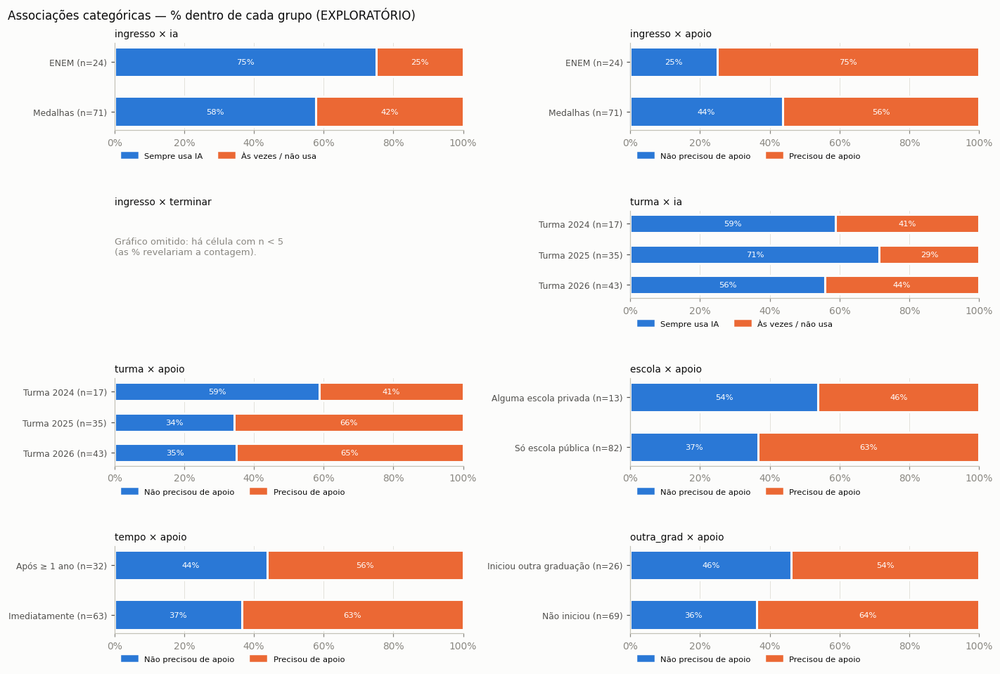

In [17]:
PARES = [("g_ingresso", "g_ia"), ("g_ingresso", "g_apoio"), ("g_ingresso", "g_terminar"),
         ("g_turma", "g_ia"), ("g_turma", "g_apoio"), ("g_escola", "g_apoio"),
         ("g_tempo", "g_apoio"), ("g_outra_grad", "g_apoio")]
tab_cat, cruzadas = utils.associar_categoricas(df, PARES, N_MIN_GRUPO, ALPHA)
mostrar_teste(tab_cat, f"Associações categóricas — família de {len(PARES)} testes, Holm")
tab_cat.to_csv("tabelas/exploratorio/05c_associacoes_categoricas.csv")
for nome, ct in cruzadas.items():
    display(Markdown(f"*{nome}*"))
    if utils.tem_celula_pequena(ct, N_MIN_CELULA):
        # Com os totais de linha e coluna conhecidos, suprimir só a célula não basta.
        print(f"  Tabela omitida: há célula com n < N_MIN_CELULA = {N_MIN_CELULA} (o teste acima continua válido).")
    else:
        display(ct)
utils.grafico_cruzadas(cruzadas, N_MIN_CELULA, arquivo="figuras/exploratorio/05_associacoes.png",
                       titulo=f"Associações categóricas — % dentro de cada grupo ({ROTULO})")
plt.show()

### 05d · Mapa exploratório de associações (todos × todos)

**O que é uma correlação (associação):** duas variáveis estão correlacionadas quando *variam juntas* — quando um valor maior em uma tende a vir acompanhado de um valor maior (correlação **positiva**) ou menor (correlação **negativa**) na outra. Aqui todas as medidas vão de −1 a +1. As duas primeiras são **correlações de postos**, que só usam a *ordem* dos valores (adequado para escalas ordinais); a terceira (φ) é a correlação entre duas variáveis 0/1, calculada a partir da tabela 2×2:

- **grupo × escala → r_rb (rank-biserial).** `+0,40` em "Ingresso: ENEM" × Q13 significa que, comparando um aluno ENEM com um medalhista ao acaso, o do ENEM tem Q13 maior com mais frequência (r_rb = P(maior) − P(menor)). Positivo = o grupo da linha tem valores **maiores**.
- **ordinal × escala → ρ de Spearman** (turma, de 2024 a 2026).
- **grupo × grupo → φ** (2×2, com sinal), com teste exato de Fisher.

**Como ler:** o *sinal* dá o sentido; o *tamanho* dá a força (convenção de Cohen para correlações: abaixo de 0,1 desprezível, a partir de 0,1 pequena, de 0,3 média, de 0,5 grande; para r_rb e φ esses cortes são só aproximados, e o φ fica naturalmente menor quando um dos grupos é bem menor que o outro); o `*` diz que a associação sobrevive à correção de Holm. Um p pequeno com efeito pequeno é pouco relevante; um efeito grande com p alto pode ser só falta de n.

⚠️ **Isto é mineração de dados**: são dezenas de testes de uma vez. O mapa serve para **gerar** hipóteses, não para confirmá-las. Correlação também não indica causa nem direção.

169 associações testadas (uma família, Holm); 9 não testadas por n < N_MIN_GRUPO; 2 significativas após Holm.


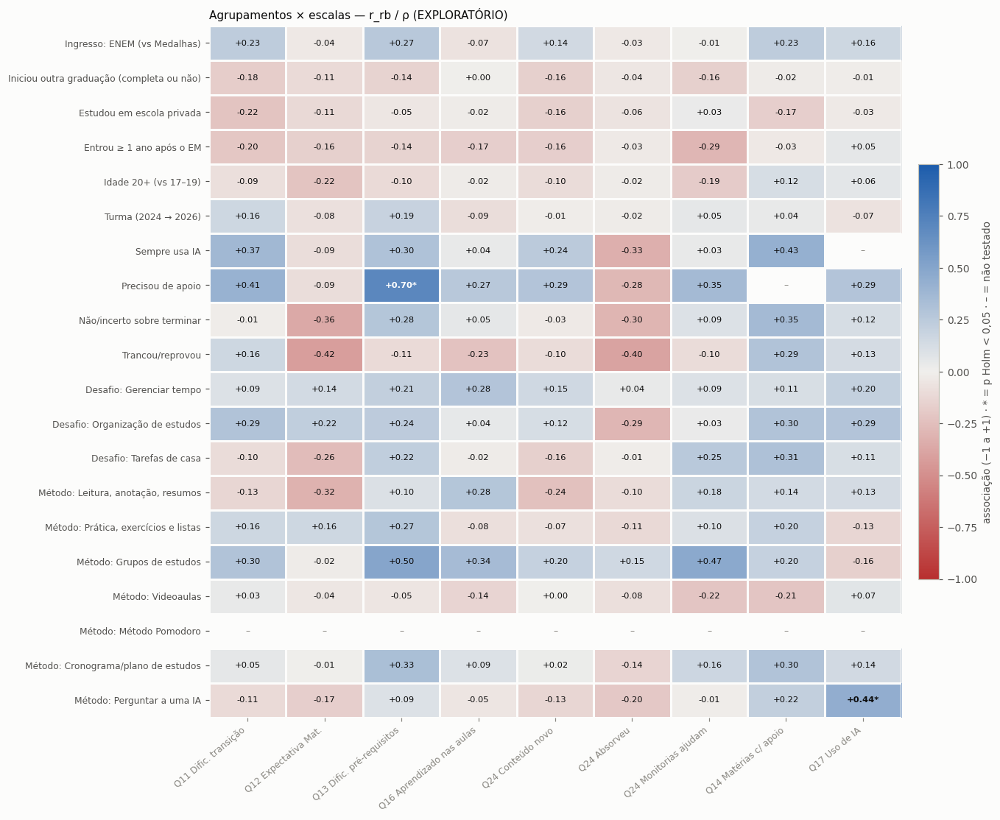

In [18]:
mapa = utils.mapa_associacoes(df, LINHAS_MAPA, DESFECHOS_MAPA, N_MIN_GRUPO, EXCLUIR_MAPA)
mapa["sig"] = np.where(mapa["p_holm"] < ALPHA, "*", "")
mapa["magnitude"] = mapa["efeito"].map(utils.magnitude)
testadas = mapa[mapa["status"] == "testado"]
print(f"{len(testadas)} associações testadas (uma família, Holm); "
      f"{(mapa['status'] == 'n < N_MIN_GRUPO').sum()} não testadas por n < N_MIN_GRUPO; "
      f"{(testadas['p_holm'] < ALPHA).sum()} significativas após Holm.")
utils.grafico_mapa(mapa, list(LINHAS_MAPA), DESFECHOS_MAPA, "efeito",
                   arquivo="figuras/exploratorio/05d_mapa_associacoes.png",
                   titulo=f"Agrupamentos × escalas — r_rb / ρ ({ROTULO})")
plt.show()
mapa.to_csv("tabelas/exploratorio/05d_mapa_associacoes.csv", index=False)

In [19]:
# Ranking: as associações mais fortes (independentemente do p), para orientar hipóteses
TOP_MAPA = 15
rank = testadas.assign(abs_ef=testadas["efeito"].abs()).sort_values("abs_ef", ascending=False)
rank = rank.assign(desfecho=rank["desfecho"].map(lambda c: utils.CURTOS.get(c, c)))
mostrar_teste(rank[["variável", "desfecho", "n_pos", "n_neg", "medida", "efeito", "magnitude", "p", "p_holm", "sig"]]
              .head(TOP_MAPA).round(4).reset_index(drop=True),
              f"As {TOP_MAPA} associações mais fortes (|efeito|)")
print("n_pos = n do grupo da linha (ou n total, para ρ); n_neg = n do grupo de comparação.")

**As 15 associações mais fortes (|efeito|)** — `EXPLORATÓRIO`

,variável,desfecho,n_pos,n_neg,medida,efeito,magnitude,p,p_holm,sig
0,Precisou de apoio,Q13 Dific. pré-requisitos,58.0,37.0,r_rb,0.7027,grande,0.0000,0.0000,*
1,Método: Grupos de estudos,Q13 Dific. pré-requisitos,17.0,78.0,r_rb,0.4985,média,0.0012,0.2023,
2,Método: Grupos de estudos,Q24 Monitorias ajudam,17.0,78.0,r_rb,0.4698,média,0.0023,0.3668,
3,Método: Perguntar a uma IA,Q17 Uso de IA,68.0,27.0,r_rb,0.4423,média,0.0001,0.0133,*
4,Sempre usa IA,Q14 Matérias c/ apoio,59.0,36.0,r_rb,0.4251,média,0.0003,0.0530,
5,Trancou/reprovou,Q12 Expectativa Mat.,11.0,84.0,r_rb,-0.4177,média,0.0229,1.0000,
6,Precisou de apoio,Q11 Dific. transição,58.0,37.0,r_rb,0.4101,média,0.0007,0.1086,
7,Trancou/reprovou,Q24 Absorveu,11.0,84.0,r_rb,-0.3961,média,0.0310,1.0000,
8,Sempre usa IA,Q11 Dific. transição,59.0,36.0,r_rb,0.3724,média,0.0021,0.3409,
9,Não/incerto sobre terminar,Q12 Expectativa Mat.,14.0,81.0,r_rb,-0.3616,média,0.0292,1.0000,


n_pos = n do grupo da linha (ou n total, para ρ); n_neg = n do grupo de comparação.


72 pares testados (Fisher, Holm); 63 mascarados por privacidade; 1 significativos após Holm.


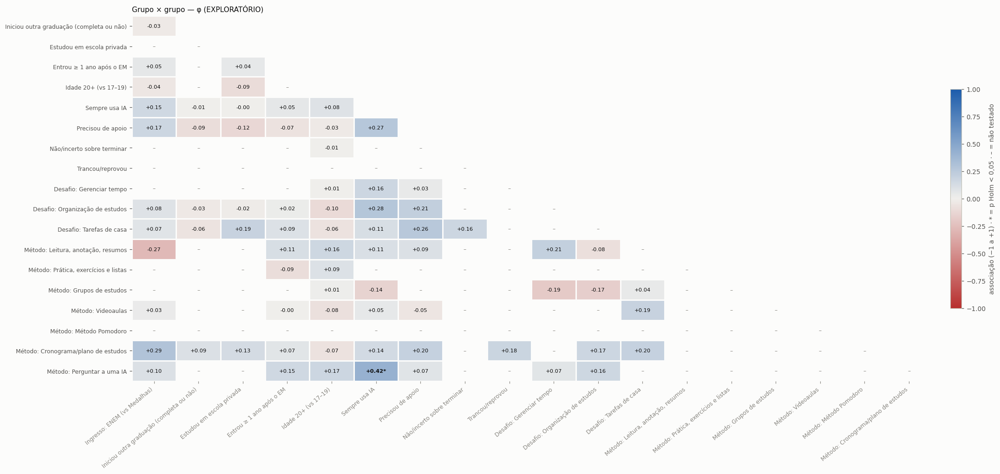

**Os 15 pares de grupos mais associados (|φ|)** — `EXPLORATÓRIO`

,x,y,phi,p,p_holm,sig
0,Sempre usa IA,Método: Perguntar a uma IA,0.4218,0.0001,0.0044,*
1,Ingresso: ENEM (vs Medalhas),Método: Cronograma/plano de estudos,0.2935,0.0111,0.7799,
2,Sempre usa IA,Desafio: Organização de estudos,0.2768,0.0087,0.6197,
3,Ingresso: ENEM (vs Medalhas),"Método: Leitura, anotação, resumos",-0.2741,0.0114,0.7849,
4,Sempre usa IA,Precisou de apoio,0.2660,0.0164,1.0000,
5,Precisou de apoio,Desafio: Tarefas de casa,0.2640,0.0127,0.8626,
6,Precisou de apoio,Desafio: Organização de estudos,0.2142,0.0487,1.0000,
7,Desafio: Gerenciar tempo,"Método: Leitura, anotação, resumos",0.2079,0.0747,1.0000,
8,Precisou de apoio,Método: Cronograma/plano de estudos,0.1995,0.0841,1.0000,
9,Desafio: Tarefas de casa,Método: Cronograma/plano de estudos,0.1976,0.0720,1.0000,


In [20]:
# Grupo × grupo (φ). Pares com célula < N_MIN_CELULA são mascarados: com as margens conhecidas,
# o φ permitiria reconstruir a contagem.
FONTES = {r: s[1][:3] for r, s in LINHAS_MAPA.items() if s[1].startswith(("q19", "q24"))}
bin_tab = utils.associacoes_binarias(df, LINHAS_MAPA, N_MIN_CELULA, N_MIN_GRUPO, FONTES)
bin_tab["sig"] = np.where(bin_tab["p_holm"] < ALPHA, "*", "")
ordem_bin = [r for r, s in LINHAS_MAPA.items() if s[0] == "binario"]
print(f"{(bin_tab['status'] == 'testado').sum()} pares testados (Fisher, Holm); "
      f"{bin_tab['status'].str.startswith('mascarado').sum()} mascarados por privacidade; "
      f"{(bin_tab['p_holm'] < ALPHA).sum()} significativos após Holm.")
utils.grafico_mapa(bin_tab, ordem_bin[1:], ordem_bin[:-1], "phi", rot_cols=ordem_bin[:-1],
                   arquivo="figuras/exploratorio/05d_mapa_grupos.png", triangular=True,
                   titulo=f"Grupo × grupo — φ ({ROTULO})")
plt.show()
bt = bin_tab[bin_tab["status"] == "testado"].assign(abs_phi=lambda d: d["phi"].abs()) \
    .sort_values("abs_phi", ascending=False)
mostrar_teste(bt[["x", "y", "phi", "p", "p_holm", "sig"]].head(TOP_MAPA).round(4).reset_index(drop=True),
              f"Os {TOP_MAPA} pares de grupos mais associados (|φ|)")
bin_tab.to_csv("tabelas/exploratorio/05d_grupo_x_grupo.csv", index=False)

### 05e · Perfis: cada linha do mapa × todas as escalas do mapa (com desvio padrão)

Um painel de boxplots por linha do mapa 05d: o grupo da linha contra o seu **complementar** ("Marcou" × "Não marcou" nas opções de Q18/Q23), em **todas as colunas do mapa**: as 7 escalas centrais (0/1–10) e as duas ordinais, Q14 (nº de matérias em que precisou de apoio: Não, 1, 2, 3, 4+) e Q17 (uso de IA: Não, nunca usou, algumas vezes, sempre). Nas ordinais, o eixo y mostra as categorias; cada resposta aparece como um ponto, como nas demais escalas. O título de cada painel repete o r_rb/ρ e o p Holm do mapa; os pares redundantes do mapa ("Sempre usa IA" × Q17, "Precisou de apoio" × Q14) ficam de fora. Figuras em `figuras/exploratorio/05e_perfis/` (subpastas 1_perfil, 2_desafios_q19, 3_metodos_q24); tabelas em `tabelas/exploratorio/05e_perfis/`.

**Duas medidas de dispersão** (só nas 7 escalas centrais, que estão na mesma régua; o DP dos códigos de Q14/Q17 não é comparável com o delas):
- **DP do grupo:** o quanto as respostas *dentro* de um grupo variam. DP baixo = grupo homogêneo naquela escala.
- **Razão DP intragrupo / DP total:** o DP combinado dos grupos dividido pelo DP da escala na amostra toda. Abaixo de 1, separar por esse agrupamento deixa as respostas mais homogêneas (é outra face do tamanho de efeito).

⚠️ DP baixo **não** é um achado por si: aparece em grupos pequenos (estimativa instável) e em escalas com efeito teto/chão (todo mundo perto de 10 ou de 0). Também não é critério para escolher hipóteses — escolher o recorte que mais homogeneíza os dados e testá-lo nos mesmos dados é circular. Grupos com n < `N_MIN_GRUPO` ficam fora dos rankings; com n < `N_MIN_CELULA`, o gráfico é omitido e as estatísticas mascaradas (privacidade).

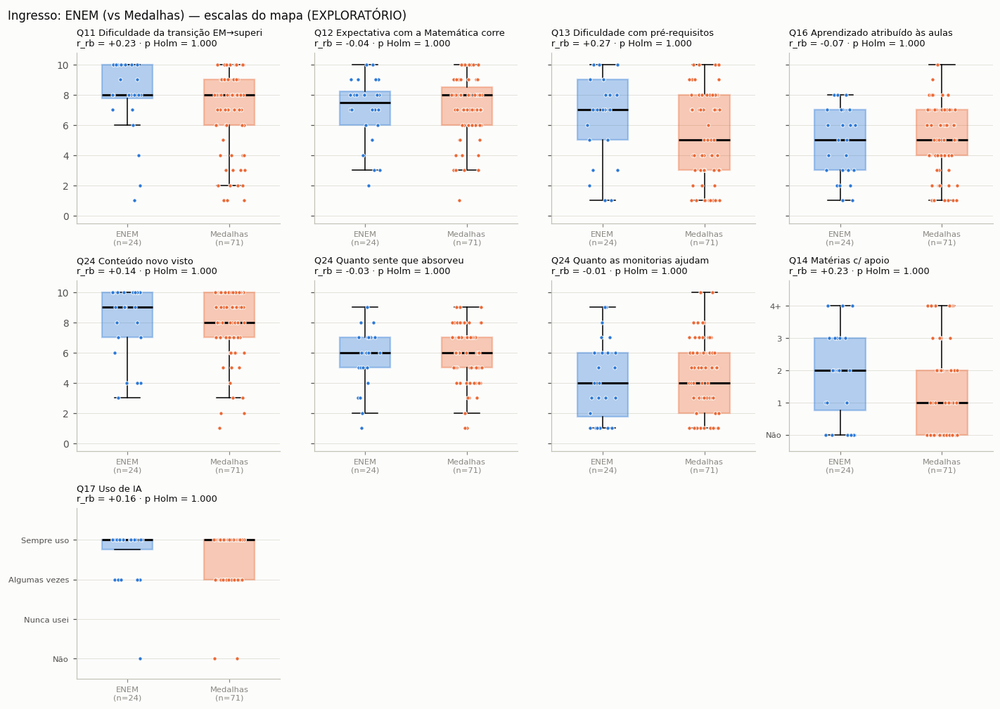

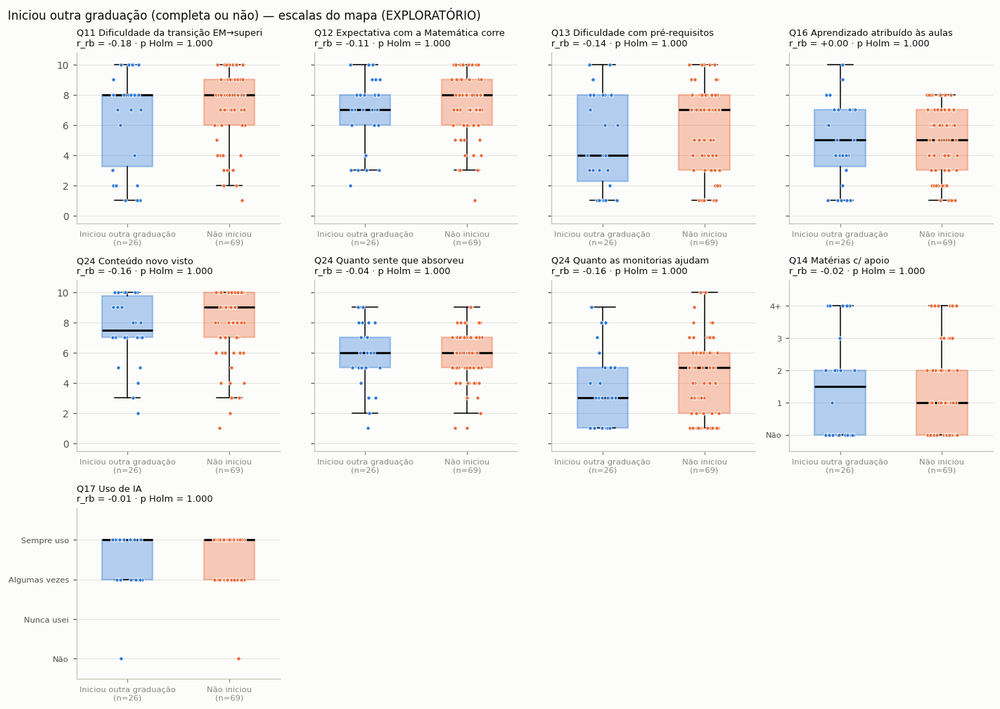

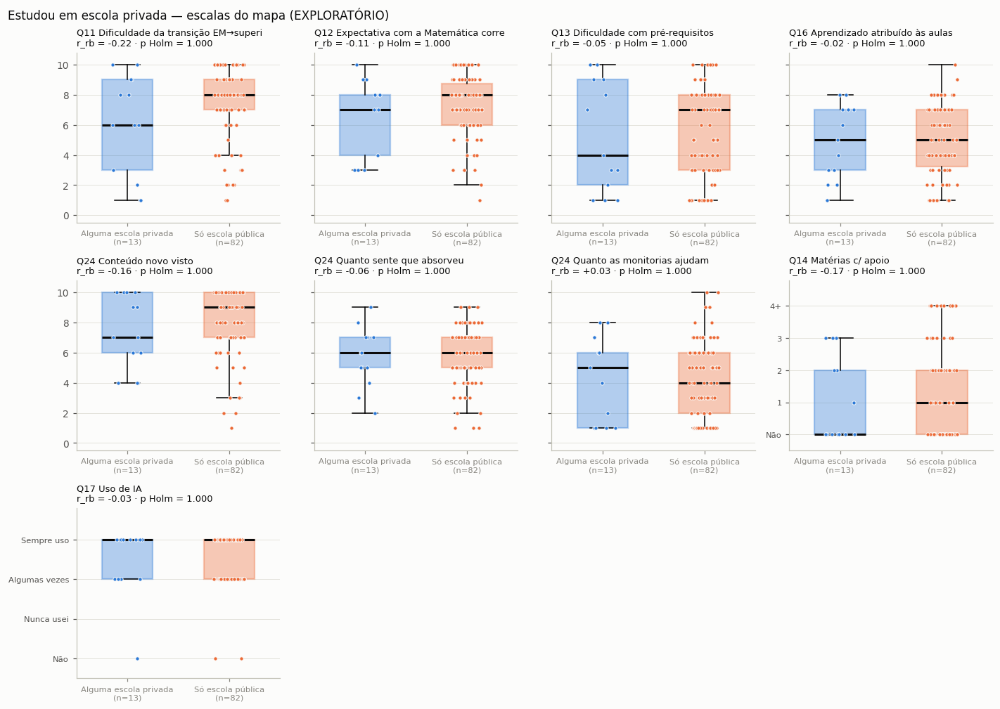

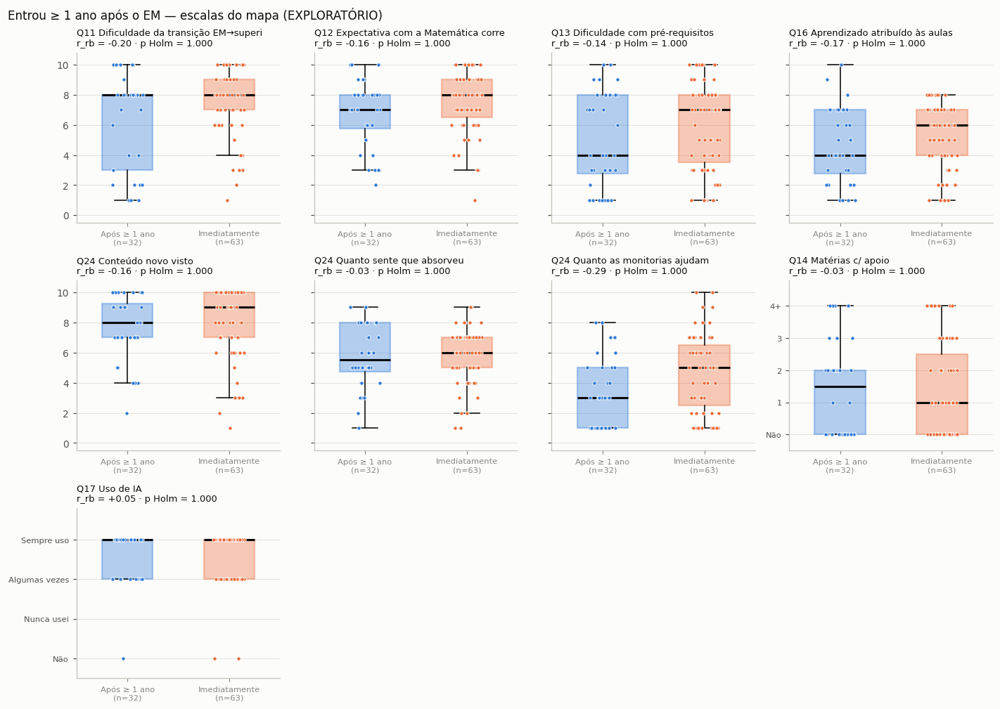

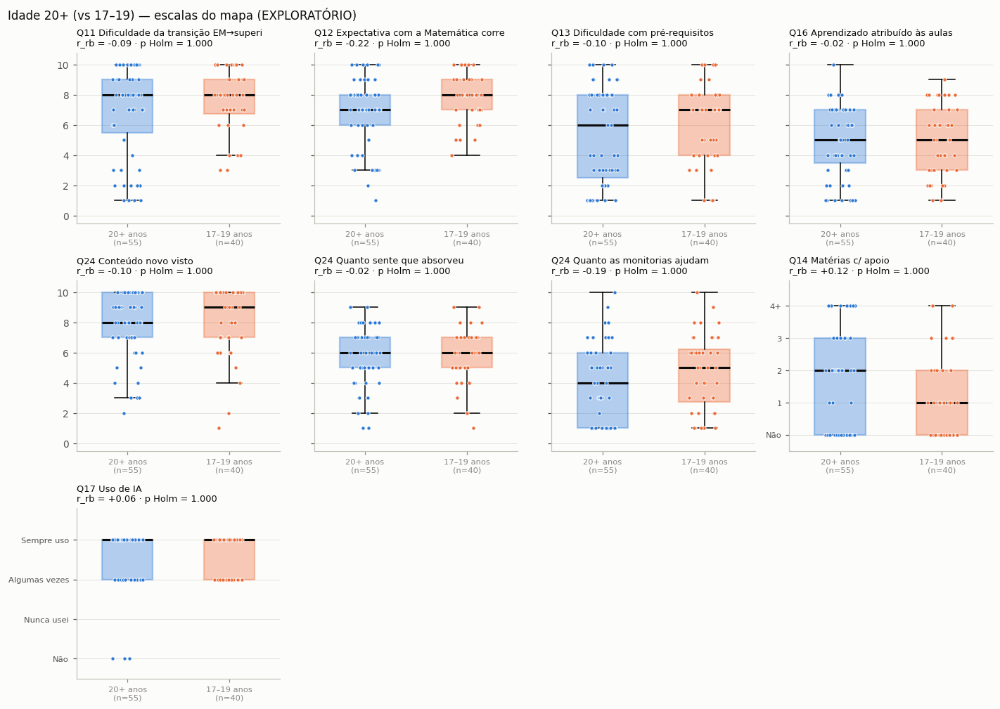

...

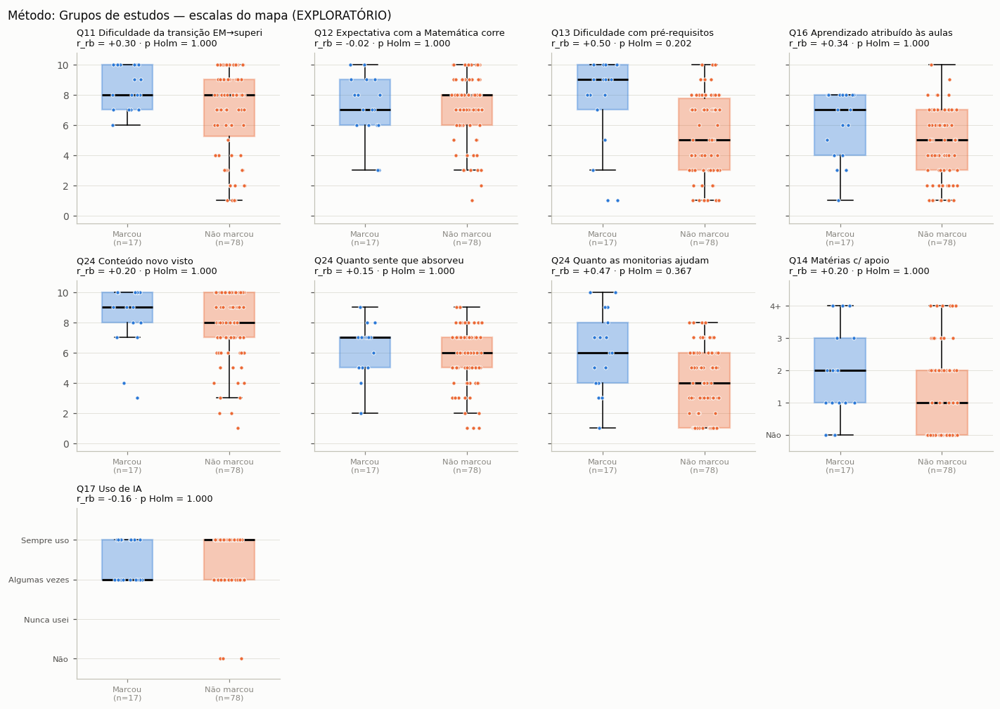

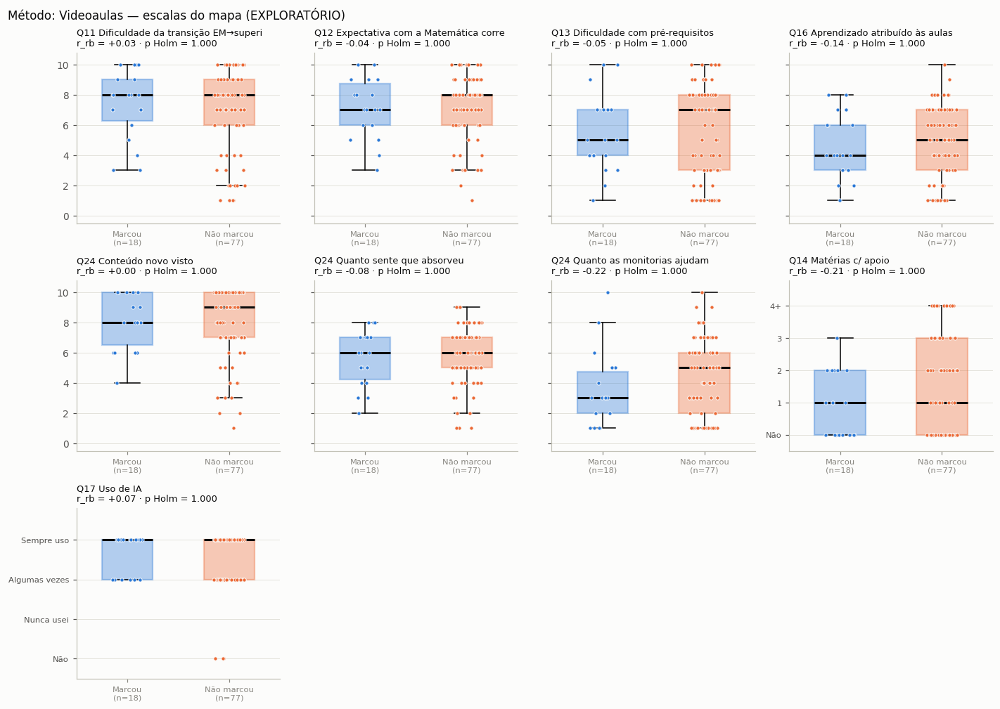

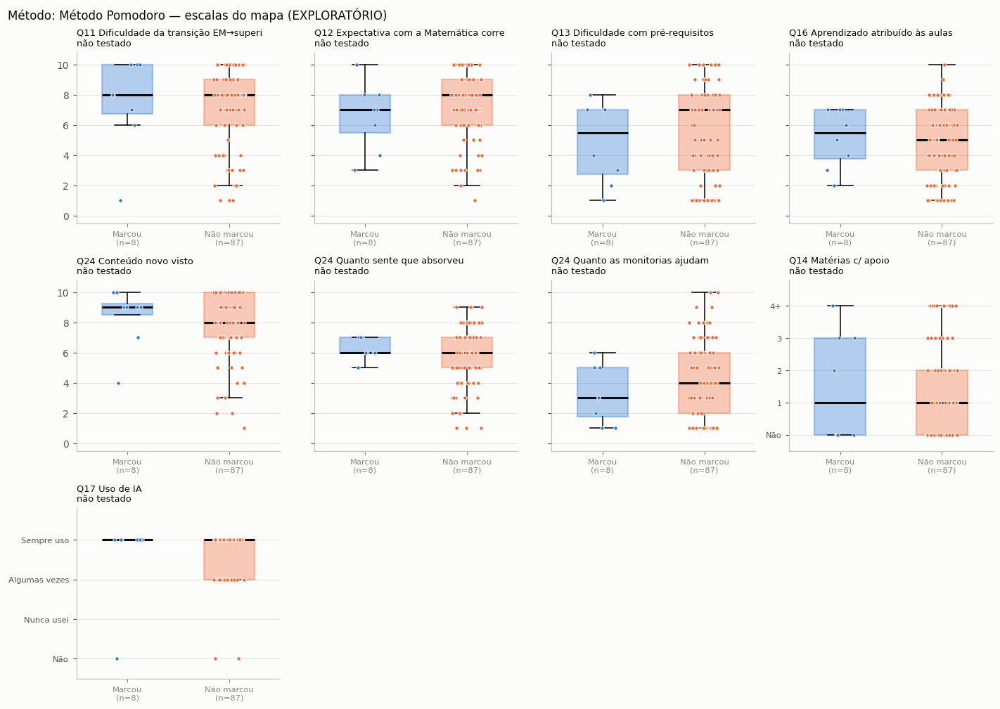

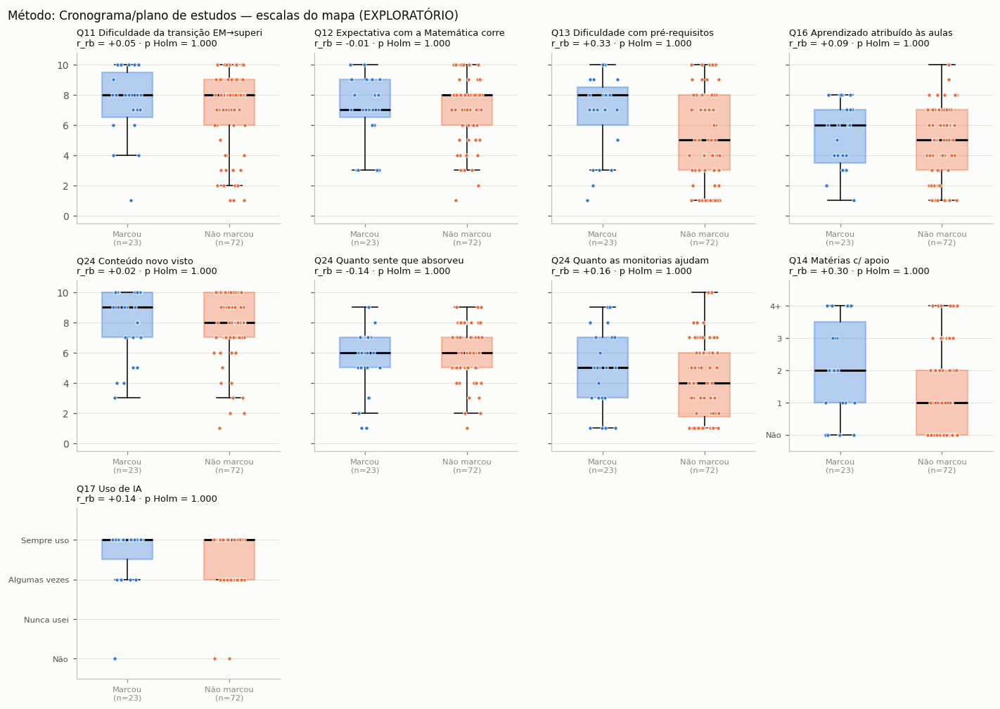

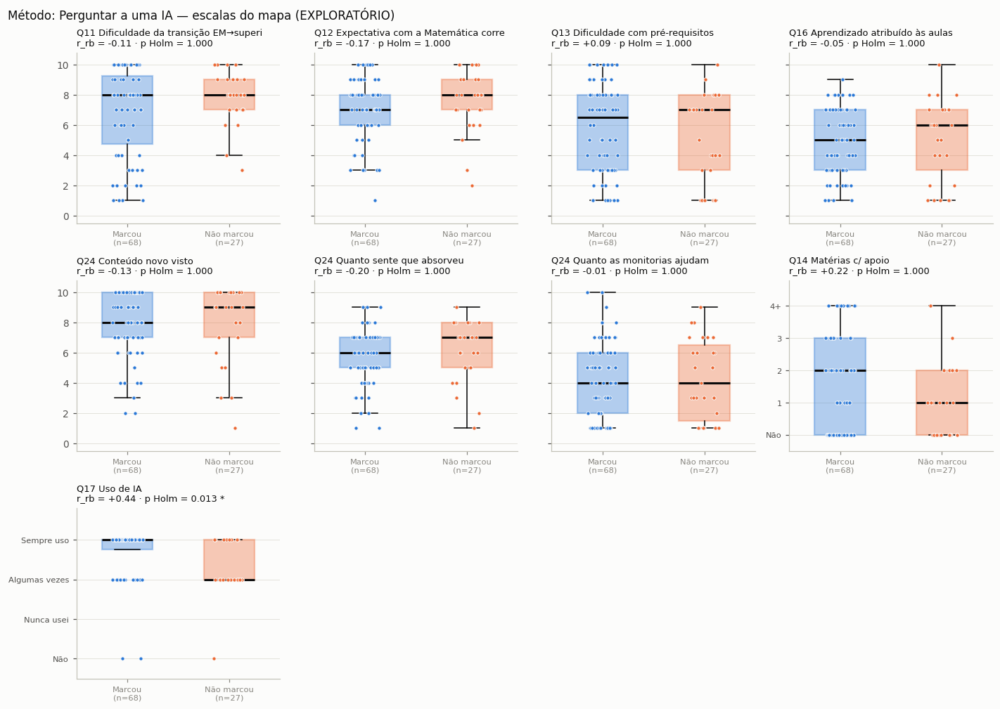

In [21]:
import glob, os, shutil
SUBPASTAS_05E = {"perfil": "1_perfil", "q19": "2_desafios_q18", "q24": "3_metodos_q22"}
for velha in ["boxplot", "histograma", "histograma_largura3", "histograma_largura4"]:
    shutil.rmtree(f"figuras/exploratorio/05e_perfis/{velha}", ignore_errors=True)  # versões anteriores da seção
for p in [f"figuras/exploratorio/05e_perfis/{sp}" for sp in SUBPASTAS_05E.values()] + ["tabelas/exploratorio/05e_perfis"]:
    os.makedirs(p, exist_ok=True)
    for f in glob.glob(f"{p}/*.png") + glob.glob(f"{p}/*.csv"):
        os.remove(f)  # evita figuras velhas de rótulos que mudaram

desc_todos, razao_todos, omitidos = [], [], []
for i, (rot, spec) in enumerate(LINHAS_MAPA.items(), 1):
    g_l = utils.grupo_da_linha(df, spec)
    d_l, r_l = utils.dispersao_por_grupo(df, g_l, utils.ESCALAS_CENTRAIS, N_MIN_CELULA, N_MIN_GRUPO)
    desc_todos.append(d_l.assign(linha=rot)); razao_todos.append(r_l.assign(linha=rot))
    if g_l.value_counts().min() < N_MIN_CELULA:
        omitidos.append(rot); continue
    sp = SUBPASTAS_05E.get(spec[1][:3], SUBPASTAS_05E["perfil"])
    desf = [d for d in DESFECHOS_MAPA if (rot, d) not in EXCLUIR_MAPA]
    tit = mapa[mapa["variável"] == rot].assign(
        rot=lambda d: d["desfecho"].map(utils.rotulo)).set_index("rot")
    tmp = df[desf].assign(_g=g_l)
    utils.grafico_grupos(tmp, "_g", desf, tabela=tit,
                         arquivo=f"figuras/exploratorio/05e_perfis/{sp}/{i:02d}_{utils.slug(rot)}.png",
                         titulo=f"{rot} — escalas do mapa ({ROTULO})")
    plt.show()
if omitidos:
    print(f"Gráficos omitidos (algum grupo com n < N_MIN_CELULA = {N_MIN_CELULA}): " + "; ".join(omitidos))

desc_05e = pd.concat(desc_todos, ignore_index=True)
desc_05e["desfecho"] = desc_05e["desfecho"].map(lambda c: utils.CURTOS.get(c, c))
razao_05e = pd.concat(razao_todos, ignore_index=True)
razao_05e["desfecho"] = razao_05e["desfecho"].map(lambda c: utils.CURTOS.get(c, c))
desc_05e.drop(columns="n ≥ N_MIN_GRUPO").to_csv("tabelas/exploratorio/05e_perfis/descritiva_por_grupo.csv", index=False)
razao_05e.to_csv("tabelas/exploratorio/05e_perfis/razao_dp.csv", index=False)

In [22]:
# DP total de cada escala (referência para os rankings abaixo)
display(utils.descrever_likert(df, utils.ESCALAS_CENTRAIS)[["n", "média", "DP"]])

# Efeito do mapa 05d (r_rb ou ρ, p Holm) para cada par linha × escala
ef_mapa = mapa.assign(desfecho=mapa["desfecho"].map(lambda c: utils.CURTOS.get(c, c)))[
    ["variável", "desfecho", "medida", "efeito", "p_holm", "sig"]].rename(columns={"variável": "linha"})
desc_05e = desc_05e.drop(columns=["medida", "efeito", "p_holm", "sig"], errors="ignore") \
    .merge(ef_mapa, on=["linha", "desfecho"], how="left")
razao_05e = razao_05e.drop(columns=["medida", "efeito", "p_holm", "sig"], errors="ignore") \
    .merge(ef_mapa, on=["linha", "desfecho"], how="left")
# Média de cada grupo da linha, lado a lado (só existe razão quando todos os grupos têm n ≥ N_MIN_GRUPO)
medias = (desc_05e.dropna(subset=["média"]).groupby(["linha", "desfecho"], sort=False)
          .apply(lambda t: " | ".join(f"{g}: {m:.2f}" for g, m in zip(t["grupo"], t["média"])),
                 include_groups=False)
          .rename("médias por grupo").reset_index())
razao_05e = razao_05e.drop(columns="médias por grupo", errors="ignore") \
    .merge(medias, on=["linha", "desfecho"], how="left")
razao_05e["média total"] = razao_05e["desfecho"].map(
    {utils.CURTOS.get(c, c): df[c].mean() for c in utils.ESCALAS_CENTRAIS})

TOP_DP = 15
COLS_DP = ["linha", "grupo", "desfecho", "n", "mediana", "IQR", "média", "DP", "medida", "efeito", "p_holm", "sig"]
rank_dp = desc_05e[desc_05e["n ≥ N_MIN_GRUPO"] & desc_05e["DP"].notna()].sort_values(["DP", "linha", "grupo"], kind="stable")
display(Markdown(f"**Os {TOP_DP} grupos com menor DP** (todos os grupos da linha com n ≥ `N_MIN_GRUPO`) — descritivo"))
display(rank_dp[COLS_DP].head(TOP_DP).round(2).reset_index(drop=True))
rank_dp[COLS_DP].round(3).to_csv("tabelas/exploratorio/05e_perfis/ranking_dp_grupos.csv", index=False)

rank_razao = razao_05e.sort_values(["razão", "linha", "desfecho"], kind="stable")
COLS_RAZAO = ["linha", "desfecho", "médias por grupo", "média total", "DP total", "DP intragrupo", "razão",
              "medida", "efeito", "p_holm", "sig"]
display(Markdown(f"**Todos os {len(rank_razao)} pares linha × escala, do que mais reduz a dispersão ao que menos reduz** "
                 "(razão DP intragrupo / DP total; efeito e p Holm do mapa 05d)"))
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(rank_razao[COLS_RAZAO].round(3).reset_index(drop=True))
rank_razao[COLS_RAZAO].round(4).to_csv("tabelas/exploratorio/05e_perfis/ranking_razao_dp.csv", index=False)

,n,média,DP
variável,,,
Q11 Dificuldade da transição EM→superior,95,7.17,2.65
Q12 Expectativa com a Matemática correspondida,95,7.16,2.10
Q13 Dificuldade com pré-requisitos,95,5.56,2.95
Q16 Aprendizado atribuído às aulas,95,4.97,2.29
Q24 Conteúdo novo visto,95,7.94,2.25
Q24 Quanto sente que absorveu,95,5.82,1.88
Q24 Quanto as monitorias ajudam,95,4.25,2.51


**Os 15 grupos com menor DP** (todos os grupos da linha com n ≥ `N_MIN_GRUPO`) — descritivo

,linha,grupo,desfecho,n,mediana,IQR,média,DP,medida,efeito,p_holm,sig
0,Método: Grupos de estudos,Marcou,Q11 Dific. transição,17,8.0,3.00,8.47,1.37,r_rb,0.30,1.00,
1,Idade 20+ (vs 17–19),17–19 anos,Q12 Expectativa Mat.,40,8.0,2.00,7.72,1.58,r_rb,-0.22,1.00,
2,"Método: Prática, exercícios e listas",Não marcou,Q12 Expectativa Mat.,11,7.0,2.50,6.82,1.60,r_rb,0.16,1.00,
3,"Método: Prática, exercícios e listas",Não marcou,Q24 Absorveu,11,6.0,2.50,6.27,1.62,r_rb,-0.11,1.00,
4,"Método: Leitura, anotação, resumos",Não marcou,Q24 Absorveu,21,6.0,3.00,6.10,1.67,r_rb,-0.10,1.00,
5,Método: Perguntar a uma IA,Não marcou,Q11 Dific. transição,27,8.0,2.00,7.81,1.69,r_rb,-0.11,1.00,
6,Método: Grupos de estudos,Marcou,Q24 Absorveu,17,7.0,2.00,6.24,1.71,r_rb,0.15,1.00,
7,Sempre usa IA,Sempre usa IA,Q24 Absorveu,59,6.0,2.00,5.47,1.74,r_rb,-0.33,0.98,
8,Entrou ≥ 1 ano após o EM,Imediatamente,Q24 Absorveu,63,6.0,2.00,5.86,1.77,r_rb,-0.03,1.00,
9,Precisou de apoio,Precisou de apoio,Q24 Absorveu,58,6.0,2.75,5.48,1.77,r_rb,-0.28,1.00,


**Todos os 133 pares linha × escala, do que mais reduz a dispersão ao que menos reduz** (razão DP intragrupo / DP total; efeito e p Holm do mapa 05d)

,linha,desfecho,médias por grupo,média total,DP total,DP intragrupo,razão,medida,efeito,p_holm,sig
0,Precisou de apoio,Q13 Dific. pré-requisitos,Precisou de apoio: 7.02 | Não precisou de apoio: 3.27,5.558,2.945,2.315,0.786,r_rb,0.703,0.000,*
1,Precisou de apoio,Q11 Dific. transição,Precisou de apoio: 8.00 | Não precisou de apoio: 5.86,7.168,2.648,2.446,0.924,r_rb,0.410,0.109,
2,Método: Grupos de estudos,Q24 Monitorias ajudam,Marcou: 6.12 | Não marcou: 3.85,4.253,2.509,2.364,0.942,r_rb,0.470,0.367,
3,Precisou de apoio,Q24 Monitorias ajudam,Precisou de apoio: 4.86 | Não precisou de apoio: 3.30,4.253,2.509,2.402,0.957,r_rb,0.355,0.542,
4,Método: Grupos de estudos,Q13 Dific. pré-requisitos,Marcou: 7.47 | Não marcou: 5.14,5.558,2.945,2.820,0.958,r_rb,0.498,0.202,
5,Não/incerto sobre terminar,Q12 Expectativa Mat.,Não / não tem certeza: 5.79 | Pretende terminar: 7.40,7.158,2.095,2.026,0.967,r_rb,-0.362,1.000,
6,Sempre usa IA,Q11 Dific. transição,Sempre usa IA: 7.73 | Às vezes / não usa: 6.25,7.168,2.648,2.562,0.967,r_rb,0.372,0.341,
7,Sempre usa IA,Q13 Dific. pré-requisitos,Sempre usa IA: 6.17 | Às vezes / não usa: 4.56,5.558,2.945,2.853,0.969,r_rb,0.304,1.000,
8,Trancou/reprovou,Q12 Expectativa Mat.,Trancou/reprovou: 5.73 | Não trancou/reprovou: 7.35,7.158,2.095,2.040,0.974,r_rb,-0.418,1.000,
9,Trancou/reprovou,Q24 Absorveu,Trancou/reprovou: 4.55 | Não trancou/reprovou: 5.99,5.821,1.879,1.831,0.974,r_rb,-0.396,1.000,


### 05f · Classificação das associações: positiva, negativa, sem associação

Cada célula testável do mapa 05d (grupo × escala) recebe um **intervalo de confiança de 95% por bootstrap** (`B_BOOT` reamostragens; estratificado por grupo) e é classificada:

| Classe | Nível forte ("quase certamente") | Nível indício |
|---|---|---|
| **Positiva** | p Holm < `ALPHA` e efeito > 0 | IC95 inteiro acima de 0, mas não sobrevive a Holm |
| **Negativa** | p Holm < `ALPHA` e efeito < 0 | IC95 inteiro abaixo de 0, mas não sobrevive a Holm |
| **Sem associação** | teste de equivalência (TOST) com margem ±`DELTA_EQUIV`, corrigido por Holm | IC90 inteiro dentro de ±`DELTA_EQUIV` |
| **Inconclusivo** | — | o resto: o IC é largo demais para afirmar qualquer coisa |

**Por que "sem associação" precisa de um teste próprio:** p > 0,05 só diz que *não deu para detectar* uma diferença — não que ela não existe. Para afirmar ausência, o intervalo inteiro precisa caber numa faixa de efeitos que você considera irrelevantes (`DELTA_EQUIV`, na CONFIG). Com o n atual os ICs têm largura perto de ±0,25, então é esperado que essa classe fique vazia ou quase.

**Indício ≠ achado:** sem correção, entre ~150 células, algumas "passam" só por acaso. E associação não é influência: o mapa não diz quem causa o quê.

Gráficos (um boxplot por célula) em `figuras/exploratorio/05f_classificacao/` — subpastas `1_positiva`, `2_negativa`, `3_sem_associacao`, cada uma dividida por nível; o gráfico com todas as células e seus ICs, agrupadas por tema, fica em `figuras/exploratorio/efeitos_ic_faixa/03_mapa_associacoes.png`. As células inconclusivas ficam só na tabela `tabelas/exploratorio/05f_classificacao.csv`.

**169 células classificadas** (B = 5000, margem de equivalência ±0.2) — EXPLORATÓRIO

,classe,nível,células
0,inconclusivo,,132
1,negativa,indicio,9
2,positiva,holm,2
3,positiva,indicio,23
4,sem_associacao,indicio,3


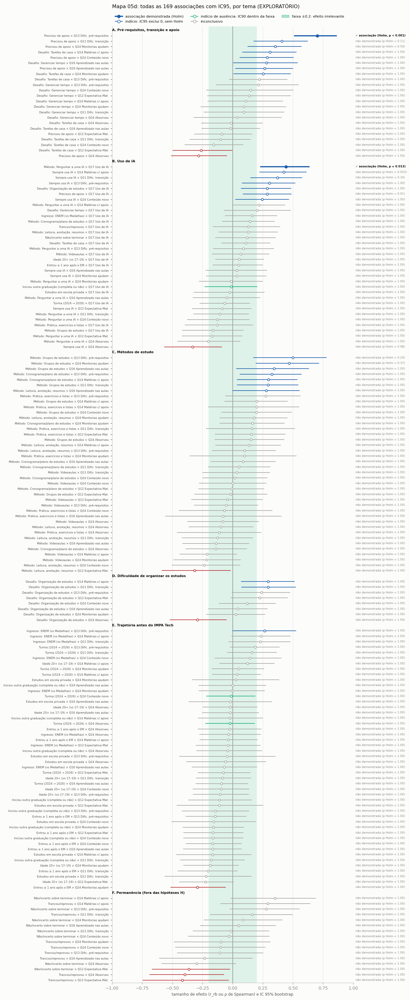

**Positiva** — 25 célula(s)

,nível,variável,desfecho_rot,medida,efeito,ic95_inf,ic95_sup,p,p_holm,p_equiv_holm
0,holm,Precisou de apoio,Q13 Dificuldade com pré-requisitos,r_rb,0.703,0.514,0.862,0.000,0.000,1.0
1,indicio,Método: Grupos de estudos,Q13 Dificuldade com pré-requisitos,r_rb,0.498,0.173,0.777,0.001,0.202,1.0
2,indicio,Método: Grupos de estudos,Q24 Quanto as monitorias ajudam,r_rb,0.470,0.192,0.716,0.002,0.367,1.0
3,holm,Método: Perguntar a uma IA,Q17 Uso de IA,r_rb,0.442,0.231,0.635,0.000,0.013,1.0
4,indicio,Sempre usa IA,Q14 Matérias c/ apoio,r_rb,0.425,0.224,0.611,0.000,0.053,1.0
5,indicio,Precisou de apoio,Q11 Dificuldade da transição EM→superior,r_rb,0.410,0.176,0.623,0.001,0.109,1.0
6,indicio,Sempre usa IA,Q11 Dificuldade da transição EM→superior,r_rb,0.372,0.150,0.575,0.002,0.341,1.0
7,indicio,Precisou de apoio,Q24 Quanto as monitorias ajudam,r_rb,0.355,0.127,0.571,0.003,0.542,1.0
8,indicio,Método: Grupos de estudos,Q16 Aprendizado atribuído às aulas,r_rb,0.344,0.032,0.634,0.026,1.000,1.0
9,indicio,Método: Cronograma/plano de estudos,Q13 Dificuldade com pré-requisitos,r_rb,0.327,0.060,0.571,0.018,1.000,1.0


**Negativa** — 9 célula(s)

,nível,variável,desfecho_rot,medida,efeito,ic95_inf,ic95_sup,p,p_holm,p_equiv_holm
0,indicio,Trancou/reprovou,Q12 Expectativa com a Matemática correspondida,r_rb,-0.418,-0.746,-0.032,0.023,1.000,1.0
1,indicio,Trancou/reprovou,Q24 Quanto sente que absorveu,r_rb,-0.396,-0.687,-0.071,0.031,1.000,1.0
2,indicio,Não/incerto sobre terminar,Q12 Expectativa com a Matemática correspondida,r_rb,-0.362,-0.668,-0.023,0.029,1.000,1.0
3,indicio,Sempre usa IA,Q24 Quanto sente que absorveu,r_rb,-0.331,-0.565,-0.090,0.006,0.982,1.0
4,indicio,"Método: Leitura, anotação, resumos",Q12 Expectativa com a Matemática correspondida,r_rb,-0.315,-0.585,-0.018,0.026,1.000,1.0
5,indicio,Desafio: Organização de estudos,Q24 Quanto sente que absorveu,r_rb,-0.294,-0.517,-0.051,0.016,1.000,1.0
6,indicio,Entrou ≥ 1 ano após o EM,Q24 Quanto as monitorias ajudam,r_rb,-0.293,-0.514,-0.059,0.019,1.000,1.0
7,indicio,Precisou de apoio,Q24 Quanto sente que absorveu,r_rb,-0.282,-0.507,-0.048,0.019,1.000,1.0
8,indicio,Desafio: Tarefas de casa,Q12 Expectativa com a Matemática correspondida,r_rb,-0.262,-0.494,-0.004,0.038,1.000,1.0


**Sem associacao** — 3 célula(s)

,nível,variável,desfecho_rot,medida,efeito,ic95_inf,ic95_sup,p,p_holm,p_equiv_holm
0,indicio,Iniciou outra graduação (completa ou não),Q17 Uso de IA,r_rb,-0.011,-0.230,0.203,0.925,1.0,1.0
1,indicio,Turma (2024 → 2026),Q24 Conteúdo novo visto,ρ,-0.013,-0.216,0.189,0.901,1.0,1.0
2,indicio,Turma (2024 → 2026),Q24 Quanto sente que absorveu,ρ,-0.022,-0.226,0.184,0.836,1.0,1.0


In [23]:
import shutil
PASTA_05F = "figuras/exploratorio/05f_classificacao"
shutil.rmtree(PASTA_05F, ignore_errors=True)  # regenera do zero: a classificação muda com os dados
NUM_CLASSE = {"positiva": "1_positiva", "negativa": "2_negativa", "sem_associacao": "3_sem_associacao"}
NOMES_CLASSE = {"positiva": "associação positiva", "negativa": "associação negativa", "sem_associacao": "sem associação relevante"}
NOMES_NIVEL = {"holm": "sobrevive a Holm", "indicio": "indício, sem correção", "equivalencia": "equivalência com Holm"}
os.makedirs(PASTA_05F, exist_ok=True)

boot = utils.bootstrap_mapa(df, LINHAS_MAPA, DESFECHOS_MAPA, N_MIN_GRUPO, EXCLUIR_MAPA, B=B_BOOT)
clas = utils.classificar_mapa(boot, mapa, DELTA_EQUIV, ALPHA)
clas["desfecho_rot"] = clas["desfecho"].map(utils.rotulo)

resumo = (clas.groupby(["classe", "nível"]).size().rename("células").reset_index()
          .sort_values(["classe", "nível"]))
display(Markdown(f"**{len(clas)} células classificadas** (B = {B_BOOT}, margem de equivalência ±{DELTA_EQUIV}) — {ROTULO}"))
display(resumo.reset_index(drop=True))

utils.grafico_ic(clas.assign(grupo=[utils.GRUPOS_TEMA[utils.tema(v, d)] for v, d in zip(clas["variável"], clas["desfecho"])],
                             rotulo=clas["variável"] + " × " + clas["desfecho"].map(lambda c: utils.CURTOS.get(c, c))),
                 DELTA_EQUIV, list(utils.GRUPOS_TEMA.values()), arquivo=f"{PASTA_IC}/03_mapa_associacoes.png",
                 titulo=f"Mapa 05d: todas as {len(clas)} associações com IC95, por tema ({ROTULO})")
plt.show()

COLS_05F = ["classe", "nível", "variável", "desfecho_rot", "medida", "efeito", "ic95_inf", "ic95_sup",
            "p", "p_holm", "p_equiv_holm"]
clas.sort_values(["classe", "nível", "efeito"])[COLS_05F].round(4).to_csv(
    "tabelas/exploratorio/05f_classificacao.csv", index=False)
for cl in ["positiva", "negativa", "sem_associacao"]:
    sel = clas[clas["classe"] == cl].sort_values("efeito", ascending=(cl == "negativa"))
    display(Markdown(f"**{cl.replace('_', ' ').capitalize()}** — {len(sel)} célula(s)"))
    if len(sel):
        display(sel[COLS_05F[1:]].round(3).reset_index(drop=True))

In [24]:
# Um boxplot por célula classificada (exceto inconclusivas), na pasta da sua classe e nível
n_fig = 0
for r in clas[clas["classe"] != "inconclusivo"].itertuples():
    spec = LINHAS_MAPA[r.variável]
    g_l = utils.grupo_da_linha(df, spec)
    if g_l.value_counts().min() < N_MIN_CELULA:
        continue
    pasta = f"{PASTA_05F}/{NUM_CLASSE[r.classe]}/{r.nível}"
    os.makedirs(pasta, exist_ok=True)
    tit = pd.DataFrame([{"medida": r.medida, "efeito": r.efeito, "p_holm": r.p_holm,
                         "sig": "*" if r.p_holm < ALPHA else "", "ic95_inf": r.ic95_inf,
                         "ic95_sup": r.ic95_sup}], index=[r.desfecho_rot])
    fig = utils.grafico_grupos(df[[r.desfecho]].assign(_g=g_l), "_g", [r.desfecho], tabela=tit,
                               ncol=1, largura=4.6,
                               arquivo=f"{pasta}/{utils.slug(r.variável)}__{utils.slug(utils.CURTOS.get(r.desfecho, r.desfecho))}.png",
                               titulo=f"{r.variável}\n{NOMES_CLASSE[r.classe]} ({NOMES_NIVEL[r.nível]})")
    plt.close(fig)
    n_fig += 1
print(f"{n_fig} gráficos salvos em {PASTA_05F}/ (por classe e nível).")
for raiz, _, arqs in sorted(os.walk(PASTA_05F)):
    pngs = [a for a in arqs if a.endswith(".png")]
    if pngs:
        print(f"  {raiz}: {len(pngs)}")

37 gráficos salvos em figuras/exploratorio/05f_classificacao/ (por classe e nível).
  figuras/exploratorio/05f_classificacao\1_positiva\holm: 2
  figuras/exploratorio/05f_classificacao\1_positiva\indicio: 23
  figuras/exploratorio/05f_classificacao\2_negativa\indicio: 9
  figuras/exploratorio/05f_classificacao\3_sem_associacao\indicio: 3


### 05g · Contrastes dois a dois: turmas, e tempo até o ingresso × outra graduação

Duas análises com o **mesmo conjunto de perguntas** do Apêndice A:
- **Percepção e aprendizagem:** Q11 transição, Q12 expectativa, Q13 pré-requisitos, Q16 aulas, Q24 (conteúdo novo, absorção, monitorias);
- **Apoio e IA:** Q14 nº de matérias com apoio e Q17 inclinação ao uso de IA (códigos ordinais);
- **Desafios e métodos:** Q18 (3 desafios) e Q23 (7 métodos), marcou = 1;
- **Permanência:** Q20 pretende terminar (Sim = 1).

Ficam de fora: as distratoras (Q4, Q10, Q15, Q19); a Q1 (idade), porque acompanha a turma e o tempo até o ingresso por construção; a Q25 (trancou/reprovou), com casos de menos para comparar grupos; a neurodivergência (nunca é cruzada com turma ou ingresso); e os textos abertos (seção 07).

**Como cada contraste é medido:** A × B, efeito **r_rb = P(A > B) − P(A < B)** (> 0: o grupo A tem valores maiores). Numa pergunta 0/1, r_rb é a diferença de proporções (0,20 = 20 pontos percentuais). p do Mann-Whitney (escala/ordinal) ou do Fisher exato (0/1); IC95 por bootstrap estratificado (`B_BOOT`); **Holm sobre a família inteira** de cada análise. Classificação igual à do 05f (Holm, indício, sem associação, inconclusivo).

**Travas:** grupo com n < `N_MIN_GRUPO` → só descritiva; pergunta 0/1 com alguma célula entre 1 e `N_MIN_CELULA` − 1 → mascarada (sem % e sem teste).

**Cuidado com as turmas:** turma e tempo de curso andam juntos. A Turma 2024 responde no 3º ano e a 2026 no 1º, então uma diferença entre turmas pode refletir a etapa do curso, e não a turma em si (o desenho é transversal). O teste global das escalas por turma (Kruskal-Wallis + Dunn) está no 05b.

**n por turma:** Turma 2024: 17 · Turma 2025: 35 · Turma 2026: 43 — efeito > 0: a turma **mais recente** (A) tem valores maiores.

**Turmas dois a dois — 36 testes, Holm na família** — `EXPLORATÓRIO`

,contraste,desfecho,n_A,n_B,A,B,efeito,ic95_inf,ic95_sup,p,p_holm,sig,classe,nível,status
0,2025 × 2024,Q11 Dificuldade da transição EM→superior,35,17,8 [6.5–9],7 [2–8],0.358,0.039,0.654,0.036,1.000,,positiva,indicio,testado
1,2025 × 2024,Q12 Expectativa com a Matemática correspondida,35,17,7 [6.5–8],8 [8–9],-0.361,-0.694,-0.015,0.033,1.000,,negativa,indicio,testado
2,2025 × 2024,Q13 Dificuldade com pré-requisitos,35,17,7 [3–8],3 [2–6],0.326,0.007,0.632,0.058,1.000,,positiva,indicio,testado
3,2025 × 2024,Q16 Aprendizado atribuído às aulas,35,17,6 [4–7],6 [2–7],0.076,-0.277,0.427,0.663,1.000,,inconclusivo,,testado
4,2025 × 2024,Q24 Conteúdo novo visto,35,17,9 [7.5–10],8 [7–9],0.220,-0.097,0.528,0.192,1.000,,inconclusivo,,testado
5,2025 × 2024,Q24 Quanto sente que absorveu,35,17,6 [5–7],7 [5–7],-0.170,-0.492,0.160,0.315,1.000,,inconclusivo,,testado
6,2025 × 2024,Q24 Quanto as monitorias ajudam,35,17,5 [3–6],2 [1–5],0.303,-0.057,0.632,0.077,1.000,,inconclusivo,,testado
7,2025 × 2024,Q14 Nº de matérias com apoio (0 = Não … 4 = 4+),35,17,2 [0–3],0 [0–2],0.259,-0.056,0.545,0.117,1.000,,inconclusivo,,testado
8,2025 × 2024,Q17 Inclinação ao uso de IA (0 = Não … 3 = Sempre uso),35,17,3 [2–3],3 [2–3],0.131,-0.141,0.407,0.359,1.000,,inconclusivo,,testado
9,2025 × 2024,Q18 Desafio: Gerenciar tempo,35,17,,,NaN,NaN,NaN,NaN,NaN,,não testado,,mascarado (célula < N_MIN_CELULA)


Não testados: {'mascarado (célula < N_MIN_CELULA)': 24}


**Placar** — em quantas perguntas cada turma do par fica acima da outra:

lado                                      A maior  B maior
contraste   evidência                                     
2025 × 2024 inconclusivo / sem diferença        5        2
            indício                             2        1
2026 × 2024 inconclusivo / sem diferença        4        4
            indício                             2        0
2026 × 2025 inconclusivo / sem diferença        7        9

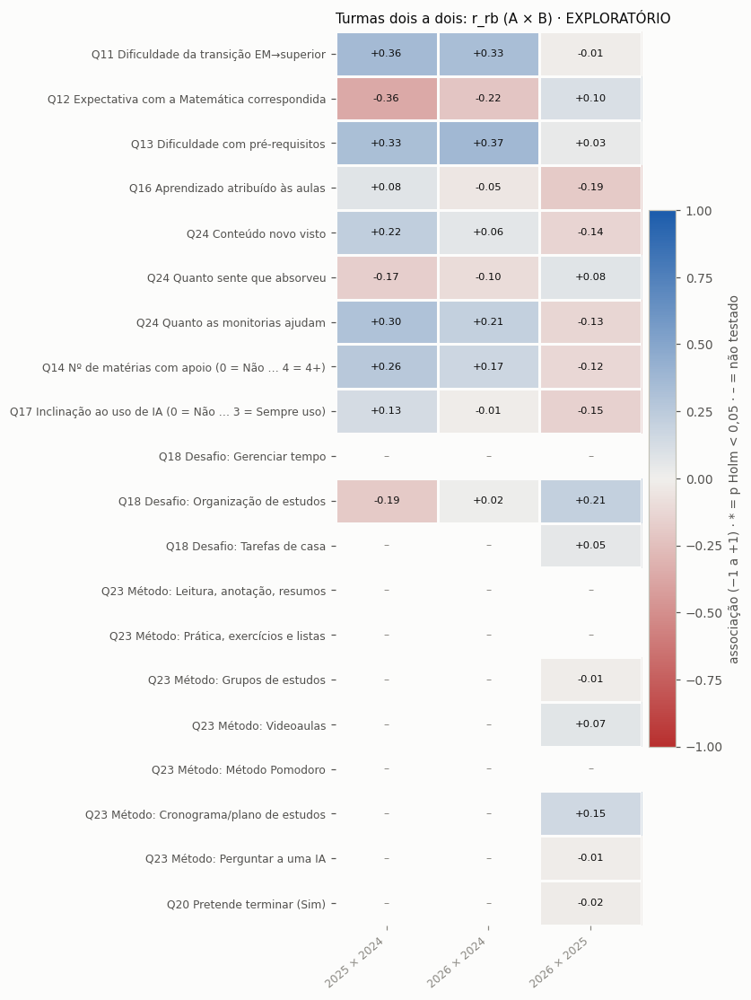

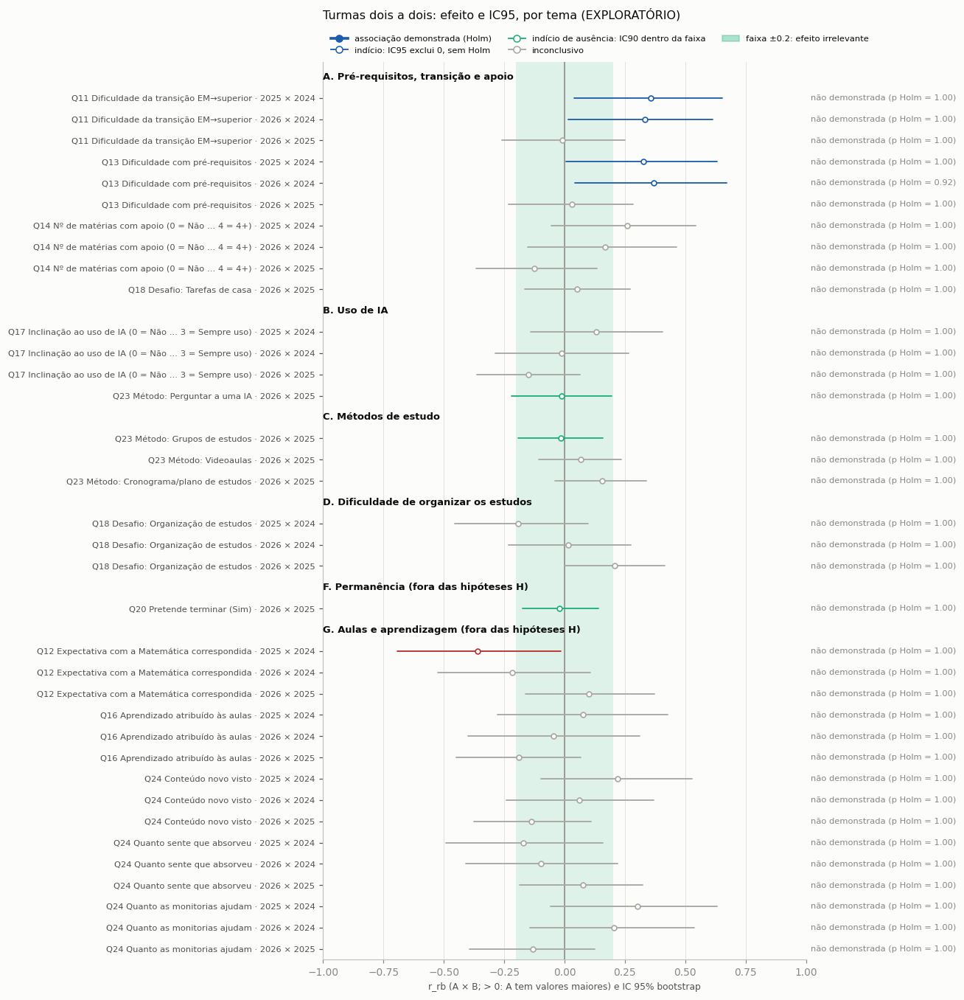

**Perfil de ingresso das turmas (família separada, Holm)** — `EXPLORATÓRIO`

,contraste,desfecho,n_A,n_B,A,B,efeito,ic95_inf,ic95_sup,p,p_holm,sig,classe,nível,status
0,2025 × 2024,Q8 Ingresso pelo ENEM,35,17,,,NaN,NaN,NaN,NaN,NaN,,não testado,,mascarado (célula < N_MIN_CELULA)
1,2025 × 2024,Q9 Estudou (também) em escola privada,35,17,,,NaN,NaN,NaN,NaN,NaN,,não testado,,mascarado (célula < N_MIN_CELULA)
2,2025 × 2024,Q3 Entrou ≥ 1 ano após o EM,35,17,29%,29%,-0.008,-0.297,0.252,1.000,1.000,,inconclusivo,,testado
3,2025 × 2024,Q5 Iniciou outra graduação,35,17,20%,47%,-0.271,-0.536,-0.007,0.056,0.451,,negativa,indicio,testado
4,2025 × 2024,Q7 Impacto da graduação anterior (1–5),7,8,3 [2.5–4],2.5 [1.75–4.25],NaN,NaN,NaN,NaN,NaN,,não testado,,n < N_MIN_GRUPO (só descritiva)
5,2026 × 2024,Q8 Ingresso pelo ENEM,43,17,,,NaN,NaN,NaN,NaN,NaN,,não testado,,mascarado (célula < N_MIN_CELULA)
6,2026 × 2024,Q9 Estudou (também) em escola privada,43,17,,,NaN,NaN,NaN,NaN,NaN,,não testado,,mascarado (célula < N_MIN_CELULA)
7,2026 × 2024,Q3 Entrou ≥ 1 ano após o EM,43,17,40%,29%,0.101,-0.156,0.358,0.560,1.000,,inconclusivo,,testado
8,2026 × 2024,Q5 Iniciou outra graduação,43,17,26%,47%,-0.215,-0.486,0.055,0.131,0.917,,inconclusivo,,testado
9,2026 × 2024,Q7 Impacto da graduação anterior (1–5),11,8,4 [4–5],2.5 [1.75–4.25],NaN,NaN,NaN,NaN,NaN,,não testado,,n < N_MIN_GRUPO (só descritiva)


Não testados: {'mascarado (célula < N_MIN_CELULA)': 4, 'n < N_MIN_GRUPO (só descritiva)': 3}


In [25]:
# Desfechos comuns às duas análises (rótulos com a numeração do Apêndice A)
df["b_terminar"] = utils._indicador(df, "q21_terminar", "Sim")
df["b_enem"] = utils._indicador(df, "q09_forma_ingresso", "ENEM")
df["b_privada"] = df["q10_privada"].astype(float)
df["b_apos1"] = utils._indicador(df, "g_tempo", "Após ≥ 1 ano")
df["b_outra_grad"] = utils._indicador(df, "g_outra_grad", "Iniciou outra graduação")

DESF_05G = {c: utils.rotulo(c) for c in utils.ESCALAS_CENTRAIS}
DESF_05G["q15_apoio_ord"] = "Q14 Nº de matérias com apoio (0 = Não … 4 = 4+)"
DESF_05G["q18_ia_ord"] = "Q17 Inclinação ao uso de IA (0 = Não … 3 = Sempre uso)"
DESF_05G.update({c: f"Q18 Desafio: {utils.ROTULOS[c]}" for c in utils.MULTIPLA["q19"]})
DESF_05G.update({c: f"Q23 Método: {utils.ROTULOS[c]}" for c in utils.MULTIPLA["q24"]})
DESF_05G["b_terminar"] = "Q20 Pretende terminar (Sim)"
BIN_05G = set(utils.MULTIPLA["q19"] + utils.MULTIPLA["q24"]) | {"b_terminar", "b_enem", "b_privada", "b_apos1", "b_outra_grad"}
# Perfil de ingresso: família separada (descreve quem compõe cada grupo, não a percepção)
PERFIL_05G = {"b_enem": "Q8 Ingresso pelo ENEM", "b_privada": "Q9 Estudou (também) em escola privada",
              "b_apos1": "Q3 Entrou ≥ 1 ano após o EM", "b_outra_grad": "Q5 Iniciou outra graduação",
              "q08_impacto_grad": utils.rotulo("q08_impacto_grad")}
COLS_05G = ["contraste", "desfecho", "n_A", "n_B", "A", "B", "efeito", "ic95_inf", "ic95_sup",
            "p", "p_holm", "sig", "classe", "nível", "status"]

def exibir_05g(t, titulo, arquivo):
    mostrar_teste(t[COLS_05G].round(3), titulo)
    t[COLS_05G].round(4).to_csv(arquivo, index=False)
    nt = t[t["status"] != "testado"]
    if len(nt):
        print("Não testados:", nt["status"].value_counts().to_dict())

def figuras_05g(t, desf, arq_mapa, arq_ic, titulo):
    longo = t.rename(columns={"desfecho": "variável", "contraste": "desfecho"})
    utils.grafico_mapa(longo, list(desf.values()), list(dict.fromkeys(t["contraste"])), "efeito",
                       arquivo=arq_mapa, titulo=f"{titulo}: r_rb (A × B) · {ROTULO}")
    plt.show()
    tt = t[t["status"] == "testado"].copy()
    if len(tt):   # agrupado pelo tema da pergunta; dentro do grupo, pergunta a pergunta e contraste a contraste
        ordem_d = {d: i for i, d in enumerate(desf.values())}
        ordem_c = {c: i for i, c in enumerate(dict.fromkeys(t["contraste"]))}
        tt = tt.assign(_o=tt["desfecho"].map(ordem_d) * 10 + tt["contraste"].map(ordem_c)).sort_values("_o")
        tt["grupo"] = [utils.GRUPOS_TEMA[utils.tema(c)] for c in tt["coluna"]]
        tt["rotulo"] = tt["desfecho"] + " · " + tt["contraste"]
        utils.grafico_ic(tt, DELTA_EQUIV, list(utils.GRUPOS_TEMA.values()), ordenar=False, arquivo=arq_ic,
                         titulo=f"{titulo}: efeito e IC95, por tema ({ROTULO})",
                         xlabel="r_rb (A × B; > 0: A tem valores maiores) e IC 95% bootstrap")
        plt.show()

# --- Turmas, dois a dois (A = turma mais recente) ---
T = df["q03_turma"]
CONTR_TURMA = [(f"{a[-4:]} × {b[-4:]}", T == a, T == b)
               for a, b in [("Turma 2025", "Turma 2024"), ("Turma 2026", "Turma 2024"), ("Turma 2026", "Turma 2025")]]
display(Markdown("**n por turma:** " + " · ".join(f"{k}: {v}" for k, v in T.value_counts().sort_index().items())
                 + " — efeito > 0: a turma **mais recente** (A) tem valores maiores."))

t_turma = utils.contrastes(df, CONTR_TURMA, DESF_05G, BIN_05G, N_MIN_GRUPO, N_MIN_CELULA, DELTA_EQUIV, B=B_BOOT)
exibir_05g(t_turma, f"Turmas dois a dois — {(t_turma.status == 'testado').sum()} testes, Holm na família",
           "tabelas/exploratorio/05g_turmas.csv")
display(Markdown("**Placar** — em quantas perguntas cada turma do par fica acima da outra:"))
display(utils.placar_contrastes(t_turma))
figuras_05g(t_turma, DESF_05G, "figuras/exploratorio/05g_turmas_mapa.png", f"{PASTA_IC}/04_turmas_dois_a_dois.png", "Turmas dois a dois")

t_turma_perfil = utils.contrastes(df, CONTR_TURMA, PERFIL_05G, BIN_05G, N_MIN_GRUPO, N_MIN_CELULA, DELTA_EQUIV, B=B_BOOT)
exibir_05g(t_turma_perfil, "Perfil de ingresso das turmas (família separada, Holm)", "tabelas/exploratorio/05g_turmas_perfil.csv")

#### Entrou ≥ 1 ano após o EM **sem** ter iniciado outra graduação

No mapa 05d, "Entrou ≥ 1 ano após o EM" aparece com indícios negativos em transição, aulas e monitorias. Mas a maioria desse grupo iniciou outra graduação, então o tempo fora e a graduação anterior estão misturados. Aqui o grupo é separado em três:
- **Imediatamente** (independentemente de outra graduação);
- **≥ 1 ano, com outra graduação** (iniciada, completa ou não);
- **≥ 1 ano, sem outra graduação** — o grupo agregado.

Os contrastes repetem as mesmas perguntas da análise das turmas. O último ("≥ 1 ano (todos) × Imediatamente") reproduz a linha do mapa 05d, para comparar lado a lado. O grupo agregado **não é cruzado com a turma** (células pequenas). Se ele tiver n < `N_MIN_GRUPO`, os contrastes dele saem só com a descritiva, e passam a ser testados sozinhos quando o grupo chegar a 10.

,n
Imediatamente,63
"≥ 1 ano,\ncom outra grad.",23
"≥ 1 ano,\nsem outra grad.",9


**Nota:** o grupo agregado tem n < `N_MIN_GRUPO` = 10. Os contrastes com ele mostram só a descritiva (mediana [Q1–Q3] ou %), sem teste.

**Tempo até o ingresso × outra graduação — 30 testes, Holm na família** — `EXPLORATÓRIO`

,contraste,desfecho,n_A,n_B,A,B,efeito,ic95_inf,ic95_sup,p,p_holm,sig,classe,nível,status
0,≥1 ano sem outra grad. × Imediatamente,Q11 Dificuldade da transição EM→superior,9,63,8 [4–8],8 [7–9],NaN,NaN,NaN,NaN,NaN,,não testado,,n < N_MIN_GRUPO (só descritiva)
1,≥1 ano sem outra grad. × Imediatamente,Q12 Expectativa com a Matemática correspondida,9,63,7 [5–8],8 [6.5–9],NaN,NaN,NaN,NaN,NaN,,não testado,,n < N_MIN_GRUPO (só descritiva)
2,≥1 ano sem outra grad. × Imediatamente,Q13 Dificuldade com pré-requisitos,9,63,7 [3–7],7 [3.5–8],NaN,NaN,NaN,NaN,NaN,,não testado,,n < N_MIN_GRUPO (só descritiva)
3,≥1 ano sem outra grad. × Imediatamente,Q16 Aprendizado atribuído às aulas,9,63,3 [2–4],6 [4–7],NaN,NaN,NaN,NaN,NaN,,não testado,,n < N_MIN_GRUPO (só descritiva)
4,≥1 ano sem outra grad. × Imediatamente,Q24 Conteúdo novo visto,9,63,9 [7–10],9 [7–10],NaN,NaN,NaN,NaN,NaN,,não testado,,n < N_MIN_GRUPO (só descritiva)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,≥1 ano (todos) × Imediatamente,Q23 Método: Cronograma/plano de estudos,32,63,28%,22%,0.059,-0.129,0.247,0.614,1.0,,inconclusivo,,testado
84,≥1 ano (todos) × Imediatamente,Q23 Método: Perguntar a uma IA,32,63,81%,67%,0.146,-0.028,0.319,0.156,1.0,,inconclusivo,,testado
85,≥1 ano (todos) × Imediatamente,Q20 Pretende terminar (Sim),32,63,,,NaN,NaN,NaN,NaN,NaN,,não testado,,mascarado (célula < N_MIN_CELULA)
86,≥1 ano (todos) × Imediatamente,Q8 Ingresso pelo ENEM,32,63,28%,24%,0.043,-0.145,0.246,0.803,1.0,,inconclusivo,,testado


Não testados: {'n < N_MIN_GRUPO (só descritiva)': 44, 'mascarado (célula < N_MIN_CELULA)': 14}


lado                                                                 A maior  B maior
contraste                              evidência                                     
≥1 ano (todos) × Imediatamente         inconclusivo / sem diferença        8        9
                                       indício                             0        1
≥1 ano com outra grad. × Imediatamente inconclusivo / sem diferença        4        8

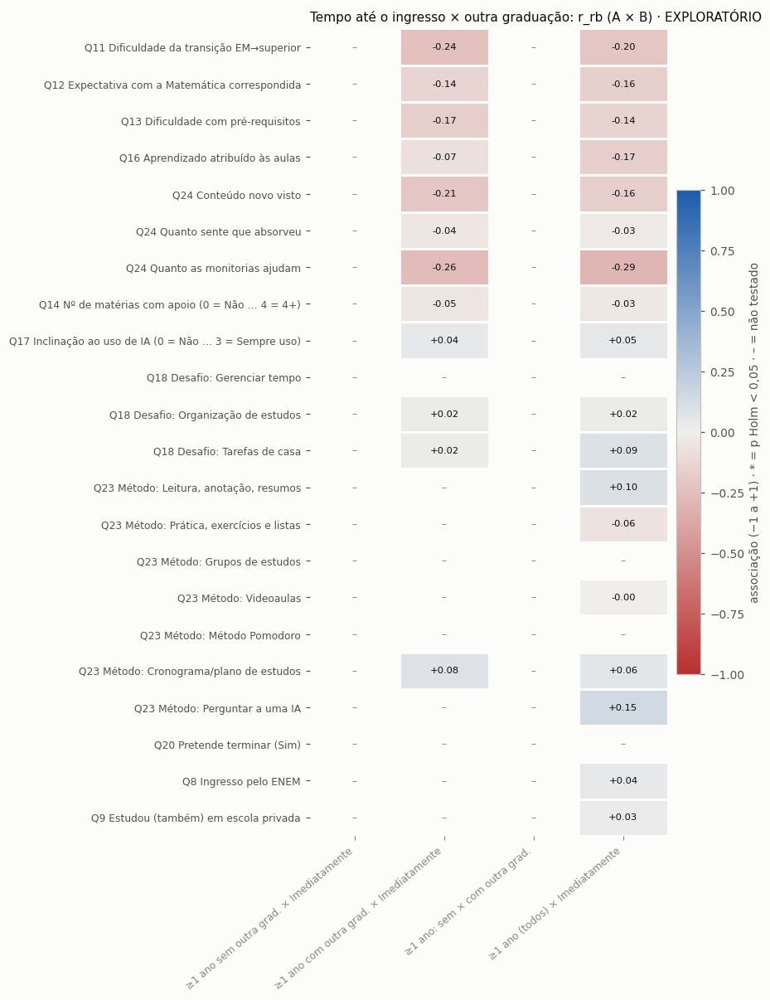

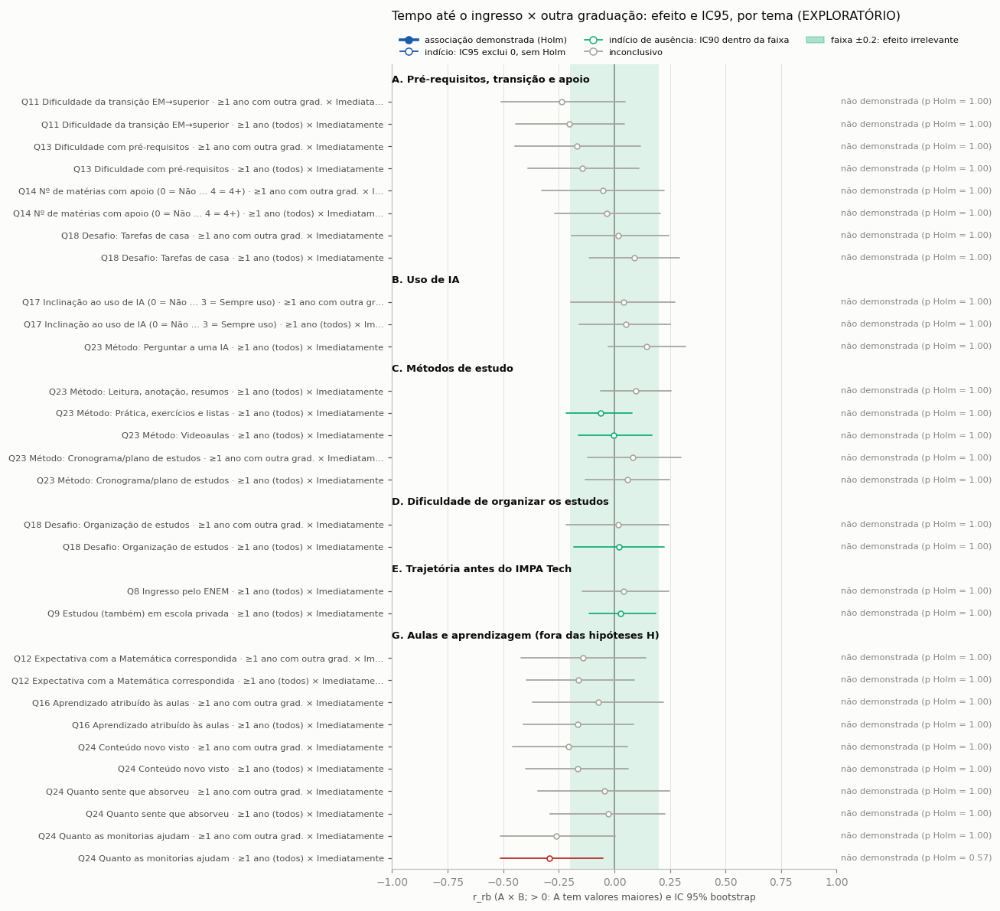

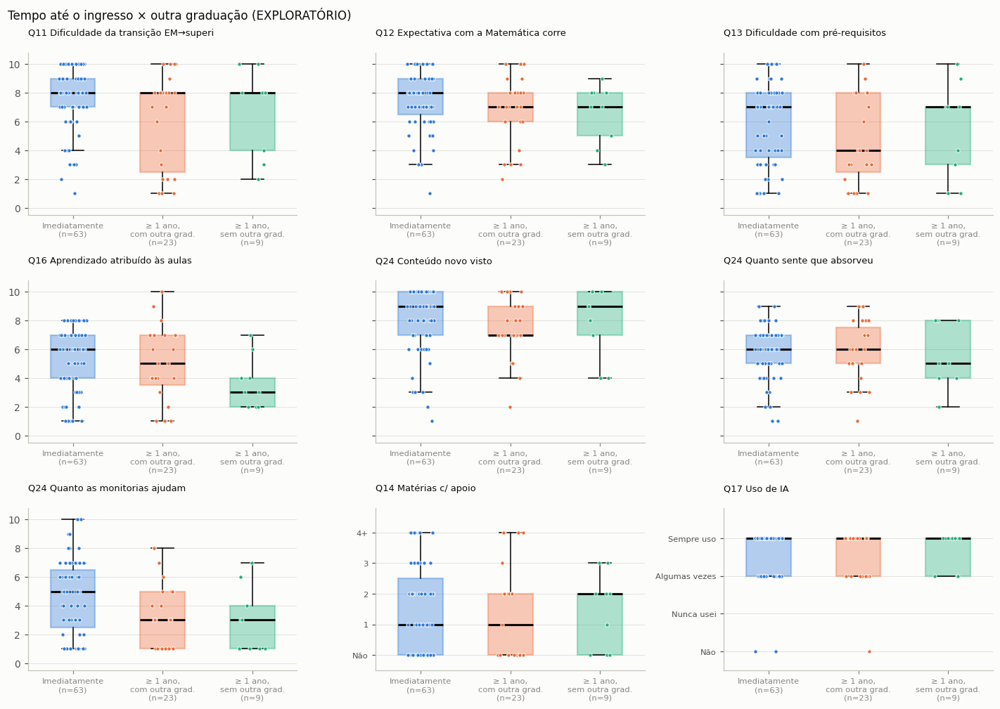

In [26]:
apos = df["q04_ingresso_tempo"].notna() & (df["q04_ingresso_tempo"] != "Imediatamente")
outra = df["q06_outra_grad"].str.startswith("Sim").fillna(False).astype(bool)
G_IMED = df["q04_ingresso_tempo"] == "Imediatamente"
G_COM, G_SEM = apos & outra, apos & ~outra
CONTR_ING = [("≥1 ano sem outra grad. × Imediatamente", G_SEM, G_IMED),
             ("≥1 ano com outra grad. × Imediatamente", G_COM, G_IMED),
             ("≥1 ano: sem × com outra grad.", G_SEM, G_COM),
             ("≥1 ano (todos) × Imediatamente", apos, G_IMED)]
tam_ing = pd.DataFrame({"n": [int(G_IMED.sum()), int(G_COM.sum()), int(G_SEM.sum())]},
                       index=["Imediatamente", "≥ 1 ano,\ncom outra grad.", "≥ 1 ano,\nsem outra grad."])
display(utils.suprimir(tam_ing, N_MIN_CELULA))
if G_SEM.sum() < N_MIN_GRUPO:
    display(Markdown(f"**Nota:** o grupo agregado tem n < `N_MIN_GRUPO` = {N_MIN_GRUPO}. Os contrastes com ele "
                     "mostram só a descritiva (mediana [Q1–Q3] ou %), sem teste."))

DESF_ING = {**DESF_05G, "b_enem": PERFIL_05G["b_enem"], "b_privada": PERFIL_05G["b_privada"]}
t_ing = utils.contrastes(df, CONTR_ING, DESF_ING, BIN_05G, N_MIN_GRUPO, N_MIN_CELULA, DELTA_EQUIV, B=B_BOOT)
exibir_05g(t_ing, f"Tempo até o ingresso × outra graduação — {(t_ing.status == 'testado').sum()} testes, Holm na família",
           "tabelas/exploratorio/05g_ingresso_outra_grad.csv")
display(utils.placar_contrastes(t_ing))
figuras_05g(t_ing, DESF_ING, "figuras/exploratorio/05g_ingresso_mapa.png", f"{PASTA_IC}/05_ingresso_outra_graduacao.png",
            "Tempo até o ingresso × outra graduação")

# Boxplots dos três grupos (escalas e ordinais), se nenhum grupo tiver n < N_MIN_CELULA
g3 = pd.Series(pd.Categorical(np.select([G_IMED, G_COM, G_SEM], list(tam_ing.index), None),
                              categories=list(tam_ing.index)), index=df.index)
if tam_ing["n"].min() >= N_MIN_CELULA:
    desf_box = utils.ESCALAS_CENTRAIS + ["q15_apoio_ord", "q18_ia_ord"]
    utils.grafico_grupos(df[desf_box].assign(_g=g3), "_g", desf_box, ncol=3, largura=13,
                         arquivo="figuras/exploratorio/05g_ingresso_grupos.png",
                         titulo=f"Tempo até o ingresso × outra graduação ({ROTULO})")
    plt.show()
else:
    print(f"Gráfico omitido: algum grupo tem n < N_MIN_CELULA = {N_MIN_CELULA} (privacidade).")

### Interpretação (05g)

*Perguntas-guia — a escrever pela aluna:*
- Alguma turma fica acima das outras de forma consistente (placar), ou as diferenças aparecem só em perguntas isoladas?
- As diferenças entre turmas podem ser explicadas pela etapa do curso em que cada uma está (1º, 2º ou 3º ano), e não pela turma em si? Como o texto deixaria isso claro?
- O perfil de ingresso (ENEM, escola, tempo até o ingresso) muda entre as turmas? Se muda, isso pode explicar alguma diferença de percepção?
- Os indícios de "≥ 1 ano após o EM" no mapa 05d aparecem também em quem **não** iniciou outra graduação, ou só em quem iniciou?
- Com o grupo agregado ainda abaixo de `N_MIN_GRUPO`, que direção você registraria como hipótese para a amostra final?

### 05h · Agregações: permanência em risco, índice de dificuldade, lacuna de absorção e contagens

Quatro variáveis novas, formadas pela combinação de perguntas do Apêndice A. **Todas foram definidas depois de ver a prévia, então são exploratórias.**

| Variável | Como é formada | Para quê |
|---|---|---|
| **Permanência em risco** | reprovou/trancou (Q25 ≠ "Não") **ou** não pretende / não tem certeza se vai terminar (Q20) | Q25 e Q20 sozinhas têm grupos pequenos demais; juntas permitem relacionar os dados à reprovação e à permanência |
| **Índice de dificuldade** | média dos **postos** de cada pessoa em Q11 (transição), Q13 (pré-requisitos) e Q14 (nº de matérias com apoio) | as três andam juntas; um índice é mais estável e troca três testes por um |
| **Lacuna de absorção** | Q24: a nota de "absorveu" é menor, igual ou maior que a de "conteúdo novo"? | usa só a direção da comparação, não a diferença entre as notas |
| **Contagens** | nº de desafios marcados (Q18, 0–3) e nº de métodos marcados (Q23, 0–7) | resumem as perguntas de múltipla escolha numa variável ordinal |

**Cuidados:**
- O grupo "permanência em risco" junta um fato passado (reprovar ou trancar) e uma intenção futura (terminar o curso). É uma escolha conceitual, a justificar no texto.
- O índice usa postos, não a média das notas: ele compara as pessoas entre si dentro da amostra, e não é uma nota de 0 a 10.
- Os contrastes do grupo de risco usam a mesma função e as mesmas travas do 05g (n < `N_MIN_GRUPO` → só descritiva; células < `N_MIN_CELULA` → mascaradas). O grupo não é cruzado com a turma.

**Índice de dificuldade** — correlação de Spearman entre as três perguntas que o formam:

,Q11 Dificuldade da transição EM→superior,Q13 Dificuldade com pré-requisitos,Q14 Matérias c/ apoio
Q11 Dificuldade da transição EM→superior,1.00,0.51,0.43
Q13 Dificuldade com pré-requisitos,0.51,1.00,0.61
Q14 Matérias c/ apoio,0.43,0.61,1.00


Índice calculado para 95 de 95 pessoas (quem respondeu às três).

**Lacuna de absorção (Q24)** — comparação das duas notas da mesma pessoa:

,n,%
Absorveu menos que o conteúdo novo,73,76.8
Absorveu o mesmo,11,11.6
Absorveu mais que o conteúdo novo,11,11.6


**Teste do sinal: 'absorveu menos' é mais comum que 'absorveu mais'? (empates fora)** — `EXPLORATÓRIO`

,absorveu menos,absorveu mais,"p (teste do sinal, bilateral)"
0,73,11,2.2e-12


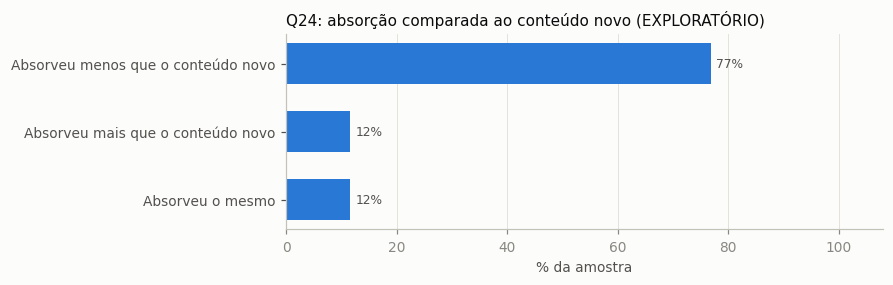

**Nº de desafios marcados (Q18)** — mediana 2 [1–2]

,n,%
0,6,6.3
1,26,27.4
2,43,45.3
3,20,21.1


**Nº de métodos marcados (Q23)** — mediana 3 [2–4]

,n,%
0,<5,—
1,suprimido,—
2,17,17.9
3,38,40.0
4,24,25.3
5,7,7.4
6,<5,—


In [27]:
# --- Variáveis agregadas ---
df["n_desafios"] = df[utils.MULTIPLA["q19"]].sum(axis=1)
df["n_metodos"] = df[utils.MULTIPLA["q24"]].sum(axis=1)
COLS_DIF = ["q12_transicao", "q14_prereq", "q15_apoio_ord"]
df["indice_dif"] = utils.indice_postos(df, COLS_DIF)
_lac = np.sign(df["q25_novo"] - df["q25_absorveu"])
df["b_lacuna"] = (_lac > 0).astype(float).where(_lac.notna())
_reprovou = df["q26_trancou"].notna() & (df["q26_trancou"] != "Não")
_incerto = df["q21_terminar"].isin(["Não", "Não tenho certeza"])
df["g_risco"] = (_reprovou | _incerto).astype(float).where(df["q26_trancou"].notna() | df["q21_terminar"].notna())

# --- Índice de dificuldade: as três perguntas andam juntas? ---
display(Markdown("**Índice de dificuldade** — correlação de Spearman entre as três perguntas que o formam:"))
display(df[COLS_DIF].corr("spearman").rename(index=utils.rotulo, columns=utils.rotulo).round(2))
display(Markdown(f"Índice calculado para {int(df['indice_dif'].notna().sum())} de {N} pessoas "
                 "(quem respondeu às três)."))

# --- Lacuna de absorção (descritiva + teste do sinal) ---
from scipy.stats import binomtest
lacuna = pd.Series(pd.Categorical(_lac.map({1.0: "Absorveu menos que o conteúdo novo", 0.0: "Absorveu o mesmo",
                                             -1.0: "Absorveu mais que o conteúdo novo"}),
                                  categories=["Absorveu menos que o conteúdo novo", "Absorveu o mesmo",
                                              "Absorveu mais que o conteúdo novo"]), index=df.index)
tab_lac = utils.frequencias(lacuna.dropna(), N_MIN_CELULA)
display(Markdown("**Lacuna de absorção (Q24)** — comparação das duas notas da mesma pessoa:"))
display(tab_lac)
k_menos, k_mais = int((_lac > 0).sum()), int((_lac < 0).sum())
if min(k_menos, k_mais) >= N_MIN_CELULA:
    teste_sinal = binomtest(k_menos, k_menos + k_mais, 0.5)
    mostrar_teste(pd.DataFrame({"absorveu menos": [k_menos], "absorveu mais": [k_mais],
                                "p (teste do sinal, bilateral)": [f"{teste_sinal.pvalue:.1e}"]}),
                  "Teste do sinal: 'absorveu menos' é mais comum que 'absorveu mais'? (empates fora)")
    utils.grafico_barras(100 * lacuna.value_counts(normalize=True).reindex(lacuna.cat.categories),
                         arquivo="figuras/exploratorio/05h_lacuna.png",
                         titulo=f"Q24: absorção comparada ao conteúdo novo ({ROTULO})")
    plt.show()
else:
    print(f"Teste e gráfico omitidos: alguma categoria tem n < N_MIN_CELULA = {N_MIN_CELULA}.")
tab_lac.to_csv("tabelas/exploratorio/05h_lacuna.csv")

# --- Contagens de desafios e de métodos ---
for col, nome, maximo in [("n_desafios", "Nº de desafios marcados (Q18)", 3), ("n_metodos", "Nº de métodos marcados (Q23)", 7)]:
    s = pd.Series(pd.Categorical(df[col], categories=range(maximo + 1)), index=df.index)
    t = utils.frequencias(s, N_MIN_CELULA)
    display(Markdown(f"**{nome}** — mediana {df[col].median():g} [{df[col].quantile(.25):g}–{df[col].quantile(.75):g}]"))
    display(t)
    t.to_csv(f"tabelas/exploratorio/05h_{col}.csv")

#### Permanência em risco × demais

Mesmas perguntas do 05g, mais as variáveis agregadas. A Q20 sai da lista porque faz parte da definição do grupo. Efeito > 0: o grupo em risco tem valores maiores.

**Permanência em risco:** 23 · **demais:** 72

**Permanência em risco × demais — 21 testes, Holm na família** — `EXPLORATÓRIO`

,contraste,desfecho,n_A,n_B,A,B,efeito,ic95_inf,ic95_sup,p,p_holm,sig,classe,nível,status
0,Permanência em risco × demais,Q11 Dificuldade da transição EM→superior,23,72,8 [6.5–10],8 [6–9],0.094,-0.172,0.355,0.494,1.000,,inconclusivo,,testado
1,Permanência em risco × demais,Q12 Expectativa com a Matemática correspondida,23,72,6 [4–7.5],8 [7–9],-0.379,-0.636,-0.100,0.006,0.113,,negativa,indicio,testado
2,Permanência em risco × demais,Q13 Dificuldade com pré-requisitos,23,72,7 [4–8],5.5 [3–8],0.152,-0.111,0.409,0.273,1.000,,inconclusivo,,testado
3,Permanência em risco × demais,Q16 Aprendizado atribuído às aulas,23,72,5 [3–6.5],5 [3–7],-0.026,-0.296,0.258,0.854,1.000,,inconclusivo,,testado
4,Permanência em risco × demais,Q24 Conteúdo novo visto,23,72,9 [6–10],8 [7–10],0.020,-0.249,0.290,0.886,1.000,,inconclusivo,,testado
5,Permanência em risco × demais,Q24 Quanto sente que absorveu,23,72,5 [4–6.5],6 [5–7],-0.327,-0.561,-0.077,0.017,0.308,,negativa,indicio,testado
6,Permanência em risco × demais,Q24 Quanto as monitorias ajudam,23,72,5 [1.5–6.5],4 [2–6],0.040,-0.249,0.309,0.775,1.000,,inconclusivo,,testado
7,Permanência em risco × demais,Q14 Nº de matérias com apoio (0 = Não … 4 = 4+),23,72,3 [0.5–4],1 [0–2],0.389,0.120,0.661,0.004,0.076,,positiva,indicio,testado
8,Permanência em risco × demais,Q17 Inclinação ao uso de IA (0 = Não … 3 = Sempre uso),23,72,3 [2.5–3],3 [2–3],0.167,-0.042,0.367,0.159,1.000,,inconclusivo,,testado
9,Permanência em risco × demais,Q18 Desafio: Gerenciar tempo,23,72,,,NaN,NaN,NaN,NaN,NaN,,não testado,,mascarado (célula < N_MIN_CELULA)


Não testados: {'mascarado (célula < N_MIN_CELULA)': 6}


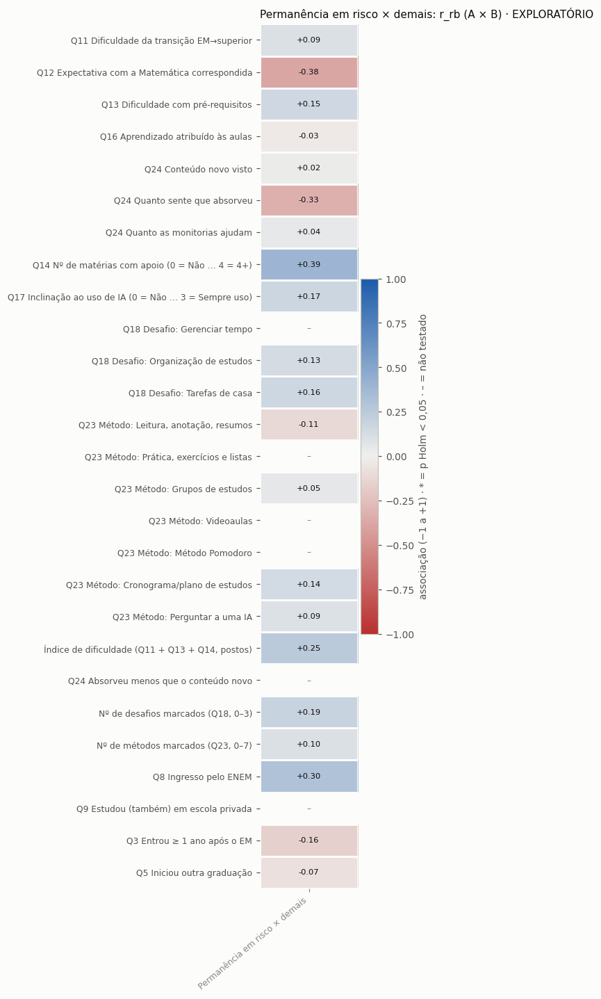

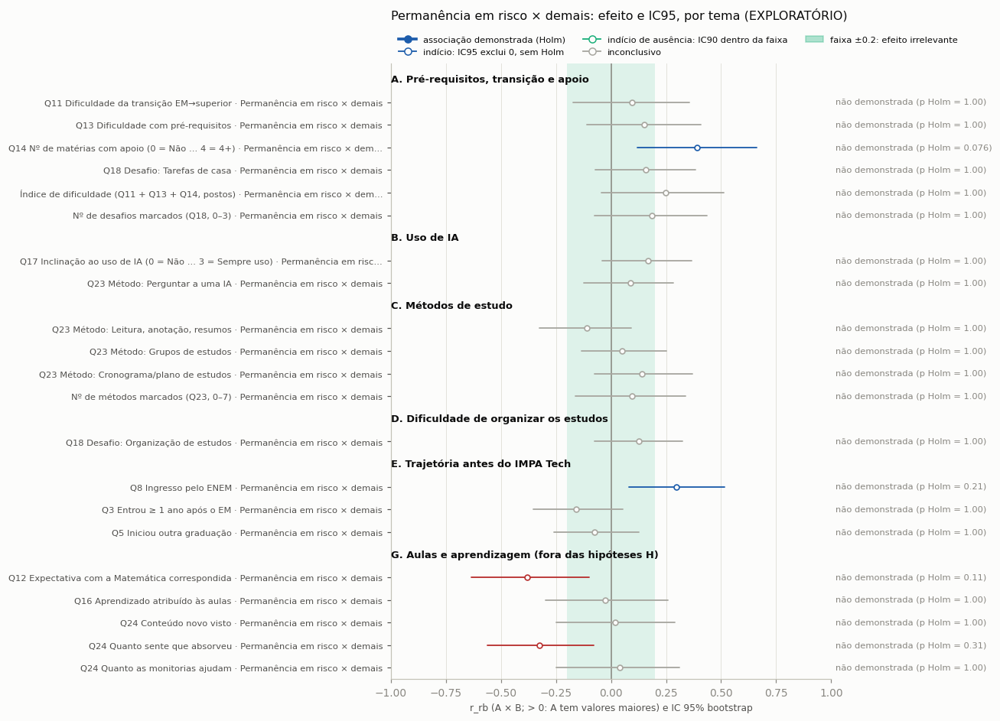

In [28]:
n_risco, n_demais = int((df["g_risco"] == 1).sum()), int((df["g_risco"] == 0).sum())
display(Markdown(f"**Permanência em risco:** {n_risco} · **demais:** {n_demais}"))
if min(n_risco, n_demais) < N_MIN_GRUPO:
    display(Markdown(f"**Nota:** algum grupo tem n < `N_MIN_GRUPO` = {N_MIN_GRUPO}; só descritiva."))

DESF_RISCO = {k: v for k, v in DESF_05G.items() if k != "b_terminar"}
DESF_RISCO.update({"indice_dif": "Índice de dificuldade (Q11 + Q13 + Q14, postos)",
                   "b_lacuna": "Q24 Absorveu menos que o conteúdo novo",
                   "n_desafios": "Nº de desafios marcados (Q18, 0–3)",
                   "n_metodos": "Nº de métodos marcados (Q23, 0–7)"})
DESF_RISCO.update({k: PERFIL_05G[k] for k in ["b_enem", "b_privada", "b_apos1", "b_outra_grad"]})
BIN_RISCO = BIN_05G | {"b_lacuna"}
t_risco = utils.contrastes(df, [("Permanência em risco × demais", df["g_risco"] == 1, df["g_risco"] == 0)],
                           DESF_RISCO, BIN_RISCO, N_MIN_GRUPO, N_MIN_CELULA, DELTA_EQUIV, B=B_BOOT)
exibir_05g(t_risco, f"Permanência em risco × demais — {(t_risco.status == 'testado').sum()} testes, Holm na família",
           "tabelas/exploratorio/05h_risco.csv")
figuras_05g(t_risco, DESF_RISCO, "figuras/exploratorio/05h_risco_mapa.png", f"{PASTA_IC}/06_permanencia_em_risco.png",
            "Permanência em risco × demais")

#### Índice de dificuldade × percepção, IA, desafios e métodos

O índice substitui Q11, Q13 e Q14 nas associações: em vez de três testes por pergunta, um só. Escalas e contagens usam Spearman ρ; desafios e métodos usam r_rb (marcou × não marcou; > 0: quem marcou tem índice maior). Holm sobre a família; classificação igual à da seção 11.

**Índice de dificuldade — família de 17 testes, Holm** — `EXPLORATÓRIO`

,id,x,y,medida,n_1,n_0,mediana_1,mediana_0,efeito,ic95_inf,ic95_sup,p,p_holm,p_tost_holm,classificação
0,E1,Índice de dificuldade,Q12 Expectativa correspondida,ρ,95,NaN,NaN,NaN,-0.077,-0.282,0.128,0.456,1.000,1.0,Inconclusivo
1,E2,Índice de dificuldade,Q16 Aprendizado nas aulas,ρ,95,NaN,NaN,NaN,0.279,0.070,0.468,0.006,0.075,1.0,Indício de associação positiva
2,E3,Índice de dificuldade,Q24 Conteúdo novo,ρ,95,NaN,NaN,NaN,0.415,0.223,0.584,0.000,0.000,1.0,Associação positiva
3,E4,Índice de dificuldade,Q24 Absorção,ρ,95,NaN,NaN,NaN,-0.252,-0.435,-0.059,0.014,0.137,1.0,Indício de associação negativa
4,E5,Índice de dificuldade,Q24 Monitorias,ρ,95,NaN,NaN,NaN,0.335,0.136,0.520,0.001,0.014,1.0,Associação positiva
5,E6,Índice de dificuldade,Q17 Inclinação à IA,ρ,95,NaN,NaN,NaN,0.419,0.243,0.579,0.000,0.000,1.0,Associação positiva
6,E7,Índice de dificuldade,Nº de métodos,ρ,95,NaN,NaN,NaN,0.222,0.028,0.399,0.031,0.276,1.0,Indício de associação positiva
7,E8,Índice de dificuldade,Nº de desafios,ρ,95,NaN,NaN,NaN,0.293,0.091,0.486,0.004,0.055,1.0,Indício de associação positiva
8,G1,Desafio: Gerenciar tempo,Índice de dificuldade,r_rb,81,14.0,0.519,0.454,0.173,-0.154,0.496,0.306,1.000,1.0,Inconclusivo
9,G2,Desafio: Organização de estudos,Índice de dificuldade,r_rb,61,34.0,0.577,0.332,0.343,0.100,0.569,0.006,0.075,1.0,Indício de associação positiva


,associações
classificação,
Inconclusivo,7
Indício de associação positiva,6
Associação positiva,3
Indício de associação negativa,1
grupo insuficiente,1


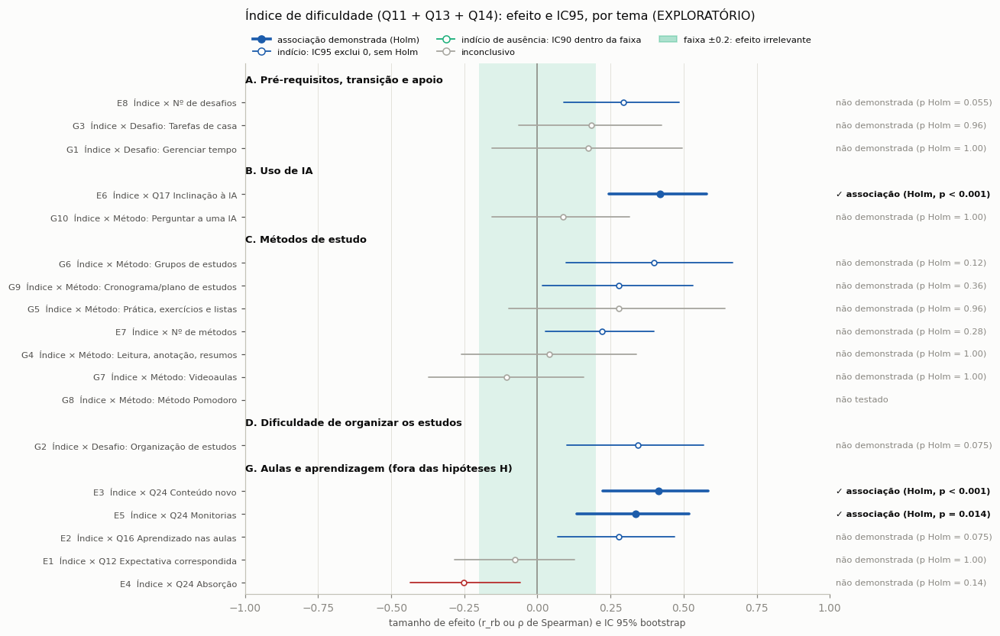

In [29]:
NOMES_IND = {"q13_expectativa": "Q12 Expectativa correspondida", "q17_aulas": "Q16 Aprendizado nas aulas",
             "q25_novo": "Q24 Conteúdo novo", "q25_absorveu": "Q24 Absorção", "q25_monitoria": "Q24 Monitorias",
             "q18_ia_ord": "Q17 Inclinação à IA", "n_metodos": "Nº de métodos", "n_desafios": "Nº de desafios"}
NOMES_IND.update({c: f"Desafio: {utils.ROTULOS[c]}" for c in utils.MULTIPLA["q19"]})
NOMES_IND.update({c: f"Método: {utils.ROTULOS[c]}" for c in utils.MULTIPLA["q24"]})
d_ind = df[["indice_dif"] + list(NOMES_IND)].astype(float).rename(columns={"indice_dif": "Índice de dificuldade", **NOMES_IND})
ESCALAS_IND = ["q13_expectativa", "q17_aulas", "q25_novo", "q25_absorveu", "q25_monitoria", "q18_ia_ord", "n_metodos", "n_desafios"]
FAMILIA_IND = ([{"id": f"E{i}", "bloco": "E", "x": "Índice de dificuldade", "y": NOMES_IND[c]} for i, c in enumerate(ESCALAS_IND, 1)]
               + [{"id": f"G{i}", "bloco": "G", "x": NOMES_IND[c], "y": "Índice de dificuldade"}
                  for i, c in enumerate(utils.MULTIPLA["q19"] + utils.MULTIPLA["q24"], 1)])
t_ind = utils.associacoes_familia(d_ind, FAMILIA_IND, N_MIN_GRUPO, DELTA_EQUIV, B=B_BOOT, semente=0, alpha=ALPHA)

COLS_IND = ["id", "x", "y", "medida", "n_1", "n_0", "mediana_1", "mediana_0", "efeito", "ic95_inf", "ic95_sup",
            "p", "p_holm", "p_tost_holm", "classificação"]
t_ind_ex = t_ind.reindex(columns=COLS_IND).copy()
for g in ("1", "0"):   # privacidade: grupo com n < N_MIN_CELULA não mostra n nem mediana
    peq = t_ind_ex[f"n_{g}"].apply(lambda v: pd.notna(v) and 0 < v < N_MIN_CELULA)
    t_ind_ex[f"n_{g}"] = t_ind_ex[f"n_{g}"].astype(object)
    t_ind_ex.loc[peq, f"n_{g}"] = f"<{N_MIN_CELULA}"
    t_ind_ex.loc[peq, f"mediana_{g}"] = np.nan
mostrar_teste(t_ind_ex.round(3), f"Índice de dificuldade — família de {t_ind['p'].notna().sum()} testes, Holm")
display(t_ind["classificação"].value_counts().to_frame("associações"))
t_ind_ex.round(4).to_csv("tabelas/exploratorio/05h_indice_dificuldade.csv", index=False)
_outra = np.where(t_ind["x"] == "Índice de dificuldade", t_ind["y"], t_ind["x"])
t_ind_g = utils.ic_familia(t_ind).assign(rotulo=[f"{i}  Índice × {o}" for i, o in zip(t_ind["id"], _outra)],
                                         grupo=[utils.GRUPOS_TEMA[utils.tema(o)] for o in _outra])
utils.grafico_ic(t_ind_g, DELTA_EQUIV, list(utils.GRUPOS_TEMA.values()), arquivo=f"{PASTA_IC}/07_indice_dificuldade.png",
                 titulo=f"Índice de dificuldade (Q11 + Q13 + Q14): efeito e IC95, por tema ({ROTULO})")
plt.show()

### Interpretação (05h)

*Perguntas-guia — a escrever pela aluna:*
- O grupo "permanência em risco" difere dos demais em quais perguntas? Essas diferenças conversam com a literatura sobre evasão citada na introdução?
- Faz sentido, para o artigo, juntar reprovação/trancamento e incerteza sobre terminar num grupo só? Como justificar essa escolha no texto?
- As três perguntas do índice de dificuldade andam juntas o bastante para serem tratadas como uma medida só?
- O índice mostra algo que as três perguntas separadas não mostravam, ou só confirma o que já aparecia?
- A lacuna de absorção (absorver menos do que o conteúdo novo) é compatível com a percepção de que o ritmo do curso é acelerado (Q17)?
- O número de métodos ou de desafios diz algo diferente dos métodos e desafios tomados um a um?

### 05i · Questões da carta aberta dos estudantes: hipóteses e nível das relações

A *Carta aberta à comunidade do IMPA Tech* (estudantes, out./2026; 44 respostas a um formulário e rodas de conversa com mais de 60 alunos) levanta temas que o questionário mede, em parte, de forma indireta:

| Tema da carta | O que a carta relata | Variáveis do questionário |
|---|---|---|
| Desigualdade nas condições de partida | familiaridade desigual com conteúdos de olimpíada; proposta de pré-curso | Q8 ingresso (ENEM × medalhas), Q11 transição, Q13 pré-requisitos, Q24 conteúdo novo, índice de dificuldade |
| Organização pedagógica e ritmo | excesso de conteúdo em períodos curtos, acúmulo de listas e testes | lacuna de absorção (Q24), Q18 desafios (gerenciar tempo, tarefas), nº de desafios |
| Individualismo, cooperação e IA | vergonha de expor dúvidas; IA como "principal companhia de estudo" | Q23 grupos de estudo e "perguntar a uma IA", Q17 inclinação à IA, Q24 monitorias e absorção |
| Permanência e medo da reprovação | perda de moradia e bolsa, desligamento | grupo "permanência em risco" (Q20 + Q25), Q12 expectativa, Q14 apoio |
| Aulas práticas | experiências desiguais entre disciplinas | Q16 (junta aulas teóricas e práticas: não separa as práticas) |

**O questionário não mede:** saúde mental, normalização e correção de provas, PICME, professores de prática em separado, infraestrutura e moradia. Esses temas só podem entrar no artigo pela discussão (citando a carta como documento) ou pelas respostas abertas da Q21.

**Hipóteses C01–C16** (texto em `docs/hipoteses.md`): foram formuladas a partir da carta, mas por quem já tinha visto a prévia. **C17–C22** (família `carta-2`, Holm separado, para não mudar o ajuste de C01–C16) foram acrescentadas depois das seções 05g–05i, para temas da carta que C01–C16 não cobriam: medo da reprovação × aprendizagem, sobrecarga × IA, IA × estudo em grupo, escola e ENEM × permanência, e o excesso de conteúdo (lacuna de absorção como regra, teste de uma amostra). Quando o desfecho é 0/1 (C19, C21), r_rb é a diferença de proporções, e o teste é mascarado se alguma célula tiver menos de `N_MIN_CELULA` pessoas. Como as H01–H52, são testadas com todas as respostas juntas, de forma exploratória.

**Nível das relações:** uma matriz e uma rede com o ρ de Spearman entre 27 variáveis, a mesma medida para todos os pares (entre duas variáveis 0/1, ρ = φ). Holm sobre todos os pares; classificação igual à do 05f. Pares derivados um do outro (por exemplo, a lacuna e as duas notas da Q24 que a formam) não são calculados; pares 0/1 × 0/1 com célula < `N_MIN_CELULA` são mascarados.

**Hipóteses da carta C01–C22 — todas as respostas (N = 95); Holm por família** — `EXPLORATÓRIO`

,família,hipótese,sinal,medida,n_grupo,n_resto,efeito,ic95_inf,ic95_sup,p,p_holm,resultado,teste
id,,,,,,,,,,,,,
C01,carta,ENEM → mais dificuldade com pré-requisitos,+,r_rb,24,71.0,0.265258,-0.001188,0.51586,0.025669,0.256686,não sobrevive a Holm,Mann-Whitney U unilateral
C02,carta,ENEM → transição mais difícil,+,r_rb,24,71.0,0.22946,-0.025235,0.473019,0.044856,0.358851,não sobrevive a Holm,Mann-Whitney U unilateral
C03,carta,ENEM → mais conteúdo novo,+,r_rb,24,71.0,0.142606,-0.129695,0.403771,0.143568,0.476286,não sobrevive a Holm,Mann-Whitney U unilateral
C04,carta,ENEM → índice de dificuldade maior,+,r_rb,24,71.0,0.300469,0.034624,0.549912,0.014312,0.157435,não sobrevive a Holm,Mann-Whitney U unilateral
C05,carta,Desafio gerenciar tempo → mais lacuna de absorção,+,r_rb,81,14.0,0.063492,-0.175485,0.339506,0.304996,0.476286,não sobrevive a Holm,Mann-Whitney U unilateral
C06,carta,Mais desafios → menos absorção,-,ρ,95,NaN,-0.137032,-0.343548,0.088854,0.092718,0.476286,não sobrevive a Holm,Spearman unilateral
C07,carta,Mais inclinação à IA → mais lacuna de absorção,+,ρ,95,NaN,0.274801,0.056603,0.478973,0.003519,0.045744,sobrevive a Holm,Spearman unilateral
C08,carta,Estuda em grupo → menos inclinação à IA,-,r_rb,17,78.0,-0.162896,-0.422323,0.076169,0.109112,0.476286,não sobrevive a Holm,Mann-Whitney U unilateral
C09,carta,Estuda em grupo → monitorias ajudam mais,+,r_rb,17,78.0,0.469834,0.192308,0.706655,0.001125,0.018002,sobrevive a Holm,Mann-Whitney U unilateral


resultado,não sobrevive a Holm,sobrevive a Holm
família,,
carta,12,4
carta-2,2,4


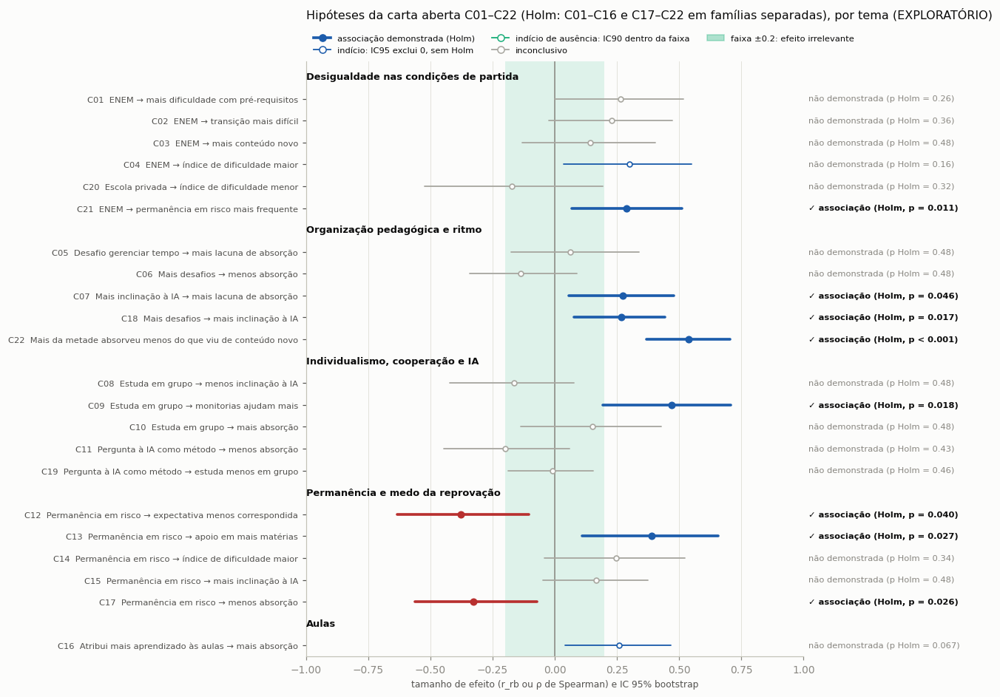

In [30]:
# --- Hipóteses da carta (C01–C16) ---
df["turma_ord"] = df["q03_turma"].cat.codes.where(df["q03_turma"].cat.codes >= 0).astype(float)
LINHAS_CARTA = {**LINHAS_MAPA, "Permanência em risco": ("binario", "g_risco", 1.0)}
C, C2 = "carta", "carta-2"
HIPOTESES_CARTA = [
    # Desigualdade nas condições de partida
    {"id": "C01", "x": "Ingresso: ENEM (vs Medalhas)", "y": "q14_prereq", "sinal": "+", "familia": C, "texto": "ENEM → mais dificuldade com pré-requisitos"},
    {"id": "C02", "x": "Ingresso: ENEM (vs Medalhas)", "y": "q12_transicao", "sinal": "+", "familia": C, "texto": "ENEM → transição mais difícil"},
    {"id": "C03", "x": "Ingresso: ENEM (vs Medalhas)", "y": "q25_novo", "sinal": "+", "familia": C, "texto": "ENEM → mais conteúdo novo"},
    {"id": "C04", "x": "Ingresso: ENEM (vs Medalhas)", "y": "indice_dif", "sinal": "+", "familia": C, "texto": "ENEM → índice de dificuldade maior"},
    # Organização pedagógica e ritmo
    {"id": "C05", "x": "Desafio: Gerenciar tempo", "y": "b_lacuna", "sinal": "+", "familia": C, "texto": "Desafio gerenciar tempo → mais lacuna de absorção"},
    {"id": "C06", "x": "n_desafios", "y": "q25_absorveu", "sinal": "-", "familia": C, "texto": "Mais desafios → menos absorção"},
    {"id": "C07", "x": "q18_ia_ord", "y": "b_lacuna", "sinal": "+", "familia": C, "texto": "Mais inclinação à IA → mais lacuna de absorção"},
    # Individualismo, cooperação e IA
    {"id": "C08", "x": "Método: Grupos de estudos", "y": "q18_ia_ord", "sinal": "-", "familia": C, "texto": "Estuda em grupo → menos inclinação à IA"},
    {"id": "C09", "x": "Método: Grupos de estudos", "y": "q25_monitoria", "sinal": "+", "familia": C, "texto": "Estuda em grupo → monitorias ajudam mais"},
    {"id": "C10", "x": "Método: Grupos de estudos", "y": "q25_absorveu", "sinal": "+", "familia": C, "texto": "Estuda em grupo → mais absorção"},
    {"id": "C11", "x": "Método: Perguntar a uma IA", "y": "q25_absorveu", "sinal": "-", "familia": C, "texto": "Pergunta à IA como método → menos absorção"},
    # Permanência e medo da reprovação
    {"id": "C12", "x": "Permanência em risco", "y": "q13_expectativa", "sinal": "-", "familia": C, "texto": "Permanência em risco → expectativa menos correspondida"},
    {"id": "C13", "x": "Permanência em risco", "y": "q15_apoio_ord", "sinal": "+", "familia": C, "texto": "Permanência em risco → apoio em mais matérias"},
    {"id": "C14", "x": "Permanência em risco", "y": "indice_dif", "sinal": "+", "familia": C, "texto": "Permanência em risco → índice de dificuldade maior"},
    {"id": "C15", "x": "Permanência em risco", "y": "q18_ia_ord", "sinal": "+", "familia": C, "texto": "Permanência em risco → mais inclinação à IA"},
    # Aulas
    {"id": "C16", "x": "q17_aulas", "y": "q25_absorveu", "sinal": "+", "familia": C, "texto": "Atribui mais aprendizado às aulas → mais absorção"},
    # Segunda rodada (15/11/2026, depois de 05g–05i): temas da carta ainda não cobertos. Família própria.
    {"id": "C17", "x": "Permanência em risco", "y": "q25_absorveu", "sinal": "-", "familia": C2, "texto": "Permanência em risco → menos absorção"},
    {"id": "C18", "x": "n_desafios", "y": "q18_ia_ord", "sinal": "+", "familia": C2, "texto": "Mais desafios → mais inclinação à IA"},
    {"id": "C19", "x": "Método: Perguntar a uma IA", "y": "q24_grupos", "sinal": "-", "familia": C2, "y_binario": True,
     "texto": "Pergunta à IA como método → estuda menos em grupo"},
    {"id": "C20", "x": "Estudou em escola privada", "y": "indice_dif", "sinal": "-", "familia": C2, "texto": "Escola privada → índice de dificuldade menor"},
    {"id": "C21", "x": "Ingresso: ENEM (vs Medalhas)", "y": "g_risco", "sinal": "+", "familia": C2, "y_binario": True,
     "texto": "ENEM → permanência em risco mais frequente"},
]


def testar_carta(d):
    """C01–C21 por testar_hipoteses; C19/C21 (desfecho 0/1) mascaradas se alguma célula < N_MIN_CELULA;
    C22 = teste binomial de uma amostra (lacuna de absorção em mais da metade). Holm por família."""
    from scipy.stats import binomtest
    t = utils.testar_hipoteses(d, HIPOTESES_CARTA, LINHAS_CARTA, N_MIN_GRUPO, DELTA_EQUIV, B=B_BOOT)
    for h in HIPOTESES_CARTA:
        if h.get("y_binario") and pd.notna(t.loc[h["id"], "p"]):
            xv, _ = utils._vetor_x(d, h["x"], LINHAS_CARTA)
            if utils.tem_celula_pequena(pd.crosstab(xv, d[h["y"]]), N_MIN_CELULA):
                t.loc[h["id"], ["efeito", "ic95_inf", "ic95_sup", "p"]] = np.nan
                t.loc[h["id"], "teste"] = "mascarado (célula < N_MIN_CELULA)"
    lac = d["b_lacuna"].dropna().values
    reg = {"família": C2, "hipótese": "Mais da metade absorveu menos do que viu de conteúdo novo", "sinal": "+",
           "medida": "2p − 1", "n_grupo": len(lac), "n_resto": np.nan, "teste": "não testado (n < N_MIN_GRUPO)"}
    if len(lac) >= N_MIN_GRUPO:
        k = int(lac.sum())
        bs = 2 * np.random.default_rng(0).binomial(len(lac), k / len(lac), B_BOOT) / len(lac) - 1
        reg.update(efeito=2 * k / len(lac) - 1, ic95_inf=np.percentile(bs, 2.5), ic95_sup=np.percentile(bs, 97.5),
                   p=binomtest(k, len(lac), 0.5, alternative="greater").pvalue,
                   teste="binomial unilateral (H0: 50% com lacuna)")
    t.loc["C22"] = pd.Series(reg)
    for fam in t["família"].unique():
        m = t["família"] == fam
        t.loc[m, "p_holm"] = utils.holm(t.loc[m, "p"]).values
    return t



# Todas as respostas juntas (estudo exploratório)
tab_carta = resultado(testar_carta(df))
exibir_hip(tab_carta, f"Hipóteses da carta C01–C22 — todas as respostas (N = {N}); Holm por família", ROTULO)
TEMAS_CARTA = {"Desigualdade nas condições de partida": ["C01", "C02", "C03", "C04", "C20", "C21"],
               "Organização pedagógica e ritmo": ["C05", "C06", "C07", "C18", "C22"],
               "Individualismo, cooperação e IA": ["C08", "C09", "C10", "C11", "C19"],
               "Permanência e medo da reprovação": ["C12", "C13", "C14", "C15", "C17"], "Aulas": ["C16"]}
GRUPO_CARTA = {i: tema for tema, ids in TEMAS_CARTA.items() for i in ids}
_ic_c = utils.ic_hipoteses({"": tab_carta}, GRUPO_CARTA, ALPHA)
_ordem_c = {i: k for k, i in enumerate(i for ids in TEMAS_CARTA.values() for i in ids)}
_ic_c = _ic_c.assign(_o=_ic_c["rotulo"].str[:3].map(_ordem_c)).sort_values("_o", kind="stable").drop(columns="_o")
utils.grafico_ic(_ic_c, DELTA_EQUIV, list(TEMAS_CARTA), ordenar=False,
                 arquivo=f"{PASTA_IC}/02_hipoteses_carta_C01-C22.png",
                 titulo=f"Hipóteses da carta aberta C01–C22 (Holm: C01–C16 e C17–C22 em famílias separadas), por tema ({ROTULO})")
plt.show()
utils.suprimir(tab_carta[COLS_HIP].copy(), N_MIN_CELULA, ["n_grupo", "n_resto"]).round(4).to_csv("tabelas/exploratorio/05i_hipoteses_carta.csv")

**272 pares testados** de 325 — EXPLORATÓRIO

,classe,nível,pares
0,inconclusivo,,173
1,negativa,indicio,9
2,não testado,,53
3,positiva,holm,8
4,positiva,indicio,48
5,sem_associacao,indicio,34


**Pares com associação (Holm) ou indício, do mais forte ao mais fraco** — `EXPLORATÓRIO`

,rot_x,rot_y,n,efeito,ic95_inf,ic95_sup,p,p_holm,classe,nível,status
0,Q16 Aulas,Q24 Monitorias,95,0.700,0.556,0.810,0.000,0.000,positiva,holm,testado
1,Q13 Pré-requisitos,Q14 Matérias c/ apoio,95,0.608,0.448,0.742,0.000,0.000,positiva,holm,testado
2,Q11 Transição,Q13 Pré-requisitos,95,0.506,0.318,0.667,0.000,0.000,positiva,holm,testado
3,Q11 Transição,Q14 Matérias c/ apoio,95,0.433,0.236,0.608,0.000,0.003,positiva,holm,testado
4,Q17 Inclinação à IA,Método: perguntar à IA,95,0.408,0.206,0.593,0.000,0.011,positiva,holm,testado
...,...,...,...,...,...,...,...,...,...,...,...
60,Q16 Aulas,Q14 Matérias c/ apoio,95,0.214,0.009,0.410,0.037,1.000,positiva,indicio,testado
61,Q12 Expectativa,Desafio: tarefas de casa,95,-0.214,-0.404,-0.014,0.037,1.000,negativa,indicio,testado
62,Nº de desafios,Turma (2024 → 2026),95,0.209,0.016,0.393,0.043,1.000,positiva,indicio,testado
63,Q24 Monitorias,Desafio: tarefas de casa,95,0.207,0.007,0.389,0.044,1.000,positiva,indicio,testado


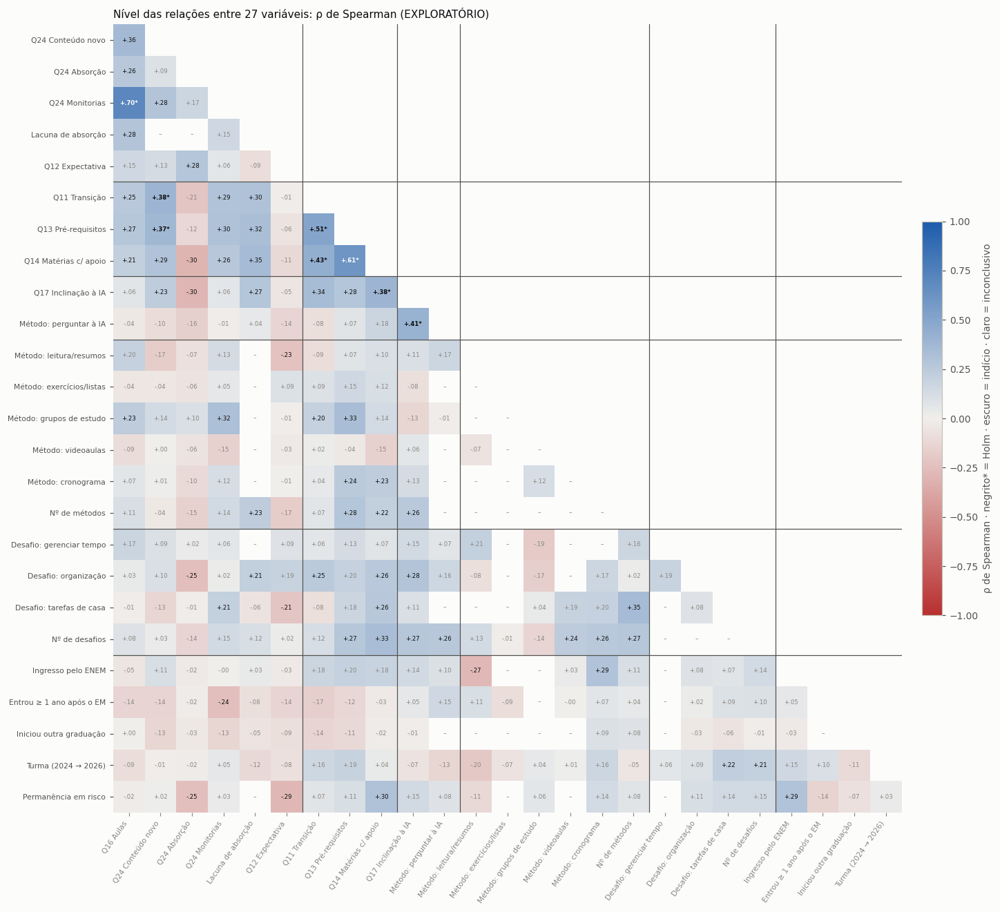

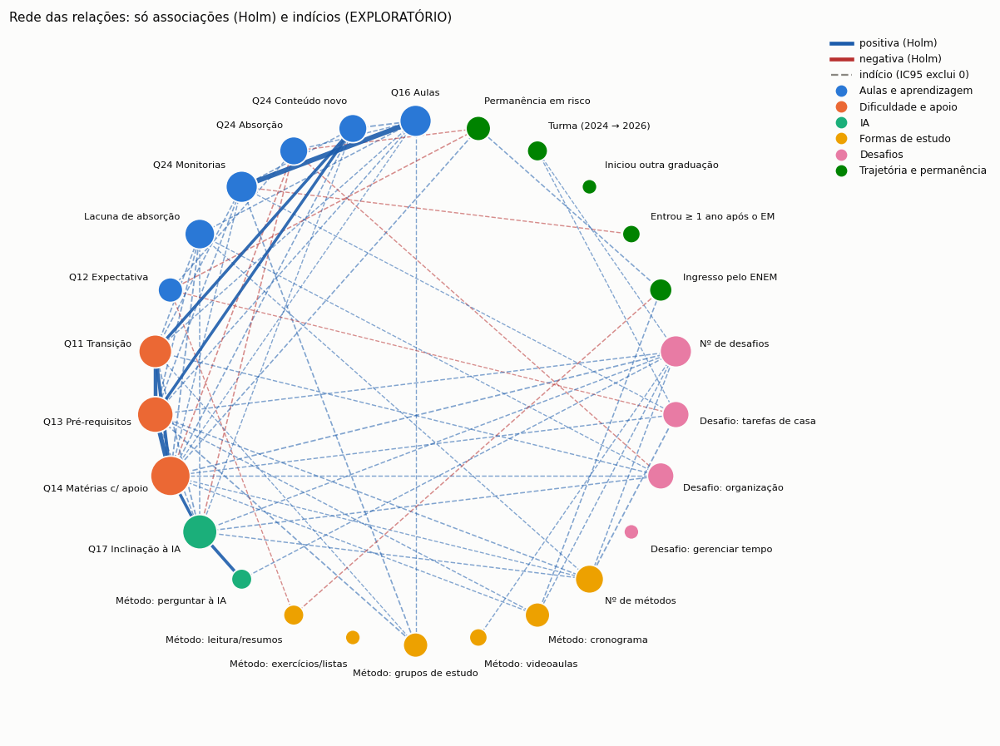

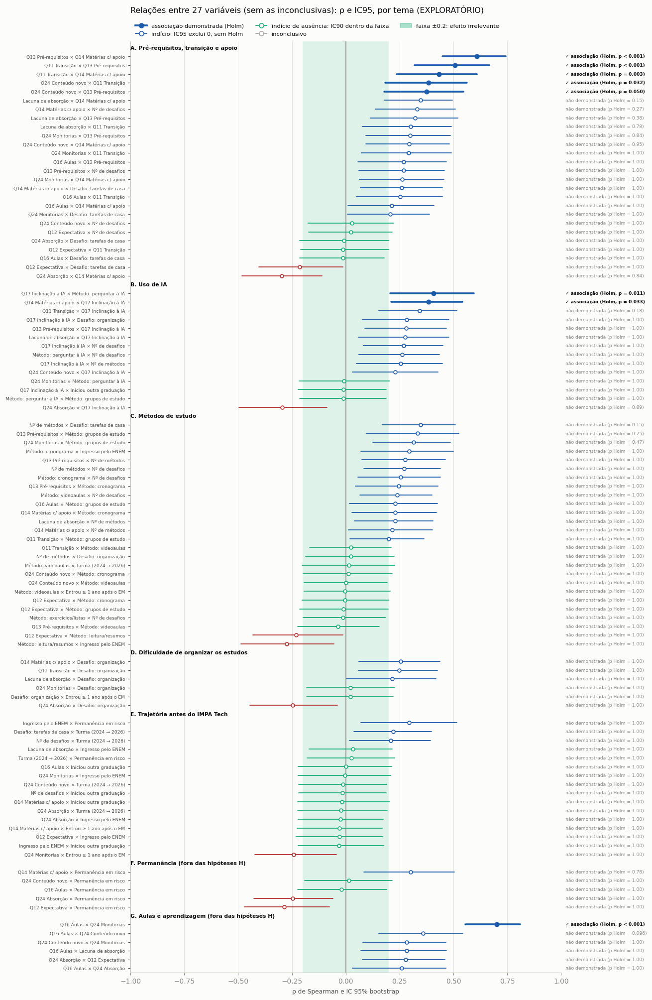

In [31]:
# --- Nível das relações: matriz e rede (27 variáveis, ρ de Spearman) ---
TEMAS_05I = {
    "Aulas e aprendizagem": {"q17_aulas": "Q16 Aulas", "q25_novo": "Q24 Conteúdo novo", "q25_absorveu": "Q24 Absorção",
                             "q25_monitoria": "Q24 Monitorias", "b_lacuna": "Lacuna de absorção",
                             "q13_expectativa": "Q12 Expectativa"},
    "Dificuldade e apoio": {"q12_transicao": "Q11 Transição", "q14_prereq": "Q13 Pré-requisitos",
                            "q15_apoio_ord": "Q14 Matérias c/ apoio"},
    "IA": {"q18_ia_ord": "Q17 Inclinação à IA", "q24_perguntar_ia": "Método: perguntar à IA"},
    "Formas de estudo": {"q24_leitura": "Método: leitura/resumos", "q24_pratica": "Método: exercícios/listas",
                         "q24_grupos": "Método: grupos de estudo", "q24_videoaulas": "Método: videoaulas",
                         "q24_cronograma": "Método: cronograma", "n_metodos": "Nº de métodos"},
    "Desafios": {"q19_tempo": "Desafio: gerenciar tempo", "q19_organizacao": "Desafio: organização",
                 "q19_tarefas": "Desafio: tarefas de casa", "n_desafios": "Nº de desafios"},
    "Trajetória e permanência": {"b_enem": "Ingresso pelo ENEM", "b_apos1": "Entrou ≥ 1 ano após o EM",
                                 "b_outra_grad": "Iniciou outra graduação", "turma_ord": "Turma (2024 → 2026)",
                                 "g_risco": "Permanência em risco"},
}
VAR_05I = {c: r for grupo in TEMAS_05I.values() for c, r in grupo.items()}
TEMA_DE = {c: tema for tema, grupo in TEMAS_05I.items() for c in grupo}
BIN_05I = {c for c in VAR_05I if c.startswith(("q19", "q24", "b_", "g_"))}
DERIVADOS = ([("b_lacuna", "q25_novo"), ("b_lacuna", "q25_absorveu")]
             + [("n_metodos", c) for c in VAR_05I if c.startswith("q24")]
             + [("n_desafios", c) for c in VAR_05I if c.startswith("q19")])

t_rel = utils.matriz_associacoes(df, VAR_05I, BIN_05I, N_MIN_GRUPO, N_MIN_CELULA, DERIVADOS, DELTA_EQUIV, B=B_BOOT)
resumo_rel = t_rel.groupby(["classe", "nível"]).size().rename("pares").reset_index()
display(Markdown(f"**{(t_rel.status == 'testado').sum()} pares testados** de {len(t_rel)} — {ROTULO}"))
display(resumo_rel)
COLS_REL = ["rot_x", "rot_y", "n", "efeito", "ic95_inf", "ic95_sup", "p", "p_holm", "classe", "nível", "status"]
t_rel[COLS_REL].round(4).to_csv("tabelas/exploratorio/05i_relacoes.csv", index=False)
fortes = t_rel[t_rel["classe"].isin(["positiva", "negativa"])].assign(a=lambda d: d.efeito.abs()).sort_values("a", ascending=False)
mostrar_teste(fortes[COLS_REL].round(3).reset_index(drop=True), "Pares com associação (Holm) ou indício, do mais forte ao mais fraco")

ORDEM_05I = list(VAR_05I)
utils.grafico_matriz(t_rel, ORDEM_05I, VAR_05I, TEMA_DE, arquivo="figuras/exploratorio/05i_matriz_relacoes.png",
                     titulo=f"Nível das relações entre 27 variáveis: ρ de Spearman ({ROTULO})")
plt.show()
utils.grafico_rede(t_rel, ORDEM_05I, VAR_05I, TEMA_DE, arquivo="figuras/exploratorio/05i_rede_relacoes.png",
                   titulo=f"Rede das relações: só associações (Holm) e indícios ({ROTULO})")
plt.show()
if len(fortes):
    nao_inc = t_rel[t_rel["classe"].isin(["positiva", "negativa", "sem_associacao"])]
    utils.grafico_ic(nao_inc.assign(rotulo=nao_inc["rot_x"] + " × " + nao_inc["rot_y"],
                                    grupo=[utils.GRUPOS_TEMA[utils.tema(a, b)] for a, b in zip(nao_inc["x"], nao_inc["y"])]),
                     DELTA_EQUIV, list(utils.GRUPOS_TEMA.values()), arquivo=f"{PASTA_IC}/08_relacoes_27_variaveis.png",
                     titulo=f"Relações entre 27 variáveis (sem as inconclusivas): ρ e IC95, por tema ({ROTULO})",
                     xlabel="ρ de Spearman e IC 95% bootstrap")
    plt.show()

#### Respostas abertas e a carta

*Substituído.* Uma versão anterior propunha usar os temas da carta como categorias iniciais para as sugestões. Isso **não** vale mais: as categorias da análise de conteúdo (seção 12) saem da leitura das próprias respostas, e não de um esquema pronto. A carta só entra no artigo, na discussão, se estiver nas Referências.

### Interpretação (05i)

*Perguntas-guia — a escrever pela aluna:*
- Quais temas da carta encontram apoio nos dados do questionário, e quais ficam sem dados que os sustentem ou contradigam?
- A relação entre estudar em grupo e usar IA vai na direção que a carta sugere ("IA como principal companhia de estudo")?
- Na rede, quais variáveis concentram mais ligações? Elas formam um núcleo (por exemplo, dificuldade–apoio–IA) que poderia organizar a discussão do artigo?
- As hipóteses C01–C16 que já aparecem na amostra total são novas, ou repetem resultados que já tinham sido vistos (H01–H52, 05f, 05h)?
- Como citar a carta no artigo: como fonte de hipóteses, como triangulação dos resultados, ou nos dois papéis?

### Interpretação (05)

*Perguntas-guia — a escrever pela aluna:*
- Quais diferenças sobrevivem à correção de Holm? Qual é o tamanho de efeito (r ou ε²) delas: pequeno, médio, grande?
- Onde há diferença grande nas medianas mas p alto? Isso pode ser falta de poder com o n atual?
- As comparações que não puderam ser testadas (n < N_MIN_GRUPO) devem virar hipóteses pré-registradas para a amostra final?
- Em 05a, quais hipóteses sobrevivem a Holm com todas as respostas? Lembrar que são exploratórias: foram formuladas olhando a prévia.
- Em 05f, alguma associação classificada como 'indício' tem uma explicação teórica plausível? Qual seria a direção esperada se ela virasse hipótese?
- Em 05e, os grupos com DP baixo são homogêneos de fato ou só estão presos no teto/chão da escala (mediana perto de 10 ou 0)?

## 06 · Correlações de Spearman

Escalas centrais + Q7 (só quem fez outra graduação) + Q14 e Q17 codificadas como ordinais (Q14: Não=0 … 4+=4; Q17: Não=0 … sempre=3). Casos completos por par; Holm sobre todos os pares.

**Spearman — família de 45 pares, Holm** — `EXPLORATÓRIO`

,x,y,n,rho,p,p_holm,sig
0,Q13 Dificuldade com pré-requisitos,Q14 Nº de matérias c/ apoio (ord.),95,0.608,0.0000,0.0000,*
1,Q11 Dificuldade da transição EM→superior,Q13 Dificuldade com pré-requisitos,95,0.506,0.0000,0.0000,*
2,Q16 Aprendizado atribuído às aulas,Q24 Quanto as monitorias ajudam,95,0.700,0.0000,0.0000,*
3,Q11 Dificuldade da transição EM→superior,Q14 Nº de matérias c/ apoio (ord.),95,0.433,0.0000,0.0005,*
4,Q14 Nº de matérias c/ apoio (ord.),Q17 Uso de IA (ord.),95,0.384,0.0001,0.0049,*
5,Q11 Dificuldade da transição EM→superior,Q24 Conteúdo novo visto,95,0.384,0.0001,0.0049,*
6,Q13 Dificuldade com pré-requisitos,Q24 Conteúdo novo visto,95,0.374,0.0002,0.0073,*
7,Q16 Aprendizado atribuído às aulas,Q24 Conteúdo novo visto,95,0.358,0.0004,0.0137,*
8,Q11 Dificuldade da transição EM→superior,Q17 Uso de IA (ord.),95,0.342,0.0007,0.0254,*
9,Q24 Quanto sente que absorveu,Q14 Nº de matérias c/ apoio (ord.),95,-0.299,0.0033,0.1185,


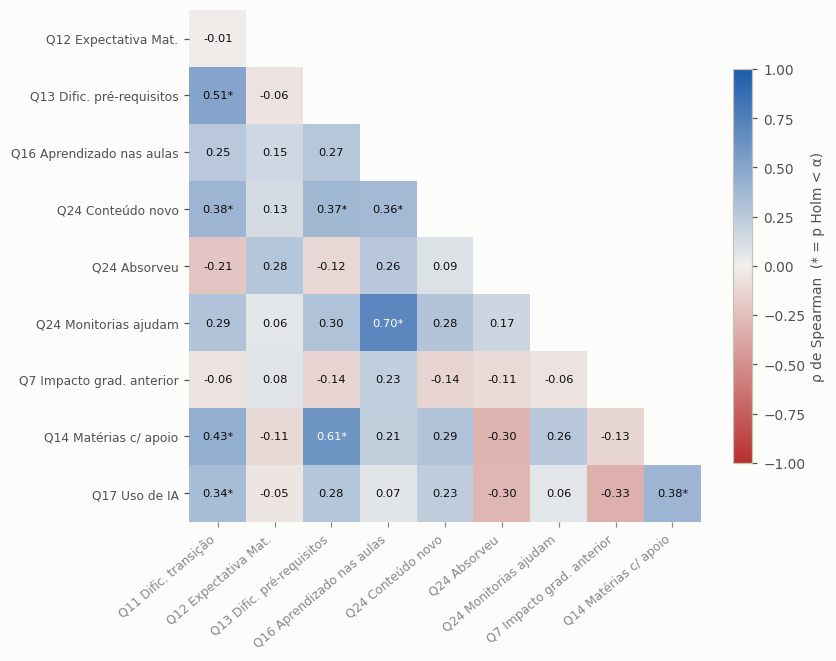

In [32]:
df["q15_apoio_ord"] = utils.codificar_ordinal(df["q15_apoio"])
df["q18_ia_ord"] = utils.codificar_ordinal(df["q18_ia"])
utils.ROTULOS.update({"q15_apoio_ord": "Q14 Nº de matérias c/ apoio (ord.)", "q18_ia_ord": "Q17 Uso de IA (ord.)"})
VARS_CORR = utils.ESCALAS_CENTRAIS + ["q08_impacto_grad", "q15_apoio_ord", "q18_ia_ord"]
tab_sp = utils.spearman_matriz(df, VARS_CORR, ALPHA)
tab_sp_exib = tab_sp.assign(x=tab_sp.x.map(utils.ROTULOS), y=tab_sp.y.map(utils.ROTULOS))
mostrar_teste(tab_sp_exib.sort_values("p").reset_index(drop=True),
              f"Spearman — família de {len(tab_sp)} pares, Holm")
tab_sp_exib.to_csv("tabelas/exploratorio/06_spearman.csv", index=False)
utils.grafico_spearman(tab_sp, VARS_CORR, arquivo="figuras/exploratorio/06_spearman.png"); plt.show()

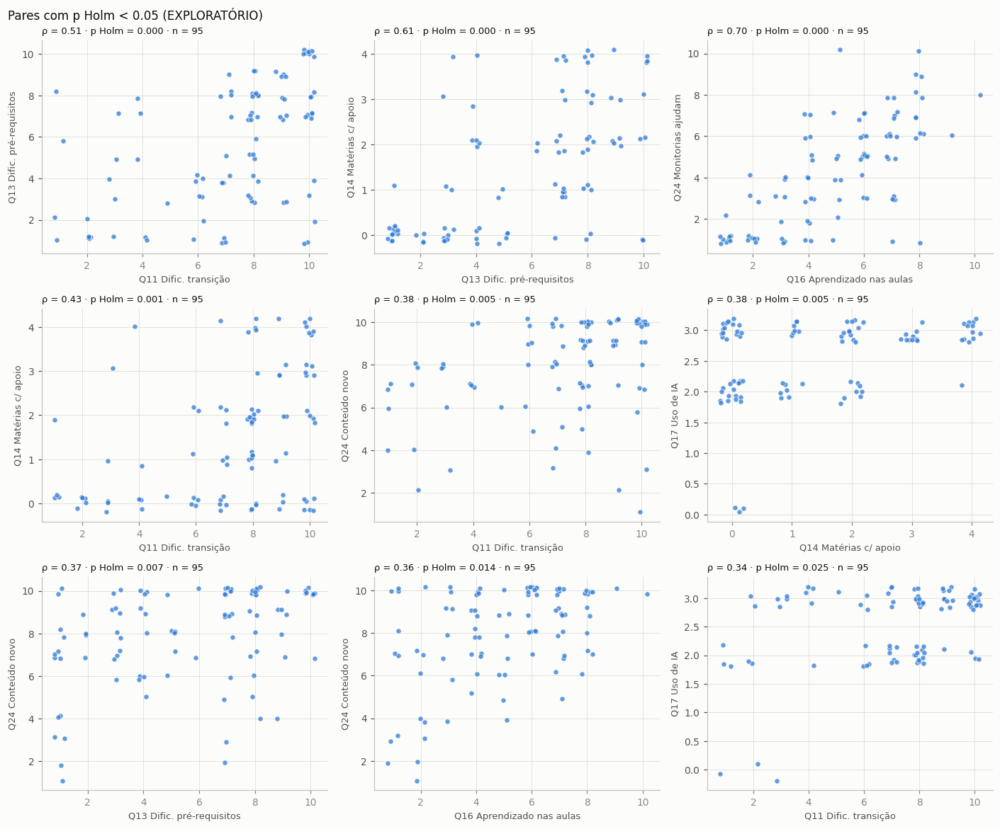

In [33]:
# Dispersão dos pares que sobrevivem ao Holm (jitter: as escalas são inteiras)
sig_sp = tab_sp[tab_sp["p_holm"] < ALPHA].sort_values("p_holm")
pares_sig = [(r.x, r.y, r.rho, r.p_holm) for r in sig_sp.itertuples()]
if pares_sig:
    utils.grafico_pares(df, pares_sig, arquivo="figuras/exploratorio/06_pares_significativos.png",
                        titulo=f"Pares com p Holm < {ALPHA} ({ROTULO})")
    plt.show()
else:
    print("Nenhum par significativo após Holm.")

### Interpretação (06)

*Perguntas-guia — a escrever pela aluna:*
- Quais pares têm correlação moderada/forte (|ρ| ≥ 0,3) e sobrevivem ao Holm?
- A dificuldade com pré-requisitos (Q13) se relaciona com quanto o aluno sente que absorve (Q24)?
- O uso de IA (Q17) se associa a alguma escala? Lembre que correlação não indica direção causal.
- As correlações com Q7 usam um n bem menor — com que cautela interpretá-las?

## 07 · Análise de texto (Q18 'Outro', Q21 sugestões, Q23 'Outro')

Respostas 'não'/'sim' não contam como texto. Nomes de pessoas são trocados por `[professor]`/`[pessoa]` antes de qualquer exibição (heurística de nomes próprios + lista manual opcional em `raw/nomes_anonimizar.txt`, um nome por linha — **conferir sempre** o arquivo `qualitativa/07_textos.csv`). Lemas: spaCy `pt_core_news_sm`, só VERB e NOUN, sem stopwords. **Com menos de 30 textos, os resultados desta seção (frequência de lemas, matriz termo × texto, rede de coocorrência) são exploratórios e não entram no artigo.** A análise das sugestões que entra no artigo é a **análise de conteúdo categorial** da seção 12.

**Privacidade:** nenhuma célula desta seção exibe texto de resposta nem `id_resposta`. Os textos anonimizados, e a matriz termo × texto ficam em `qualitativa/`, fora do git. Aqui aparecem só contagens e lemas soltos.

In [34]:
import spacy
nlp = spacy.load("pt_core_news_sm")
ARQ_NOMES = "raw/nomes_anonimizar.txt"
nomes_extra = []
if os.path.exists(ARQ_NOMES):
    nomes_extra = [l.strip() for l in open(ARQ_NOMES, encoding="utf-8") if l.strip()]

PASTA_QUALI = "qualitativa"   # tudo que tem texto literal ou id_resposta fica aqui (fora do git)
os.makedirs(PASTA_QUALI, exist_ok=True)

textos = utils.textos_longos(df)
textos["texto"], n_subst = utils.anonimizar_textos(textos["texto"], nlp, nomes_extra)
N_TEXTOS = len(textos)
_por_q = {q: (n if n >= N_MIN_CELULA else f"<{N_MIN_CELULA}") for q, n in textos["pergunta"].value_counts().items()}
print(f"{N_TEXTOS} textos ({_por_q}); {n_subst} nome(s) substituído(s).")
if N_TEXTOS < 30:
    display(Markdown(f"**EXPLORATÓRIO — apenas {N_TEXTOS} textos (< 30).** Frequências e clusters abaixo "
                     "servem para orientar a codificação manual; **não** interpretar os clusters como achado."))
textos.to_csv(f"{PASTA_QUALI}/07_textos.csv", index=False, encoding="utf-8-sig")
print(f"Textos anonimizados gravados em {PASTA_QUALI}/07_textos.csv (fora do git): conferir as substituições de nomes lá.")

31 textos ({'q22_sugestoes': 18, 'q19_outro_txt': 9, 'q24_outro_txt': '<5'}); 1 nome(s) substituído(s).
Textos anonimizados gravados em qualitativa/07_textos.csv (fora do git): conferir as substituições de nomes lá.


**Lemas mais frequentes — geral (top 15)**

,aluno,professor,curso,prova,achar,pessoa,conteúdo,coisa,reprovar,passar,aprender,conseguir,vida,matéria,ajudar
freq,18,12,9,8,7,7,6,5,5,5,5,5,4,4,4


*q19_outro_txt* (9 textos)

,colocar,velocidade,felicidade,ouvir,conteúdo,quantidade,acompanhar,densidade,praia,pisar,andar,música,sentir,nota,cabeça
freq,2,2,1,1,1,1,1,1,1,1,1,1,1,1,1


*q22_sugestoes* (18 textos)

,aluno,professor,curso,achar,pessoa,prova,reprovar,conteúdo,passar,coisa,ajudar,matéria,vida,instituição,dificuldade
freq,17,12,9,7,7,6,5,5,5,4,4,4,4,4,4


*q24_outro_txt* (4 textos)

,conseguir,amparar,anotar,consigo,fiz,aprender,passo,coisa,lembrar,forçar,colega,discussão,prova,filtrar,resumir
freq,3,1,1,1,1,1,1,1,1,1,1,1,1,1,1


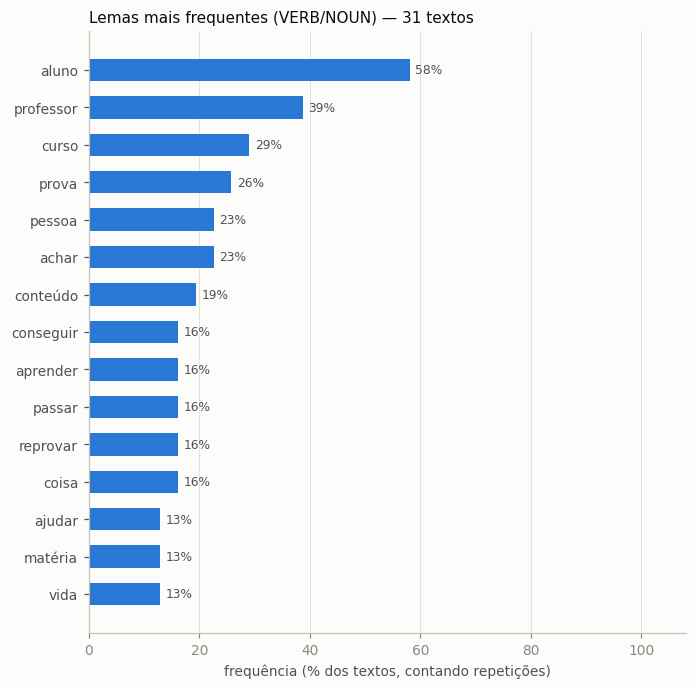

In [35]:
from collections import Counter
textos["lemas"] = utils.lematizar(textos["texto"].tolist(), nlp)
TOP = 15
geral = pd.Series(Counter(l for ls in textos["lemas"] for l in ls)).sort_values(ascending=False)
display(Markdown(f"**Lemas mais frequentes — geral (top {TOP})**")); display(geral.head(TOP).to_frame("freq").T)
for q, sub in textos.groupby("pergunta"):
    f = pd.Series(Counter(l for ls in sub["lemas"] for l in ls)).sort_values(ascending=False)
    display(Markdown(f"*{q}* ({len(sub)} textos)")); display(f.head(TOP).to_frame("freq").T)
geral.to_csv("tabelas/exploratorio/07_freq_lemas.csv", header=["freq"])
utils.grafico_barras(100 * geral.head(TOP) / N_TEXTOS, arquivo="figuras/exploratorio/07_lemas.png",
                     titulo=f"Lemas mais frequentes (VERB/NOUN) — {N_TEXTOS} textos",
                     xlabel="frequência (% dos textos, contando repetições)"); plt.show()

In [36]:
# Matriz termo × texto (contagens)
matriz = pd.DataFrame([Counter(ls) for ls in textos["lemas"]],
                      index=textos["id_resposta"] + "·" + textos["pergunta"].str[:3]).fillna(0).astype(int).T
matriz = matriz.loc[matriz.sum(axis=1).sort_values(ascending=False).index]
print(f"Matriz termo × texto: {matriz.shape[0]} lemas × {matriz.shape[1]} textos; "
      f"densidade {100 * (matriz > 0).values.mean():.1f}%")
# Só os lemas e em quantos textos aparecem; a matriz com os ids fica em qualitativa/ (fora do git)
display((matriz > 0).sum(axis=1).head(TOP).to_frame("nº de textos").T)
matriz.to_csv(f"{PASTA_QUALI}/07_matriz_termo_texto.csv")

Matriz termo × texto: 251 lemas × 31 textos; densidade 4.7%


,aluno,professor,curso,prova,achar,pessoa,conteúdo,coisa,reprovar,passar,aprender,conseguir,vida,matéria,ajudar
nº de textos,13,9,7,6,4,4,4,3,2,3,4,4,2,3,3


Grafo de co-ocorrência: 61 lemas, 767 arestas; 4 comunidades (Louvain)
  C1: aluno, prova, conteúdo, nota, lista, avaliação, faculdade, semestre, obrigar, exercício, disciplina, livro, tarefa, velocidade, quantidade, questão, diminuir, perder
  C2: aprender, conseguir, achar, coisa, excelência, matéria, saber, existir, utilizar, levar, fazer, dar, falar, nivelamento, estrutura, pressão, ensino, base
  C3: professor, pessoa, ouvir, ajudar, dificuldade, tornar, passar, colega, melhorar, vida, conhecimento, maneira, reprovar
  C4: curso, ritmo, ficar, instituição, estudar, ajustar, reprovação, dúvida, aprendizado, ideia, manter, monitoria


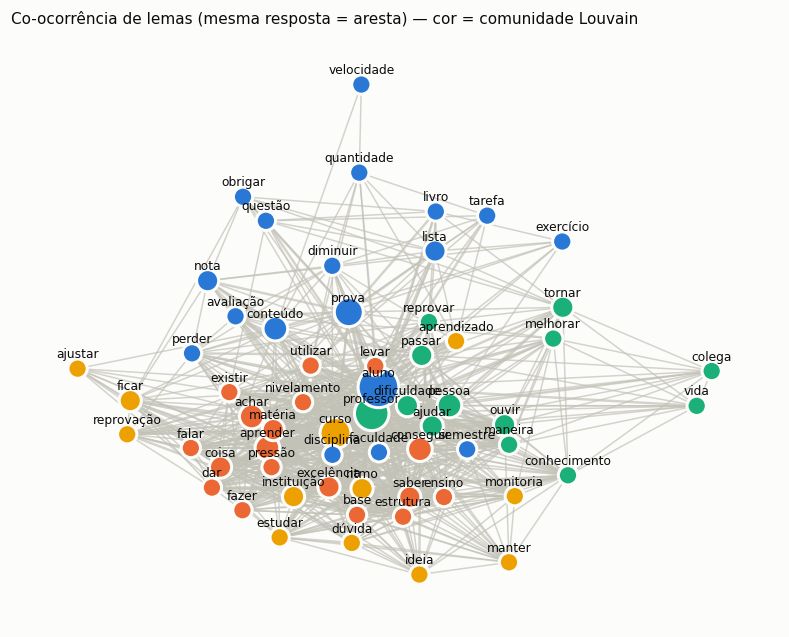

In [37]:
import networkx as nx
FREQ_MIN = 2   # lema precisa aparecer em >= FREQ_MIN respostas para entrar no grafo
G, comunidades = utils.grafo_coocorrencia(textos["lemas"], freq_min=FREQ_MIN, seed=0)
print(f"Grafo de co-ocorrência: {G.number_of_nodes()} lemas, {G.number_of_edges()} arestas; "
      f"{len(comunidades)} comunidades (Louvain)")
for i, c in enumerate(comunidades, 1):
    print(f"  C{i}: {', '.join(sorted(c, key=lambda n: -G.nodes[n]['freq']))}")
if G.number_of_nodes():
    cores_cat = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
    cor_no = {n: (cores_cat[i] if i < len(cores_cat) else utils.MUDO) for i, c in enumerate(comunidades) for n in c}
    pos = nx.spring_layout(G, seed=0, weight="weight", k=0.9)
    fig, ax = plt.subplots(figsize=(9, 7))
    larg = [0.4 + 0.6 * G[u][v]["weight"] for u, v in G.edges]
    nx.draw_networkx_edges(G, pos, ax=ax, width=larg, edge_color="#c3c2b7", alpha=0.7)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=[cor_no[n] for n in G.nodes],
                           node_size=[60 + 50 * G.nodes[n]["freq"] for n in G.nodes],
                           edgecolors="#fcfcfb", linewidths=2)
    nx.draw_networkx_labels(G, {n: (x, y + 0.045) for n, (x, y) in pos.items()}, ax=ax, font_size=8,
                            font_color=utils.TINTA)
    ax.set_title(f"Co-ocorrência de lemas (mesma resposta = aresta) — cor = comunidade Louvain"
                 f"{' · EXPLORATÓRIO' if N_TEXTOS < 30 else ''}", loc="left", fontsize=10)
    ax.axis("off"); fig.savefig("figuras/exploratorio/07_grafo_coocorrencia.png"); plt.show()

### Codificação

A codificação das sugestões foi para a **seção 12** (análise de conteúdo categorial, dois codificadores, consenso). O antigo `qualitativa/codigos.csv` não é mais usado pelo notebook; o arquivo não foi apagado.

*Sentimento por léxico (LeIA): não usado — não é necessário para a análise principal e, com tão poucos textos, acrescentaria pouco.*

### Interpretação (07)

*Perguntas-guia — a escrever pela aluna (só exploração; não entra no artigo):*
- Os lemas mais frequentes ajudam a ler as respostas antes de definir as categorias da seção 12, ou só repetem palavras do enunciado?
- Os textos estão concentrados em poucas respostas longas? O que isso diz sobre generalizar?

## 08 · Neurodivergência — com trava

Dado sensível; a pergunta entrou no meio da coleta, então só entra quem respondeu. **Nunca** é cruzada com turma, idade, ingresso ou escola. Por decisão do grupo (briefing de 15/11/2026), a flag `ANALISAR_NEURODIVERGENCIA = False` mantém a trava fechada com qualquer n: nada além de "X de Y" é exibido. Com a flag ligada, ainda vale a trava de `min(n_sim, n_não) < N_MIN_GRUPO`.

In [38]:
nd = df[df["q23_neurodiv"].notna()].copy()
nd["g_nd"] = np.where(nd["q23_neurodiv"].str.lower() == "sim", "Neurodivergente", "Não neurodivergente")
N_Q23 = len(nd)
N_ND_SIM = int((nd["g_nd"] == "Neurodivergente").sum())
N_ND_NAO = N_Q23 - N_ND_SIM
print(f"Respondentes da pergunta de neurodivergência: {N_Q23} de {N}")
print(f"{N_ND_SIM} de {N_Q23} se declararam neurodivergentes.")
if not ANALISAR_NEURODIVERGENCIA:
    display(Markdown("🔒 **Trava ativa (`ANALISAR_NEURODIVERGENCIA = False`):** pelo briefing, a neurodivergência não é "
                     "analisada nem cruzada com nenhuma variável, com qualquer n. Só se informa X de Y."))
elif min(N_ND_SIM, N_ND_NAO) < N_MIN_GRUPO:
    display(Markdown(f"🔒 **Trava ativa:** algum grupo tem n < `N_MIN_GRUPO` = {N_MIN_GRUPO}. "
                     "Nenhum teste e nenhum cruzamento são exibidos."))
else:
    t_nd, _ = utils.comparar_grupos(nd, "g_nd", utils.ESCALAS_CENTRAIS, N_MIN_GRUPO, ALPHA)
    mostrar_teste(t_nd, f"Neurodivergência × escalas centrais — família de {len(utils.ESCALAS_CENTRAIS)} testes, Holm")
    t_nd.to_csv("tabelas/exploratorio/08_neurodivergencia.csv")

Respondentes da pergunta de neurodivergência: 54 de 95
10 de 54 se declararam neurodivergentes.


🔒 **Trava ativa (`ANALISAR_NEURODIVERGENCIA = False`):** pelo briefing, a neurodivergência não é analisada nem cruzada com nenhuma variável, com qualquer n. Só se informa X de Y.

> **Nota de interpretação (obrigatória):** uma diferença (ou ausência de diferença) entre alunos neurodivergentes e não neurodivergentes nas escalas **não avalia** a política de acolhimento da instituição. O questionário não mede acesso, uso ou qualidade de acolhimento; grupos podem diferir por muitos outros motivos, e o grupo neurodivergente é autodeclarado e provavelmente subnotificado.

### Interpretação (08)

*Perguntas-guia — a escrever pela aluna:*
- O número de respondentes da pergunta de neurodivergência permite alguma conclusão? O que mudaria com a amostra final?
- Que perguntas seriam necessárias para, de fato, avaliar a política de acolhimento?

## 09 · Poder estatístico (pergunta de neurodivergência)

`TTestIndPower` (teste t para 2 grupos independentes; o Mann-Whitney tem eficiência ≈ 0,95 em relação a ele), bilateral, α = `ALPHA`. Cenários de adesão final sobre `N_POPULACAO`, descontando quem respondeu antes de a pergunta de neurodivergência existir e supondo a mesma proporção de neurodivergentes observada até agora.

In [39]:
from statsmodels.stats.power import TTestIndPower
pw = TTestIndPower()
DS = [0.3, 0.5, 0.8]
N_SEM_Q23 = int(df["q23_neurodiv"].isna().sum())     # responderam antes de a pergunta de neurodivergência existir
prop_nd = N_ND_SIM / N_Q23 if N_Q23 else np.nan
print(f"Responderam sem ver a pergunta de neurodivergência: {N_SEM_Q23}; proporção de neurodivergentes observada: {prop_nd:.1%}")

def poder(n1, n2, d):
    if n1 < 2 or n2 < 2:
        return np.nan
    return pw.power(effect_size=d, nobs1=n1, ratio=n2 / n1, alpha=ALPHA)

cenarios = [("Atual", N_ND_SIM, N_ND_NAO)]
for adesao in (0.3, 0.5, 0.8):
    n_q23 = max(round(adesao * N_POPULACAO) - N_SEM_Q23, 0)
    n1 = round(n_q23 * prop_nd)
    cenarios.append((f"Adesão {adesao:.0%} ({round(adesao * N_POPULACAO)} resp.)", n1, n_q23 - n1))
tab_pw = pd.DataFrame([{"cenário": c, "n neurodiv.": n1, "n não neurodiv.": n2,
                        **{f"poder d={d}": poder(n1, n2, d) for d in DS}} for c, n1, n2 in cenarios]).set_index("cenário")
display(tab_pw.round(3))
nec = pd.DataFrame({f"d={d}": {
    "n por grupo (grupos iguais)": int(np.ceil(pw.solve_power(effect_size=d, power=0.8, alpha=ALPHA, ratio=1))),
    f"n neurodiv. (razão observada 1:{(1 - prop_nd) / prop_nd:.1f})":
        int(np.ceil(pw.solve_power(effect_size=d, power=0.8, alpha=ALPHA, ratio=(1 - prop_nd) / prop_nd)))
    if 0 < prop_nd < 1 else np.nan} for d in DS})
display(Markdown("**n necessário para poder de 80%**")); display(nec)
tab_pw.to_csv("tabelas/exploratorio/09_poder.csv")

Responderam sem ver a pergunta de neurodivergência: 41; proporção de neurodivergentes observada: 18.5%


,n neurodiv.,n não neurodiv.,poder d=0.3,poder d=0.5,poder d=0.8
cenário,,,,,
Atual,10,44,0.134,0.288,0.611
Adesão 30% (60 resp.),4,15,0.080,0.134,0.269
Adesão 50% (100 resp.),11,48,0.143,0.313,0.653
Adesão 80% (160 resp.),22,97,0.243,0.556,0.919


**n necessário para poder de 80%**

,d=0.3,d=0.5,d=0.8
n por grupo (grupos iguais),176,64,26
n neurodiv. (razão observada 1:4.4),108,39,16


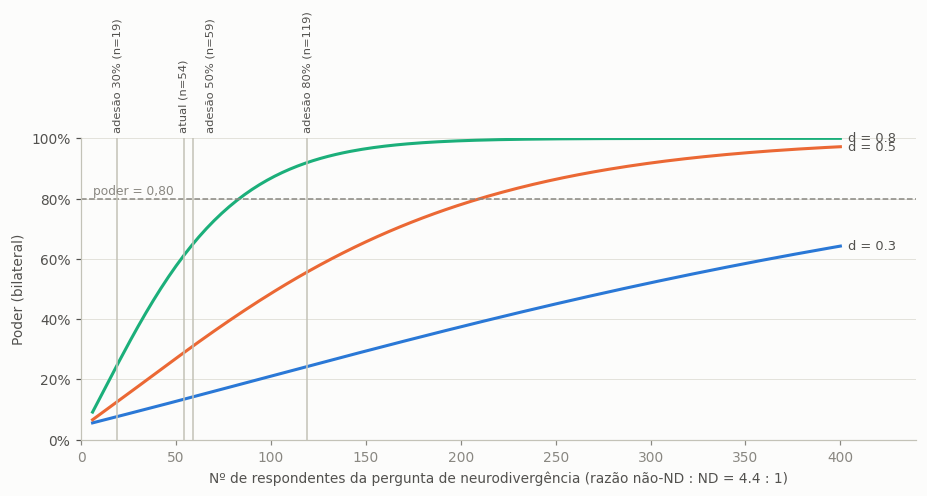

In [40]:
if 0 < prop_nd < 1:
    cen_graf = [("atual", N_Q23)] + [(f"adesão {a:.0%}", max(round(a * N_POPULACAO) - N_SEM_Q23, 0))
                                    for a in (0.3, 0.5, 0.8)]
    utils.grafico_poder(DS, (1 - prop_nd) / prop_nd, ALPHA, cen_graf,
                        n_max=max(400, 2 * N_POPULACAO), arquivo="figuras/exploratorio/09_poder.png")
    plt.show()
else:
    print("Sem respondentes nos dois grupos da pergunta de neurodivergência: curva de poder não calculada.")

### Interpretação (09)

*Perguntas-guia — a escrever pela aluna:*
- Com o n atual, que tamanho de efeito seria detectável? Isso é realista?
- Mesmo no melhor cenário de adesão, o estudo teria poder para d = 0,3? E para d = 0,5?
- O que deve ser dito no texto sobre a ausência de teste para a pergunta de neurodivergência?

## 10 · Tabela-síntese para RESULTADOS

**Amostra:** 95 respostas válidas (de 117 registros). Modo: `final`.

**Escalas**

,n,Md [Q1–Q3],média (DP)
variável,,,
Q7 Impacto da graduação anterior (1–5),26,4 [2.25–4.75],3.5 (1.4)
Q11 Dificuldade da transição EM→superior,95,8 [6–9],7.2 (2.6)
Q12 Expectativa com a Matemática correspondida,95,8 [6–8.5],7.2 (2.1)
Q13 Dificuldade com pré-requisitos,95,7 [3–8],5.6 (3.0)
Q16 Aprendizado atribuído às aulas,95,5 [3–7],5.0 (2.3)
Q24 Conteúdo novo visto,95,9 [7–10],7.9 (2.2)
Q24 Quanto sente que absorveu,95,6 [5–7],5.8 (1.9)
Q24 Quanto as monitorias ajudam,95,4 [2–6],4.2 (2.5)


Testes realizados: 168 | não testados por n < N_MIN_GRUPO: 0 | significativos após Holm: 20


**Resultados significativos após Holm (α = 0.05)** — `EXPLORATÓRIO`

,família,teste,comparação,p,p_holm,efeito,medida
0,Spearman,Spearman,Q16 Aprendizado atribuído às aulas × Q24 Quanto as monitorias ajudam,0.0000,0.0000,0.7000,ρ
1,Spearman,Spearman,Q11 Dificuldade da transição EM→superior × Q13 Dificuldade com pré-requisitos,0.0000,0.0000,0.5060,ρ
2,Spearman,Spearman,Q13 Dificuldade com pré-requisitos × Q14 Nº de matérias c/ apoio (ord.),0.0000,0.0000,0.6080,ρ
3,Hipóteses (principal),Spearman unilateral,H01: Mais dificuldade com pré-requisitos → apoio em mais matérias,0.0000,0.0000,0.6078,ρ
4,Hipóteses (principal),Spearman unilateral,H02: Transição mais difícil → apoio em mais matérias,0.0000,0.0002,0.4325,ρ
5,Spearman,Spearman,Q11 Dificuldade da transição EM→superior × Q14 Nº de matérias c/ apoio (ord.),0.0000,0.0005,0.4330,ρ
6,Hipóteses (principal),Mann-Whitney U unilateral,H24: Método perguntar à IA → usa IA com mais frequência,0.0000,0.0010,0.4423,r_rb
7,Hipóteses (principal),Spearman unilateral,H03: Mais dificuldade com pré-requisitos → mais conteúdo novo,0.0001,0.0023,0.3741,ρ
8,Hipóteses (principal),Mann-Whitney U unilateral,H12: Sempre usa IA → apoio em mais matérias,0.0002,0.0036,0.4251,r_rb
9,Spearman,Spearman,Q11 Dificuldade da transição EM→superior × Q24 Conteúdo novo visto,0.0001,0.0049,0.3840,ρ


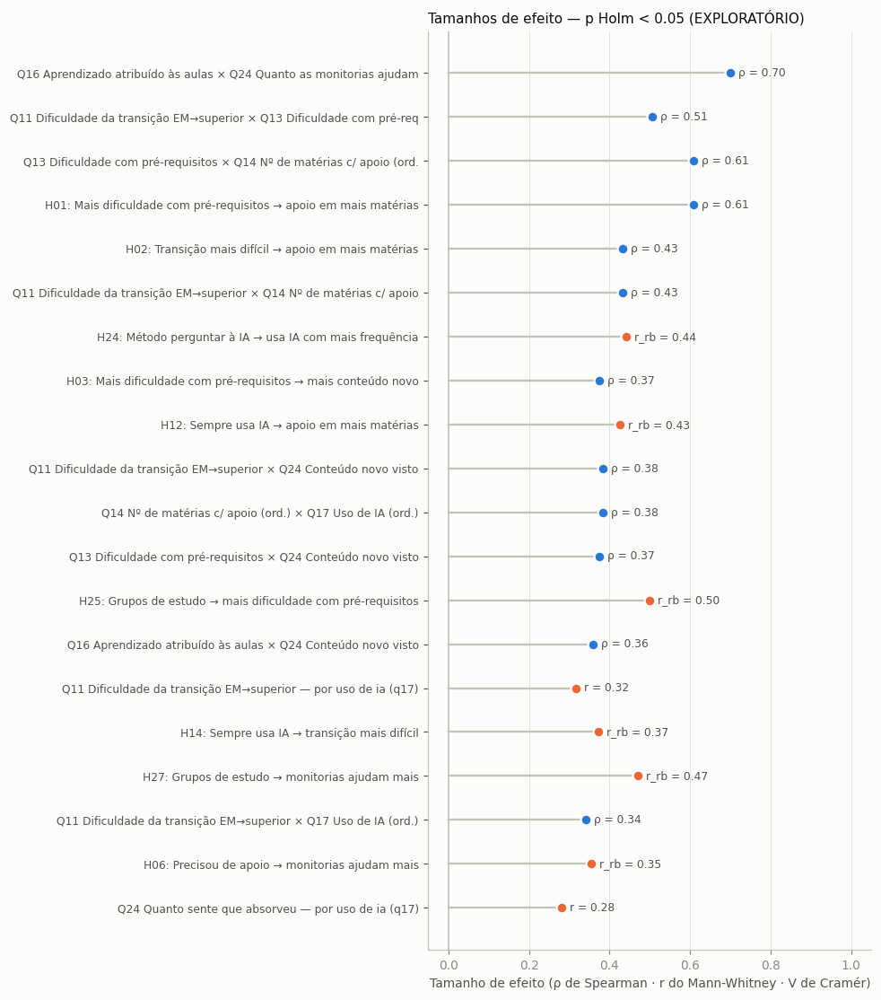

Tabelas salvas em tabelas/exploratorio/, figuras em figuras/exploratorio/.


In [41]:
display(Markdown(f"**Amostra:** {N} respostas válidas (de {len(dados)} registros). Modo: `{MODO}`."))
sint_desc = desc[["n", "mediana", "IQR", "média", "DP"]].copy()
sint_desc["Md [Q1–Q3]"] = [f"{r.mediana:g} [{q1:g}–{q3:g}]" for r, q1, q3 in
                           zip(sint_desc.itertuples(), desc["Q1"], desc["Q3"])]
sint_desc["média (DP)"] = [f"{m:.1f} ({s:.1f})" for m, s in zip(desc["média"], desc["DP"])]
display(Markdown("**Escalas**")); display(sint_desc[["n", "Md [Q1–Q3]", "média (DP)"]])

linhas = []
for nome, t in resultados_comp.items():
    for desf, r in t.iterrows():
        linhas.append({"família": f"Grupos: {nome}", "teste": r["teste"], "comparação": f"{desf} — por {nome.lower()}",
                       "p": r["p"], "p_holm": r["p_holm"], "efeito": r["efeito"], "medida": r["medida"]})
for par, r in tab_cat.iterrows():
    linhas.append({"família": "Categóricas", "teste": r["teste"], "comparação": par, "p": r["p"],
                   "p_holm": r["p_holm"], "efeito": r["V de Cramér"], "medida": "V"})
for r in tab_sp_exib.itertuples():
    linhas.append({"família": "Spearman", "teste": "Spearman", "comparação": f"{r.x} × {r.y}",
                   "p": r.p, "p_holm": r.p_holm, "efeito": r.rho, "medida": "ρ"})
for hid, r in tab_hip.iterrows():   # todas as respostas juntas (exploratório)
    linhas.append({"família": f"Hipóteses ({r['família']})", "teste": r["teste"],
                   "comparação": f"{hid}: {r['hipótese']}", "p": r["p"], "p_holm": r["p_holm"],
                   "efeito": r["efeito"], "medida": r["medida"] + (" · equivalência" if r["sinal"] == "0" else "")})
todos = pd.DataFrame(linhas)
testados = todos[todos["p"].notna()]
print(f"Testes realizados: {len(testados)} | não testados por n < N_MIN_GRUPO: {(todos['p'].isna()).sum()} | "
      f"significativos após Holm: {(testados['p_holm'] < ALPHA).sum()}")
sig = testados[testados["p_holm"] < ALPHA].sort_values("p_holm")
mostrar_teste(sig.round(4).reset_index(drop=True), "Resultados significativos após Holm (α = %.2f)" % ALPHA)
if not sig.empty:
    utils.grafico_efeitos(sig, arquivo="figuras/exploratorio/10_efeitos_significativos.png",
                          titulo=f"Tamanhos de efeito — p Holm < {ALPHA} ({ROTULO})")
    plt.show()
sint_desc.to_csv("tabelas/exploratorio/10_sintese_escalas.csv")
todos.to_csv("tabelas/exploratorio/10_todos_os_testes.csv", index=False)
print("Tabelas salvas em tabelas/exploratorio/, figuras em figuras/exploratorio/.")

### Interpretação (10)

*Perguntas-guia — a escrever pela aluna:*
- Quais 3–5 resultados você levaria para a seção de Resultados? Por que esses?
- Para cada um: qual é o tamanho de efeito, e ele é relevante na prática?
- Quais limitações (amostra parcial, autosseleção, poucos textos, pergunta de neurodivergência incompleta) precisam ser ditas junto?

## 11 · Resumo expandido — família de 29 associações

Esta seção segue o roteiro de análise do resumo expandido. Ela é **independente** das seções 05–10: tem critérios de inclusão próprios, uma família fixa de 29 associações e Holm sobre as 29. **Todas as análises são exploratórias.**

**Diferenças em relação ao restante do notebook:**
- **Inclusão:** o único critério é TCLE ≠ "não".
  - **Quem não respondeu à Q25** fica na amostra. Na prática, essas pessoas pararam no início e não têm respostas às escalas, então não entram nas associações (cada associação usa só os pares completos).
  - **Quem errou 77 + 33** também fica. Dessa pergunta distratora só se usa se a pessoa acertou ou errou.
  - **Múltipla escolha:** para quem não chegou à pergunta, fica faltante, e não conta como "não marcou".
  - **Percentuais:** são calculados sobre quem respondeu a cada pergunta.
- **Análise de sensibilidade:** repete tudo **excluindo** quem não respondeu à Q25 e quem errou 77 + 33, que eram os critérios do roteiro original.
- **Família:** foi escolhida pela ligação com o objetivo do trabalho, mas **depois** de a prévia ter sido examinada (seções 05–06). Várias associações dela já apareciam nesses resultados (por exemplo, pré-requisitos × apoio e transição × apoio). Por isso a família **não** conta como definida antes de ver os resultados nestes dados.
- **n mínimo para calcular:** usa `N_MIN_GRUPO` (regra do projeto: abaixo disso, só a descritiva). O roteiro original pedia 5. Para seguir o roteiro, troque `N_MIN_RESUMO` para `N_MIN_CELULA` na célula da família.
- **IA:** a Q17 é descrita como *inclinação ao uso de IA devido ao ritmo do curso*, não como frequência de uso.
- **Fora desta seção:** a pergunta de neurodivergência (só se informa o n de respondentes), as distratoras e as respostas abertas.

**Saídas:**
- `tabelas/artigo/11_tabela_descritiva.csv`
- `tabelas/artigo/11_tabela_associacoes.csv`
- `tabelas/artigo/11_sensibilidade.csv`
- `figuras/artigo/11_associacoes_ic.png`
- `relatorio_resumo_expandido.md`
- `raw/base_anonima.csv` (fora do git)

In [42]:
# Fluxo de inclusão do resumo (a partir de `dados`: já sem IP, Resume-Code, sorteio, Unnamed e distratoras)
B_RESUMO, SEMENTE_RESUMO = 10000, 42
r0 = dados
r1 = r0[r0["q01_consentimento"].str.lower() == "sim"].copy()   # só quem aceitou o TCLE (vazio não entra)

# Múltipla escolha: quem não chegou à pergunta fica faltante (não é "não marcou")
_depois_q19 = ["q21_terminar", "q25_novo", "q25_absorveu", "q25_monitoria", "q26_trancou"]
_depois_q24 = ["q25_novo", "q25_absorveu", "q25_monitoria", "q26_trancou"]
for q, depois in [("q19", _depois_q19), ("q24", _depois_q24)]:
    chegou = r1[depois].notna().any(axis=1) | (r1[utils.MULTIPLA[q]].sum(axis=1) > 0)
    r1[utils.MULTIPLA[q]] = r1[utils.MULTIPLA[q]].astype(float).where(chegou)

sem_q24 = r1["q26_trancou"].isna()
errou = r1["verif_atencao"] == 0
sem_escalas = r1[utils.ESCALAS_CENTRAIS].isna().all(axis=1)
fluxo_r = pd.DataFrame([
    ("Total de registros", len(r0), ""),
    ("Após remover quem não aceitou o TCLE", len(r1), len(r0) - len(r1)),
    ("  mantidos sem resposta à Q25 (sem escalas: não entram nas associações)", "", int(sem_q24.sum())),
    ("Com pelo menos uma escala respondida (n das associações)", int((~sem_escalas).sum()), ""),
], columns=["etapa", "n", "removidos / contagem"])
display(fluxo_r)
N_R = len(r1)
N_EFETIVO_R = int((~sem_escalas).sum())
print(f"Incluídos: {N_R}. Removidos por não aceitar o TCLE: {len(r0) - len(r1)}.")
print(f"  mantidos sem resposta à Q25: {int(sem_q24.sum())} "
      f"(sem nenhuma escala respondida: {int((sem_q24 & sem_escalas).sum())}; não entram nas associações)")
# Quem errou 77 + 33 é um grupo pequeno: o N da sensibilidade não é mostrado quando revelaria menos de N_MIN_CELULA pessoas
N_ERROU = int(errou.sum())
N_SENS_TXT = (f"N = {len(r_sens)}" if not 0 < N_ERROU < N_MIN_CELULA
              else f"exclui menos de {N_MIN_CELULA} participantes que responderam às escalas")
print(f"  mantidos que erraram 77 + 33: {N_ERROU if not 0 < N_ERROU < N_MIN_CELULA else f'<{N_MIN_CELULA}'}")
print(f"  com pelo menos uma escala respondida (entram nas associações): {N_EFETIVO_R}")
fluxo_r.to_csv("tabelas/artigo/11_fluxo_inclusao.csv", index=False)

# Sensibilidade: critérios do roteiro original (respondeu à Q25 e acertou 77 + 33)
r_sens = r1[~sem_q24 & (r1["verif_atencao"] == 1)]
print(f"Sensibilidade (excluindo sem Q25 e quem errou 77 + 33): {N_SENS_TXT}")

# Pergunta de neurodivergência: só o n de respondentes (não é analisada nesta seção)
N_ND_RESP_R = int(r1["q23_neurodiv"].notna().sum())
print(f"Pergunta de neurodivergência: respondida por {N_ND_RESP_R} de {N_R} (não analisada).")

# Base anonimizada (sem neurodivergência, data/hora, textos abertos e a flag de atenção); fica em raw/ (fora do git)
_tirar = ["q23_neurodiv", "data_hora", "verif_atencao"] + utils.TEXTOS
r1.drop(columns=[c for c in _tirar if c in r1]).to_csv("raw/base_anonima.csv", index=False, encoding="utf-8-sig")
print("Base anonimizada salva em raw/base_anonima.csv (fora do git).")

d_r = utils.codificar_resumo(r1)           # amostra principal
d_r_sens = utils.codificar_resumo(r_sens)  # sensibilidade

,etapa,n,removidos / contagem
0,Total de registros,117,
1,Após remover quem não aceitou o TCLE,114,3
2,mantidos sem resposta à Q25 (sem escalas: não entram nas associações),,17
3,Com pelo menos uma escala respondida (n das associações),97,


Incluídos: 114. Removidos por não aceitar o TCLE: 3.
  mantidos sem resposta à Q25: 17 (sem nenhuma escala respondida: 17; não entram nas associações)
  mantidos que erraram 77 + 33: <5
  com pelo menos uma escala respondida (entram nas associações): 97
Sensibilidade (excluindo sem Q25 e quem errou 77 + 33): exclui menos de 5 participantes que responderam às escalas
Pergunta de neurodivergência: respondida por 56 de 114 (não analisada).
Base anonimizada salva em raw/base_anonima.csv (fora do git).


In [43]:
# Estatística descritiva (nenhuma categoria com menos de N_MIN_CELULA pessoas)
desc_r = []
for v in ["TRANSICAO", "EXPECTATIVA", "PREREQ", "AULAS", "CONTEUDO_NOVO", "ABSORCAO", "MONITORIAS", "APOIO", "IA"]:
    x = d_r[v].dropna()
    desc_r.append({"tipo": "escala/ordinal", "variável": utils.NOMES_RESUMO[v], "categoria": "", "n": len(x),
                   "%": np.nan, "mediana": x.median(), "IQR": f"{x.quantile(.25):g}–{x.quantile(.75):g}"})
CATEG_R = {"Turma": r1["q03_turma"],
           "Idade": r1["q02_idade"].astype(object).replace({"23 - 25 anos": "23 anos ou mais", "26+": "23 anos ou mais"}), "Forma de ingresso": r1["q09_forma_ingresso"],
           "Momento de ingresso após o EM": r1["q04_ingresso_tempo"], "Outra graduação": r1["q06_outra_grad"].astype(object).replace({"Sim, incompleta": "Sim (completa ou incompleta)",
                                                                   "Sim, completa": "Sim (completa ou incompleta)"}),
           "Pretende terminar o curso": r1["q21_terminar"]}
for nome in ["LEITURA", "GRUPOS", "CRONOGRAMA", "PERGUNTAR_IA", "DES_TEMPO", "DES_ORGANIZACAO", "DES_TAREFAS"]:
    CATEG_R[utils.NOMES_RESUMO[nome]] = d_r[nome].map({1.0: "marcou", 0.0: "não marcou"})
for nome, s in CATEG_R.items():
    cont = s.astype(object).value_counts()
    n_validos = int(s.notna().sum())
    cont, nota = utils._agrupar_pequenas(cont, N_MIN_CELULA)
    for cat, n in cont.items():
        desc_r.append({"tipo": "categórica", "variável": nome, "categoria": str(cat), "n": int(n),
                       "%": round(100 * n / n_validos, 1), "n válido": n_validos, "mediana": np.nan, "IQR": nota})
# Q25 (trancou/reprovou): só o total de quem relatou qualquer reprovação ou trancamento
N_Q24_R = int(r1["q26_trancou"].notna().sum())
N_TRANC_R = int((r1["q26_trancou"].notna() & (r1["q26_trancou"] != "Não")).sum())
desc_r.append({"tipo": "categórica", "variável": "Relatou reprovação ou trancamento (qualquer)", "categoria": "sim",
               "n": N_TRANC_R if N_TRANC_R >= N_MIN_CELULA else f"<{N_MIN_CELULA}",
               "%": round(100 * N_TRANC_R / N_Q24_R, 1) if N_TRANC_R >= N_MIN_CELULA else np.nan, "n válido": N_Q24_R,
               "mediana": np.nan, "IQR": "número insuficiente para comparações; não comparado"})
tab_desc_r = pd.DataFrame(desc_r)
display(tab_desc_r)
tab_desc_r.to_csv("tabelas/artigo/11_tabela_descritiva.csv", index=False)

,tipo,variável,categoria,n,%,mediana,IQR,n válido
0,escala/ordinal,Dificuldade da transição EM→superior,,97,NaN,8.0,6–9,NaN
1,escala/ordinal,Expectativa com a Matemática correspondida,,97,NaN,8.0,6–9,NaN
2,escala/ordinal,Dificuldade com pré-requisitos,,97,NaN,6.0,3–8,NaN
3,escala/ordinal,Aprendizado atribuído às aulas,,97,NaN,5.0,3–7,NaN
4,escala/ordinal,Conteúdo novo visto,,97,NaN,9.0,7–10,NaN
5,escala/ordinal,Quanto sente que absorveu,,97,NaN,6.0,5–7,NaN
6,escala/ordinal,Quanto as monitorias ajudam,,97,NaN,4.0,2–6,NaN
7,escala/ordinal,Nº de disciplinas em que precisou de apoio,,97,NaN,1.0,0–2,NaN
8,escala/ordinal,Inclinação ao uso de IA devido ao ritmo do curso,,97,NaN,3.0,2–3,NaN
9,categórica,Turma,Turma 2026,48,44.4,NaN,,108.0


In [44]:
# Família principal: 29 associações, uma única família (Holm sobre as 29)
N_MIN_RESUMO = N_MIN_GRUPO   # roteiro original: N_MIN_CELULA (5)
FAMILIA_29, BLOCOS_R = utils.FAMILIA_29, utils.BLOCOS_R   # definidas em utils.py

assoc_r = utils.associacoes_familia(d_r, FAMILIA_29, N_MIN_RESUMO, DELTA_EQUIV, B=B_RESUMO, semente=SEMENTE_RESUMO, alpha=ALPHA)
assoc_r_sens = utils.associacoes_familia(d_r_sens, FAMILIA_29, N_MIN_RESUMO, DELTA_EQUIV, B=B_RESUMO,
                                         semente=SEMENTE_RESUMO, alpha=ALPHA)

COLS_R = ["id", "bloco", "x", "y", "medida", "n_1", "n_0", "mediana_1", "mediana_0", "efeito", "ic95_inf", "ic95_sup",
          "ic90_inf", "ic90_sup", "p", "p_holm", "p_tost", "p_tost_holm", "classificação"]
def tab_assoc(t):
    t = t.reindex(columns=COLS_R).copy()
    for g in ("1", "0"):   # privacidade: grupo com n < N_MIN_CELULA não mostra n nem mediana
        peq = t[f"n_{g}"].apply(lambda v: pd.notna(v) and 0 < v < N_MIN_CELULA)
        t[f"n_{g}"] = t[f"n_{g}"].astype(object)
        t.loc[peq, f"n_{g}"] = f"<{N_MIN_CELULA}"
        t.loc[peq, f"mediana_{g}"] = np.nan
    return t
mostrar_teste(tab_assoc(assoc_r).round(3), f"29 associações (incluídos = {N_R}; n por associação nas colunas n_1/n_0); Holm sobre a família", ROTULO)
display(assoc_r["classificação"].value_counts().to_frame("associações"))
tab_assoc(assoc_r).round(4).to_csv("tabelas/artigo/11_tabela_associacoes.csv", index=False)

# Controle interno: a prévia fica congelada; no modo final, lista o que mudou em relação a ela
ARQ_PREVIA_R = "tabelas/artigo/11_tabela_associacoes_previa.csv"
mud_r = None
if MODO == "previa":
    tab_assoc(assoc_r).round(4).to_csv(ARQ_PREVIA_R, index=False)
elif os.path.exists(ARQ_PREVIA_R):
    _prev = pd.read_csv(ARQ_PREVIA_R)[["id", "efeito", "classificação"]]
    mud_r = _prev.merge(tab_assoc(assoc_r)[["id", "efeito", "classificação"]], on="id", suffixes=(" (prévia)", " (final)"))
    mud_r["mudou?"] = np.where(mud_r["classificação (prévia)"] != mud_r["classificação (final)"], "MUDOU", "")
    mud_r.round(4).to_csv("tabelas/artigo/11_mudancas_previa_final.csv", index=False)
    display(Markdown(f"**Mudanças em relação à prévia** (controle interno): {(mud_r['mudou?'] == 'MUDOU').sum()} de 29 classificações."))
    display(mud_r.round(3))

**29 associações (incluídos = 114; n por associação nas colunas n_1/n_0); Holm sobre a família** — `EXPLORATÓRIO`

,id,bloco,x,y,medida,n_1,n_0,mediana_1,mediana_0,efeito,ic95_inf,ic95_sup,ic90_inf,ic90_sup,p,p_holm,p_tost,p_tost_holm,classificação
0,A1,A,AULAS,ABSORCAO,ρ,97,NaN,NaN,NaN,0.262,0.050,0.463,0.085,0.432,0.010,0.219,0.720,1.0,Indício de associação positiva
1,A2,A,CONTEUDO_NOVO,ABSORCAO,ρ,97,NaN,NaN,NaN,0.085,-0.143,0.323,-0.108,0.283,0.407,1.000,0.166,1.0,Inconclusivo
2,A3,A,MONITORIAS,ABSORCAO,ρ,97,NaN,NaN,NaN,0.186,-0.024,0.392,0.010,0.358,0.068,1.000,0.443,1.0,Inconclusivo
3,A4,A,PREREQ,CONTEUDO_NOVO,ρ,97,NaN,NaN,NaN,0.370,0.182,0.542,0.213,0.518,0.000,0.005,0.963,1.0,Associação positiva
4,A5,A,PREREQ,APOIO,ρ,97,NaN,NaN,NaN,0.611,0.455,0.741,0.482,0.724,0.000,0.000,1.000,1.0,Associação positiva
5,A6,A,TRANSICAO,APOIO,ρ,97,NaN,NaN,NaN,0.431,0.239,0.600,0.270,0.573,0.000,0.000,0.990,1.0,Associação positiva
6,A7,A,IA,ABSORCAO,ρ,97,NaN,NaN,NaN,-0.299,-0.488,-0.094,-0.462,-0.128,0.003,0.074,0.830,1.0,Indício de associação negativa
7,A8,A,IA,APOIO,ρ,97,NaN,NaN,NaN,0.395,0.224,0.552,0.252,0.529,0.000,0.002,0.986,1.0,Associação positiva
8,B1,B,PERMANENCIA,EXPECTATIVA,r_rb,83,14.0,8.0,6.5,0.365,0.027,0.666,0.080,0.624,0.027,0.603,0.843,1.0,Indício de associação positiva
9,B2,B,PERMANENCIA,ABSORCAO,r_rb,83,14.0,6.0,5.0,0.307,-0.007,0.610,0.044,0.566,0.063,1.000,0.754,1.0,Inconclusivo


,associações
classificação,
Inconclusivo,20
Indício de associação positiva,4
Associação positiva,4
Indício de associação negativa,1


**Mudanças em relação à prévia** (controle interno): 11 de 29 classificações.

,id,efeito (prévia),classificação (prévia),efeito (final),classificação (final),mudou?
0,A1,0.295,Indício de associação positiva,0.262,Indício de associação positiva,
1,A2,0.096,Inconclusivo,0.085,Inconclusivo,
2,A3,0.200,Inconclusivo,0.186,Inconclusivo,
3,A4,0.380,Associação positiva,0.370,Associação positiva,
4,A5,0.629,Associação positiva,0.611,Associação positiva,
5,A6,0.406,Associação positiva,0.431,Associação positiva,
6,A7,-0.330,Associação negativa,-0.299,Indício de associação negativa,MUDOU
7,A8,0.434,Associação positiva,0.395,Associação positiva,
8,B1,NaN,grupo insuficiente,0.365,Indício de associação positiva,MUDOU
9,B2,NaN,grupo insuficiente,0.307,Inconclusivo,MUDOU


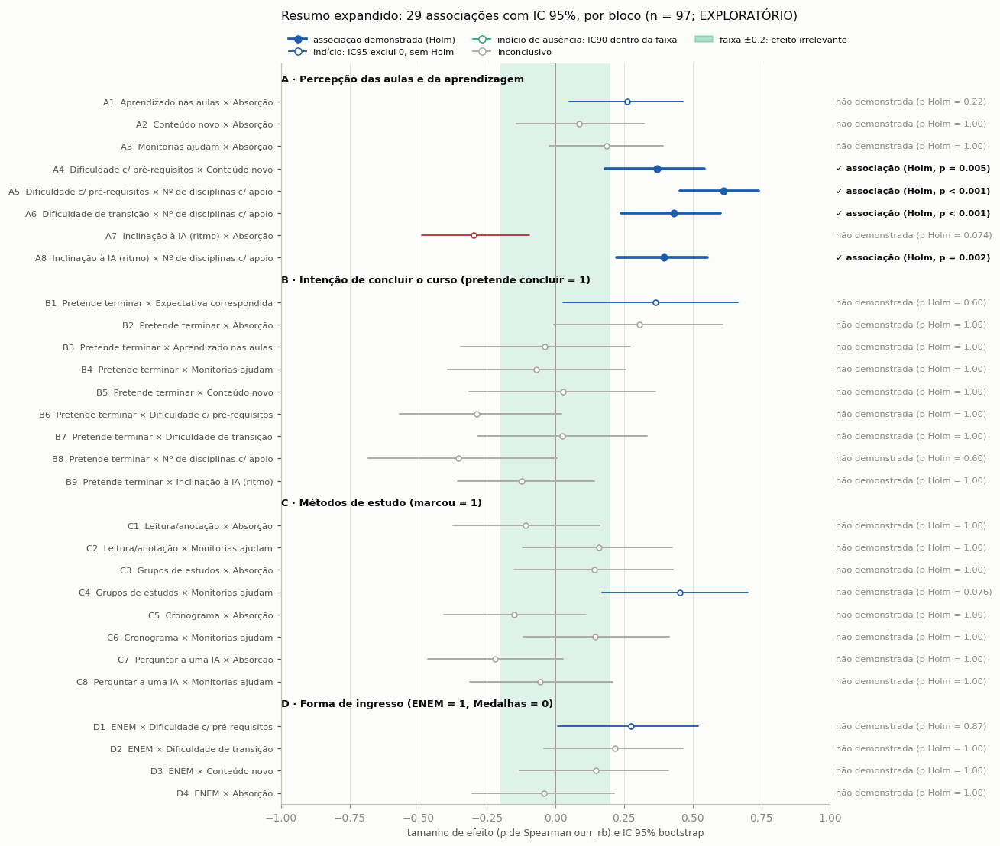

In [45]:
# Grupos = os blocos A–D do roteiro do resumo (mantém a ordem A1 … D4)
utils.grafico_ic(utils.ic_familia(assoc_r).assign(
                     grupo=assoc_r["bloco"].map(BLOCOS_R),
                     rotulo=[f"{r.id}  {utils.CURTOS_RESUMO.get(r.x, r.x)} × {utils.CURTOS_RESUMO.get(r.y, r.y)}"
                             for r in assoc_r.itertuples()]),
                 DELTA_EQUIV, list(BLOCOS_R.values()), ordenar=False, arquivo="figuras/artigo/11_associacoes_ic.png",
                 titulo=f"Resumo expandido: 29 associações com IC 95%, por bloco (n = {N_EFETIVO_R}; {ROTULO})",
                 xlabel="tamanho de efeito (ρ de Spearman ou r_rb) e IC 95% bootstrap")
plt.show()

In [46]:
# Análise de sensibilidade: mesma família, excluindo quem não respondeu à Q25 e quem errou 77 + 33
sens = assoc_r[["id", "efeito", "classificação"]].merge(
    assoc_r_sens[["id", "efeito", "classificação"]], on="id", suffixes=(" (principal)", " (sensibilidade)"))
sens["mudou?"] = np.where(sens["classificação (principal)"] != sens["classificação (sensibilidade)"], "MUDOU", "")
mostrar_teste(sens.round(3), f"Sensibilidade — principal (n = {N_EFETIVO_R}) × excluindo sem Q25 e erro em 77 + 33 ({N_SENS_TXT})", ROTULO)
print(f"Classificações que mudam na sensibilidade: {(sens['mudou?'] == 'MUDOU').sum()} de {len(sens)}.")
sens.round(4).to_csv("tabelas/artigo/11_sensibilidade.csv", index=False)

# Tabela 1 do artigo: associações que resistiram a Holm, já formatadas (vírgula decimal), com o resultado da sensibilidade
_v = lambda x: f"{x:.2f}".replace(".", ",").replace("-", "−")
_p = lambda p: "< 0,001" if p < 0.001 else f"{p:.3f}".replace(".", ",")
_cl_sens = dict(zip(assoc_r_sens["id"], assoc_r_sens["classificação"]))
_holm = assoc_r[assoc_r["classificação"].str.startswith("Associação")].sort_values("efeito", key=abs, ascending=False)
tab1_artigo = pd.DataFrame([{
    "id": r.id, "associação": f"{utils.NOMES_RESUMO[r.x]} × {utils.NOMES_RESUMO[r.y]}", "medida": r.medida,
    "efeito": _v(r.efeito), "IC 95%": f"{_v(r.ic95_inf)} a {_v(r.ic95_sup)}", "p (Holm)": _p(r.p_holm),
    "na sensibilidade": "mantém" if _cl_sens.get(r.id) == r.classificação else f"vira: {_cl_sens.get(r.id)}"}
    for r in _holm.itertuples()])
tab1_artigo.to_csv("tabelas/artigo/tabela1_associacoes_holm.csv", index=False, encoding="utf-8-sig")
mostrar_teste(tab1_artigo, "Tabela 1 do artigo — associações que resistiram a Holm", ROTULO)

**Sensibilidade — principal (n = 97) × excluindo sem Q25 e erro em 77 + 33 (exclui menos de 5 participantes que responderam às escalas)** — `EXPLORATÓRIO`

,id,efeito (principal),classificação (principal),efeito (sensibilidade),classificação (sensibilidade),mudou?
0,A1,0.262,Indício de associação positiva,0.243,Indício de associação positiva,
1,A2,0.085,Inconclusivo,0.091,Inconclusivo,
2,A3,0.186,Inconclusivo,0.162,Inconclusivo,
3,A4,0.370,Associação positiva,0.397,Associação positiva,
4,A5,0.611,Associação positiva,0.597,Associação positiva,
5,A6,0.431,Associação positiva,0.411,Associação positiva,
6,A7,-0.299,Indício de associação negativa,-0.286,Indício de associação negativa,
7,A8,0.395,Associação positiva,0.437,Associação positiva,
8,B1,0.365,Indício de associação positiva,0.329,Inconclusivo,MUDOU
9,B2,0.307,Inconclusivo,0.357,Indício de associação positiva,MUDOU


Classificações que mudam na sensibilidade: 5 de 29.


**Tabela 1 do artigo — associações que resistiram a Holm** — `EXPLORATÓRIO`

,id,associação,medida,efeito,IC 95%,p (Holm),na sensibilidade
0,A5,Dificuldade com pré-requisitos × Nº de disciplinas em que precisou de apoio,ρ,"0,61","0,45 a 0,74","< 0,001",mantém
1,A6,Dificuldade da transição EM→superior × Nº de disciplinas em que precisou de apoio,ρ,"0,43","0,24 a 0,60","< 0,001",mantém
2,A8,Inclinação ao uso de IA devido ao ritmo do curso × Nº de disciplinas em que precisou de apoio,ρ,"0,40","0,22 a 0,55","0,002",mantém
3,A4,Dificuldade com pré-requisitos × Conteúdo novo visto,ρ,"0,37","0,18 a 0,54","0,005",mantém


In [47]:
# Relatório curto (só resultados e limitações; interpretações ficam para a aluna, como hipóteses)
def v2(v, sinal=True):
    """Número com vírgula decimal."""
    return (f"{v:+.2f}" if sinal else f"{v:.3f}").replace(".", ",")

def fmt(r):
    n = f"n = {int(r.n_1)} pares" if r.medida == "ρ" else f"n = {int(r.n_1)} × {int(r.n_0)}"
    return (f"{r.id} — {utils.NOMES_RESUMO[r.x]} × {utils.NOMES_RESUMO[r.y]}: "
            f"{r.medida} = {v2(r.efeito)}, IC 95% [{v2(r.ic95_inf)}; {v2(r.ic95_sup)}], {n}, p Holm {"< 0,001" if r.p_holm < 0.001 else "= " + v2(r.p_holm, False)}")

def nfmt(v):
    return f"<{N_MIN_CELULA}" if 0 < v < N_MIN_CELULA else str(v)

L = ["# Resumo expandido — resultados exploratórios", "",
     f"Gerado pelo notebook `analise.ipynb` (seção 11), modo `{MODO}`. Todas as análises são exploratórias.", "",
     "## Fluxo de inclusão"]
L += [f"- Total de registros: {len(r0)}.",
      f"- Removidos por recusarem o TCLE: {len(r0) - N_R}. Incluídos: {N_R}.",
      f"- Mantidos sem resposta à Q25: {int(sem_q24.sum())}. Desses, {int((sem_q24 & sem_escalas).sum())} pararam no início, "
      "sem responder às escalas, e por isso não entram nas associações (cada associação usa os pares completos).",
      f"- Mantidos que erraram a verificação 77 + 33: {nfmt(int(errou.sum()))}.",
      f"- Com pelo menos uma escala respondida: {N_EFETIVO_R}."]
_dh = pd.to_datetime(r1["data_hora"], errors="coerce")
_n_nao_concl = int((d_r["PERMANENCIA"] == 0).sum())
L += [f"- Última resposta incluída: {_dh.max():%d/%m/%Y}." if _dh.notna().any() else "- Última resposta incluída: sem data.",
      f"- Bloco B: o grupo que não pretende concluir ou não tem certeza tem n = {nfmt(_n_nao_concl)}; "
      + ("as associações do bloco são calculadas." if _n_nao_concl >= N_MIN_RESUMO
         else f"abaixo de {N_MIN_RESUMO}, o bloco fica só com medianas descritivas.")]
if MODO == "final" and mud_r is not None:
    L.append(f"- Controle interno: {(mud_r['mudou?'] == 'MUDOU').sum()} de 29 classificações mudaram em relação à prévia "
             "(`tabelas/artigo/11_mudancas_previa_final.csv`).")
L += ["", "## Caracterização da amostra",
      f"- Incluídos = {N_R}. Os percentuais são calculados sobre quem respondeu a cada pergunta."]
for nome in ["Turma", "Idade", "Forma de ingresso", "Momento de ingresso após o EM", "Outra graduação"]:
    sub = tab_desc_r[tab_desc_r["variável"] == nome]
    L.append(f"- {nome}: " + "; ".join(f"{c} {n} ({p:.0f}%)" for c, n, p in zip(sub.categoria, sub.n, sub["%"])))
L.append(f"- Relataram qualquer reprovação ou trancamento: {nfmt(N_TRANC_R)} de {N_Q24_R} que responderam. O número é insuficiente para comparações.")
L.append(f"- A pergunta de neurodivergência foi respondida por {N_ND_RESP_R} pessoas e não é analisada aqui.")
_ia = r1["q18_ia"].value_counts()
L.append("- Inclinação ao uso de IA: na prática, a variável tem dois níveis — "
         f"\"Sim, sempre uso\" ({_ia.get('Sim, sempre uso', 0)}) e \"Sim, usei algumas vezes\" ({_ia.get('Sim, usei algumas vezes', 0)}); "
         f"\"Não\" e \"Sim, mas nunca usei\" somam {nfmt(int(_ia.get('Não', 0) + _ia.get('Sim, mas nunca usei', 0)))}. "
         "As associações com IA (A7, A8, B9) comparam, essencialmente, \"sempre uso\" com \"usei algumas vezes\".")
L += ["", "## Resultados por bloco",
      f"Holm aplicado sobre as {int(assoc_r['p'].notna().sum())} associações calculadas da família de 29. "
      "Primeiro as associações que sobrevivem a Holm, depois os indícios (IC 95% exclui zero, sem Holm). "
      "As demais estão em `tabelas/artigo/11_tabela_associacoes.csv`; a Tabela 1 do artigo (as que resistiram a Holm), "
      "já formatada, está em `tabelas/artigo/tabela1_associacoes_holm.csv`."]
for b, nome in BLOCOS_R.items():
    sub = assoc_r[assoc_r["bloco"] == b]
    L += ["", f"### {nome}"]
    fortes = sub[sub["classificação"].str.startswith("Associação")]
    indic = sub[sub["classificação"].str.startswith("Indício de associação")]
    aus = sub[sub["classificação"].isin(["Ausência confirmada", "Indício de ausência"])]
    insuf = sub[sub["classificação"] == "grupo insuficiente"]
    L += ["**Associações (Holm):**"] + ([f"- {fmt(r)}" for r in fortes.itertuples()] or ["- nenhuma"])
    L += ["**Indícios de associação:**"] + ([f"- {fmt(r)}" for r in indic.itertuples()] or ["- nenhum"])
    if len(aus):
        L += ["**Ausência (confirmada ou indício):**"] + [f"- {fmt(r)} — {r.classificação}" for r in aus.itertuples()]
    L.append(f"- Inconclusivas: {(sub['classificação'] == 'Inconclusivo').sum()} de {len(sub)}.")
    if len(insuf):
        r0_ = insuf.iloc[0]
        L.append(f"- **Não calculadas** ({len(insuf)}): o grupo menor tem n = {nfmt(int(min(r0_.n_1, r0_.n_0)))}, "
                 f"abaixo do mínimo de {N_MIN_RESUMO}. Só a descritiva:")
        for r in insuf.itertuples():
            if min(r.n_1, r.n_0) >= N_MIN_CELULA:
                L.append(f"  - {utils.NOMES_RESUMO[r.y]}: mediana {r.mediana_1:g} (x = 1, n = {int(r.n_1)}) × "
                         f"{r.mediana_0:g} (x = 0, n = {int(r.n_0)})".replace(".", ","))
n_mud = int((sens["mudou?"] == "MUDOU").sum())
L += ["", "## Análise de sensibilidade",
      f"Excluindo quem não respondeu à Q25 e quem errou 77 + 33 ({N_SENS_TXT}). Classificações que mudam: {n_mud} de 29."]
L += [f"- {r.id}: {r._3} → {r._5}" for r in sens[sens["mudou?"] == "MUDOU"].itertuples()]
L += ["", "## Limitações",
      "- Amostra de conveniência (adesão voluntária), sem garantia de representar todos os estudantes.",
      "- Quase nenhum ex-estudante: quem trancou ou saiu do curso está sub-representado.",
      "- A faixa etária (17–19 anos) não permite separar menores de 18 anos.",
      "- O instrumento não tem validação psicométrica; cada construto é medido por um único item.",
      "- Desenho transversal: as associações não indicam direção nem causa.",
      "- A família de 29 associações foi escolhida depois de a prévia ter sido examinada; nenhuma delas é confirmatória.",
      "- Quem errou a verificação de atenção (77 + 33) foi mantido; o resultado sem essas pessoas está na análise de sensibilidade.",
      "", "## Interpretações (hipóteses — a escrever pelos autores)",
      "_Usar linguagem de associação (\"está associado a\", \"relataram\"); nada de \"causa\", \"leva a\" ou \"para compensar\"._"]
relatorio = "\n".join(L)
open("relatorio_resumo_expandido.md", "w", encoding="utf-8").write(relatorio + "\n")
display(Markdown(relatorio))

# Resumo expandido — resultados exploratórios

Gerado pelo notebook `analise.ipynb` (seção 11), modo `final`. Todas as análises são exploratórias.

## Fluxo de inclusão
- Total de registros: 117.
- Removidos por recusarem o TCLE: 3. Incluídos: 114.
- Mantidos sem resposta à Q25: 17. Desses, 17 pararam no início, sem responder às escalas, e por isso não entram nas associações (cada associação usa os pares completos).
- Mantidos que erraram a verificação 77 + 33: <5.
- Com pelo menos uma escala respondida: 97.
- Última resposta incluída: 17/11/2026.
- Bloco B: o grupo que não pretende concluir ou não tem certeza tem n = 14; as associações do bloco são calculadas.
- Controle interno: 11 de 29 classificações mudaram em relação à prévia (`tabelas/artigo/11_mudancas_previa_final.csv`).

## Caracterização da amostra
- Incluídos = 114. Os percentuais são calculados sobre quem respondeu a cada pergunta.
- Turma: Turma 2026 48 (44%); Turma 2025 39 (36%); Turma 2024 21 (19%)
- Idade: 20 - 22 anos 51 (47%); 17 - 19 anos 44 (41%); 23 anos ou mais 13 (12%)
- Forma de ingresso: Medalhas 73 (75%); ENEM 24 (25%)
- Momento de ingresso após o EM: Imediatamente 69 (64%); Após 1 ano 18 (17%); Após 4 anos ou mais 11 (10%); Outras (agrupadas) 10 (9%)
- Outra graduação: Não 79 (73%); Sim (completa ou incompleta) 29 (27%)
- Relataram qualquer reprovação ou trancamento: 11 de 97 que responderam. O número é insuficiente para comparações.
- A pergunta de neurodivergência foi respondida por 56 pessoas e não é analisada aqui.
- Inclinação ao uso de IA: na prática, a variável tem dois níveis — "Sim, sempre uso" (60) e "Sim, usei algumas vezes" (34); "Não" e "Sim, mas nunca usei" somam <5. As associações com IA (A7, A8, B9) comparam, essencialmente, "sempre uso" com "usei algumas vezes".

## Resultados por bloco
Holm aplicado sobre as 29 associações calculadas da família de 29. Primeiro as associações que sobrevivem a Holm, depois os indícios (IC 95% exclui zero, sem Holm). As demais estão em `tabelas/artigo/11_tabela_associacoes.csv`; a Tabela 1 do artigo (as que resistiram a Holm), já formatada, está em `tabelas/artigo/tabela1_associacoes_holm.csv`.

### A · Percepção das aulas e da aprendizagem
**Associações (Holm):**
- A4 — Dificuldade com pré-requisitos × Conteúdo novo visto: ρ = +0,37, IC 95% [+0,18; +0,54], n = 97 pares, p Holm = 0,005
- A5 — Dificuldade com pré-requisitos × Nº de disciplinas em que precisou de apoio: ρ = +0,61, IC 95% [+0,45; +0,74], n = 97 pares, p Holm < 0,001
- A6 — Dificuldade da transição EM→superior × Nº de disciplinas em que precisou de apoio: ρ = +0,43, IC 95% [+0,24; +0,60], n = 97 pares, p Holm < 0,001
- A8 — Inclinação ao uso de IA devido ao ritmo do curso × Nº de disciplinas em que precisou de apoio: ρ = +0,40, IC 95% [+0,22; +0,55], n = 97 pares, p Holm = 0,002
**Indícios de associação:**
- A1 — Aprendizado atribuído às aulas × Quanto sente que absorveu: ρ = +0,26, IC 95% [+0,05; +0,46], n = 97 pares, p Holm = 0,219
- A7 — Inclinação ao uso de IA devido ao ritmo do curso × Quanto sente que absorveu: ρ = -0,30, IC 95% [-0,49; -0,09], n = 97 pares, p Holm = 0,074
- Inconclusivas: 2 de 8.

### B · Intenção de concluir o curso (pretende concluir = 1)
**Associações (Holm):**
- nenhuma
**Indícios de associação:**
- B1 — Pretende terminar o curso (Sim = 1) × Expectativa com a Matemática correspondida: r_rb = +0,36, IC 95% [+0,03; +0,67], n = 83 × 14, p Holm = 0,603
- Inconclusivas: 8 de 9.

### C · Métodos de estudo (marcou = 1)
**Associações (Holm):**
- nenhuma
**Indícios de associação:**
- C4 — Método: grupos de estudos × Quanto as monitorias ajudam: r_rb = +0,45, IC 95% [+0,17; +0,70], n = 17 × 80, p Holm = 0,076
- Inconclusivas: 7 de 8.

### D · Forma de ingresso (ENEM = 1, Medalhas = 0)
**Associações (Holm):**
- nenhuma
**Indícios de associação:**
- D1 — Ingresso por ENEM (1) × Medalhas (0) × Dificuldade com pré-requisitos: r_rb = +0,27, IC 95% [+0,01; +0,52], n = 24 × 73, p Holm = 0,868
- Inconclusivas: 3 de 4.

## Análise de sensibilidade
Excluindo quem não respondeu à Q25 e quem errou 77 + 33 (exclui menos de 5 participantes que responderam às escalas). Classificações que mudam: 5 de 29.
- B1: Indício de associação positiva → Inconclusivo
- B2: Inconclusivo → Indício de associação positiva
- B6: Inconclusivo → Indício de associação negativa
- B8: Inconclusivo → Indício de associação negativa
- D1: Indício de associação positiva → Inconclusivo

## Limitações
- Amostra de conveniência (adesão voluntária), sem garantia de representar todos os estudantes.
- Quase nenhum ex-estudante: quem trancou ou saiu do curso está sub-representado.
- A faixa etária (17–19 anos) não permite separar menores de 18 anos.
- O instrumento não tem validação psicométrica; cada construto é medido por um único item.
- Desenho transversal: as associações não indicam direção nem causa.
- A família de 29 associações foi escolhida depois de a prévia ter sido examinada; nenhuma delas é confirmatória.
- Quem errou a verificação de atenção (77 + 33) foi mantido; o resultado sem essas pessoas está na análise de sensibilidade.

## Interpretações (hipóteses — a escrever pelos autores)
_Usar linguagem de associação ("está associado a", "relataram"); nada de "causa", "leva a" ou "para compensar"._

### Interpretação (11)

*Perguntas-guia — a escrever pelos autores (como hipóteses, em linguagem de associação):*
- Quais associações do bloco A sobrevivem a Holm? Elas acrescentam algo ao que já se sabia, ou são quase redundantes (por exemplo, pré-requisitos × apoio)?
- No bloco B (permanência), o grupo que não pretende terminar ou não tem certeza é grande o bastante para alguma conclusão? O que as medianas sugerem, e o que não se pode dizer?
- No bloco C, alguma forma de estudo se associa à absorção ou às monitorias? Quem marcou "Perguntar a uma IA" difere de quem não marcou?
- A análise de sensibilidade muda alguma classificação? A conclusão depende de quem errou 77 + 33?
- Que limitação pesa mais na interpretação destes resultados?

## 12 · Respostas abertas: análise de conteúdo categorial (Bardin) das sugestões

Complemento do resumo expandido (seção 11). Foco nas **sugestões** (questão 21 do Apêndice A; `q22_sugestoes` no CSV). As opções "Outro" de desafios (questão 18; `q19_outro_txt`) e de métodos (questão 23; `q24_outro_txt`) entram só como contagem.

**Base:** a mesma da seção 11 (`r1`: quem aceitou o TCLE, já sem IP, Resume-Code, sorteio, `Unnamed` e distratoras).

**Privacidade:**
- Todo arquivo com texto literal ou `id_resposta` fica em `qualitativa/`, que está no `.gitignore`.
- O `id_resposta` aparece **só** em `qualitativa/chave.csv`. Nos demais arquivos, cada resposta tem um `id_curto` (Q21-01, Q21-02…), numerado em ordem aleatória.
- Nenhuma célula desta seção imprime texto de resposta nem `id_resposta`: só contagens.
- As categorias **não** são cruzadas com escalas, turma, ingresso nem com a pergunta de neurodivergência.

**Passos:**
1. **Preparar a codificação** (esta célula):
   - textos anonimizados;
   - lista das respostas excluídas, com o motivo;
   - planilhas em branco para os codificadores A e B;
   - livro de códigos em branco.

   **As categorias são definidas e aplicadas pelos autores**: o notebook não propõe nem preenche nenhuma.
2. **Concordância e consenso:** roda só quando `codificacao_A.csv` e `codificacao_B.csv` estiverem preenchidas.
3. **Saída para o artigo:**
   - `tabelas/artigo/12_categorias_q21.csv`, sem texto literal;
   - trechos candidatos, gravados só em `qualitativa/`;
   - seção "Respostas abertas" no relatório.

**Exclusões:**
- Respostas do tipo "não", "sim", "nada" e "não sei" são excluídas automaticamente.
- Respostas sem relação com o curso são excluídas **à mão**: escreva o `id_curto` e o motivo em `qualitativa/q21_exclusao_manual.csv` e rode de novo.
- Confira tudo em `qualitativa/q21_excluidas.csv`.

In [48]:
# Passo 1 — preparar a codificação da Q21 (sugestões) (arquivos em qualitativa/, fora do git)
PASTA_QUALI = "qualitativa"
resumo_q21 = utils.preparar_codificacao_q21(r1, nlp, nomes_extra, pasta=PASTA_QUALI, coluna="q22_sugestoes")
criados = resumo_q21.pop("_criados")
# contagens entre 1 e N_MIN_CELULA − 1 aparecem como "<5" (a saída do notebook vai para o git)
display(pd.Series({k: (f"<{N_MIN_CELULA}" if 0 < v < N_MIN_CELULA else v) for k, v in resumo_q21.items()}, name="n").to_frame())
print("Arquivos criados agora (em branco):", ", ".join(criados) if criados else "nenhum — já existiam e não foram alterados")
print(f"Gerados/atualizados: {PASTA_QUALI}/textos_q21.csv, {PASTA_QUALI}/chave.csv, {PASTA_QUALI}/q21_excluidas.csv")
print(f"Para excluir à mão (sem relação com o curso): {PASTA_QUALI}/q21_exclusao_manual.csv (id_curto, motivo)")
if resumo_q21["incluídas para codificação"] < 30:
    display(Markdown(f"**EXPLORATÓRIO — {resumo_q21['incluídas para codificação']} respostas (< 30).** "
                     "As contagens por categoria descrevem esta amostra; não generalizar."))

,n
registros na base,114
sugestões em branco,96
excluídas: não é sugestão ('não'/'sim'),0
excluídas: manual (sem relação com o curso etc.),0
incluídas para codificação,18
nomes substituídos,<5


Arquivos criados agora (em branco): nenhum — já existiam e não foram alterados
Gerados/atualizados: qualitativa/textos_q21.csv, qualitativa/chave.csv, qualitativa/q21_excluidas.csv
Para excluir à mão (sem relação com o curso): qualitativa/q21_exclusao_manual.csv (id_curto, motivo)


**EXPLORATÓRIO — 18 respostas (< 30).** As contagens por categoria descrevem esta amostra; não generalizar.

In [49]:
# Passo 2 — concordância entre os codificadores A e B (só roda com as duas planilhas preenchidas)
ids_q21 = pd.read_csv(f"{PASTA_QUALI}/textos_q21.csv", dtype=str, encoding="utf-8-sig")["id_curto"].tolist()
cod_A = utils.ler_codificacao(f"{PASTA_QUALI}/codificacao_A.csv")
cod_B = utils.ler_codificacao(f"{PASTA_QUALI}/codificacao_B.csv")
livro = utils.ler_planilha(f"{PASTA_QUALI}/livro_de_codigos.csv").dropna(subset=["categoria"])
n_cat = lambda v: f"<{N_MIN_CELULA}" if SUPRIMIR_CONTAGEM_TEMAS and 0 < v < N_MIN_CELULA else int(v)
conc_geral = None
if cod_A.empty or cod_B.empty:
    print(f"Passo 2 ainda não roda: preencha {PASTA_QUALI}/codificacao_A.csv e codificacao_B.csv "
          f"(linhas com categoria: A = {len(cod_A)}, B = {len(cod_B)}).")
else:
    for nome, cod in [("A", cod_A), ("B", cod_B)]:
        fora = sorted(set(cod["id_curto"]) - set(ids_q21))
        if fora:
            print(f"⚠️ {nome}: id_curto fora de textos_q21.csv (digitação ou resposta excluída): {fora}")
        sem_livro = sorted(set(cod["categoria"]) - set(livro["categoria"].str.strip()))
        if sem_livro:
            print(f"⚠️ {nome}: categorias que não estão no livro de códigos: {sem_livro}")
        sem_cat = len(set(ids_q21) - set(cod["id_curto"]))
        if sem_cat:
            print(f"⚠️ {nome}: {sem_cat} resposta(s) sem nenhuma categoria")
    conc_geral, conc_cat, diverg = utils.concordancia_codificadores(cod_A, cod_B, ids_q21)
    display(pd.Series(conc_geral).round(2).to_frame("valor"))
    display(conc_cat.assign(n_respostas_A=conc_cat["n_respostas_A"].map(n_cat),
                            n_respostas_B=conc_cat["n_respostas_B"].map(n_cat)).round(2))
    display(Markdown("*A medida principal é a concordância percentual. O kappa de Cohen é só complementar: com poucas "
                     "respostas e categorias raras ele é instável (uma única discordância muda muito o valor) e pode sair "
                     "baixo mesmo com concordância alta.*"))
    # Divergências com o texto e os trechos de A e B, para a reunião de consenso (fora do git)
    txt = pd.read_csv(f"{PASTA_QUALI}/textos_q21.csv", dtype=str, encoding="utf-8-sig")
    tr = lambda cod: cod.groupby(["id_curto", "categoria"])["trecho"].agg(lambda s: " | ".join(s.dropna()))
    diverg = (diverg.join(tr(cod_A).rename("trecho_A"), on=["id_curto", "categoria"])
                    .join(tr(cod_B).rename("trecho_B"), on=["id_curto", "categoria"])
                    .merge(txt, on="id_curto", how="left"))
    diverg.to_csv(f"{PASTA_QUALI}/divergencias.csv", index=False, encoding="utf-8-sig")
    print(f"{len(diverg)} divergência(s) (resposta × categoria) em {diverg['id_curto'].nunique()} resposta(s), "
          f"gravadas em {PASTA_QUALI}/divergencias.csv (fora do git).")
    print(f"Depois da reunião: preencher {PASTA_QUALI}/codificacao_consenso.csv (mesmas colunas) e rodar o Passo 3.")

,valor
respostas,18.00
categorias,8.00
concordância_%,88.89
respostas com as mesmas categorias (%),38.89
kappa,0.67


,n_respostas_A,n_respostas_B,concordância_%,kappa
Acolhimento e Escuta,<5,5,94.44,0.85
Auxílio Financeiro,<5,<5,94.44,0.64
Avaliações e Aprendizagem,<5,<5,77.78,0.36
Desnivelamento,<5,<5,83.33,0.31
Organização Didática,7,6,72.22,0.40
Pressão por Reprovação,<5,<5,94.44,0.82
Ritmo Acelerado,7,6,94.44,0.88
Uso de IA,<5,<5,100.00,1.00


*A medida principal é a concordância percentual. O kappa de Cohen é só complementar: com poucas respostas e categorias raras ele é instável (uma única discordância muda muito o valor) e pode sair baixo mesmo com concordância alta.*

16 divergência(s) (resposta × categoria) em 11 resposta(s), gravadas em qualitativa/divergencias.csv (fora do git).
Depois da reunião: preencher qualitativa/codificacao_consenso.csv (mesmas colunas) e rodar o Passo 3.


In [50]:
# Passo 3 — saída para o artigo (categorias do consenso, trechos candidatos, "Outro", relatório)
ARQ_CONS = f"{PASTA_QUALI}/codificacao_consenso.csv"
utils._csv_em_branco(ARQ_CONS, utils.COLUNAS_CODIFICACAO)
cons = utils.ler_codificacao(ARQ_CONS)
_cons_bruto = utils.ler_planilha(ARQ_CONS)
n_pend = int((_cons_bruto["categoria"].fillna("").str.strip() == "").sum())   # linhas sem categoria = divergência a decidir
tab_cat = None
if cons.empty:
    print(f"Passo 3 (categorias) ainda não roda: preencha {ARQ_CONS} depois da reunião de consenso.")
elif n_pend:
    print(f"Passo 3 (categorias) ainda não roda: {n_pend} linha(s) pendente(s) em {ARQ_CONS}. Em cada uma, escreva a "
          "categoria para manter ou apague a linha para retirar (lado a lado em qualitativa/divergencias_lado_a_lado.csv).")
else:
    fora = sorted(set(cons["id_curto"]) - set(ids_q21))
    if fora:
        print(f"⚠️ consenso: id_curto fora de textos_q21.csv: {fora}")
    tab_cat = utils.categorias_consenso(cons, ids_q21, livro, SUPRIMIR_CONTAGEM_TEMAS, N_MIN_CELULA)
    tab_cat.to_csv("tabelas/artigo/12_categorias_q21.csv", index=False)   # vai para o git: sem texto literal
    display(tab_cat)
    utils.trechos_candidatos(cons).to_csv(f"{PASTA_QUALI}/trechos_candidatos.csv", index=False, encoding="utf-8-sig")
    print(f"Trechos candidatos (até 2 por categoria, ≤ 30 palavras) em {PASTA_QUALI}/trechos_candidatos.csv: "
          "escolher e revisar à mão, com mais de um autor. Nenhum trecho vai para arquivo versionado.")

# Opções "Outro": só o número de respostas, sem citações
fmt5 = lambda v: f"<{N_MIN_CELULA}" if 0 < v < N_MIN_CELULA else v
n_txt = lambda col: int(r1[col].dropna().astype(str).str.strip().map(lambda t: t != "" and not utils.nao_e_sugestao(t)).sum())
N_OUTRO = {"Questão 18 (desafios), opção \"Outro\"": fmt5(n_txt("q19_outro_txt")),
           "Questão 23 (métodos de estudo), opção \"Outro\"": fmt5(n_txt("q24_outro_txt"))}
display(pd.Series(N_OUTRO, name="nº de respostas").to_frame())

# Seção "Respostas abertas" no relatório do resumo expandido (reescrita a cada execução)
q = {k: fmt5(v) for k, v in resumo_q21.items()}
K_NAO, K_MAN = "excluídas: não é sugestão ('não'/'sim')", "excluídas: manual (sem relação com o curso etc.)"
n_excl = resumo_q21[K_NAO] + resumo_q21[K_MAN]
L = ["## Respostas abertas",
     "Análise de conteúdo categorial (BARDIN, 2016) das sugestões (questão 21 do Apêndice A). Categorias definidas pelos "
     "autores a partir das respostas; dois codificadores independentes; divergências resolvidas por consenso. "
     "Unidade de análise: trecho com uma ideia (uma resposta pode estar em mais de uma categoria).", "",
     f"- Respostas à pergunta de sugestões (não vazias): {fmt5(resumo_q21['incluídas para codificação'] + n_excl)}.",
     f"- Incluídas na análise: {q['incluídas para codificação']}. Excluídas: {fmt5(n_excl)} "
     f"(não eram sugestão: {q[K_NAO]}; sem relação com o curso: {q[K_MAN]})."]
if conc_geral:
    L.append(f"- Concordância entre os codificadores: {conc_geral['concordância_%']:.0f}% das decisões resposta × categoria; "
             f"{conc_geral['respostas com as mesmas categorias (%)']:.0f}% das respostas com as mesmas categorias. "
             "Kappa de Cohen (complementar, instável com n pequeno): " + f"{conc_geral['kappa']:.2f}".replace(".", ",") + ".")
else:
    L.append("- Concordância entre os codificadores: pendente (planilhas A e B ainda não preenchidas).")
L += ["", "**Categorias** (da mais para a menos frequente; uma resposta conta uma vez por categoria):", ""]
if tab_cat is not None:
    L += ["| Categoria | Definição | Respostas |", "|---|---|---|"]
    L += [f"| {r.categoria} | {r.definicao if pd.notna(r.definicao) else ''} | {r.n_respostas} |" for r in tab_cat.itertuples()]
else:
    L.append("- Pendente (codificação de consenso ainda não concluída).")
L += ["", "**Opções \"Outro\"** (só descritiva, sem citações): " + "; ".join(f"{k}: {v}" for k, v in N_OUTRO.items()) + ".",
      "", "### Interpretação (respostas abertas — a escrever pelos autores)",
      "_Perguntas-guia; sujeito = \"as sugestões\", nunca \"os estudantes\"; ligação com as associações só nas Considerações Finais, como hipótese:_",
      "- Quais categorias reúnem mais sugestões? O que as duas mais frequentes têm em comum?",
      "- Em que categorias A e B mais divergiram? A definição delas no livro de códigos ficou clara?",
      "- Algum trecho candidato pode identificar quem escreveu (turma, cidade, disciplina com um só professor)?",
      "- Alguma categoria conversa com as associações da Tabela 1? Como escrever isso como hipótese (\"pode indicar\")?",
      "- O que as categorias não permitem dizer, dado que poucos participantes responderam à pergunta aberta?"]
ARQ_REL = "relatorio_resumo_expandido.md"
rel = open(ARQ_REL, encoding="utf-8").read().split("\n## Respostas abertas")[0].rstrip()
open(ARQ_REL, "w", encoding="utf-8").write(rel + "\n\n" + "\n".join(L) + "\n")
print(f"Seção \"Respostas abertas\" escrita em {ARQ_REL}.")

,categoria,definicao,n_respostas
0,Organização Didática,"Planejamento e condução das disciplinas pelos professores: materiais, coerência com o plano de ensino, comunicação c...",9
1,Ritmo Acelerado,"Velocidade do curso e volume de conteúdo, leituras e tarefas em relação ao tempo disponível.",7
2,Avaliações e Aprendizagem,"Forma de avaliar e seus efeitos sobre a aprendizagem: dificuldade e calibração das provas, número de avaliações e di...",5
3,Acolhimento e Escuta,"Proximidade da instituição e dos professores com os estudantes: escuta, acompanhamento, acolhimento da vida pessoal ...",<5
4,Desnivelamento,Diferenças na base prévia dos estudantes e pedidos de nivelamento.,<5
5,Pressão por Reprovação,"Regra de reprovação e cultura da excelência, e a pressão ou o medo associados a reprovar.",<5
6,Uso de IA,Recurso à inteligência artificial associado às condições do curso.,<5
7,Auxílio Financeiro,Valor e condições dos benefícios financeiros.,<5


Trechos candidatos (até 2 por categoria, ≤ 30 palavras) em qualitativa/trechos_candidatos.csv: escolher e revisar à mão, com mais de um autor. Nenhum trecho vai para arquivo versionado.


,nº de respostas
"Questão 18 (desafios), opção ""Outro""",9
"Questão 23 (métodos de estudo), opção ""Outro""",<5


Seção "Respostas abertas" escrita em relatorio_resumo_expandido.md.

### Interpretação (12)

*Perguntas-guia — a escrever pelos autores:*
- As categorias saíram da leitura das respostas? Alguma foi forçada para caber num esquema pronto?
- A concordância entre A e B é suficiente? Onde ficaram as divergências, e o que a reunião de consenso decidiu?
- Quais trechos podem ser citados sem identificar ninguém? Quem os revisou?
- Que limite vem do fato de só uma parte dos participantes ter respondido à pergunta aberta?